<a href="https://colab.research.google.com/github/camiloascencio-hash/GP-S/blob/main/Entrega1_BdM_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caso integrador Bebidas del Maipo S.A. — Entrega 1: Calidad y pronóstico
**Gestión de Producción de Bienes y Servicios · USACH · 2.º semestre 2026 · Grupo 7**

**Versión 2 (corregida según el informe de retroalimentación del 04/11/2026).** Este cuaderno es el
repositorio ejecutable de la Entrega 1. Se ejecuta de principio a fin con **Entorno de ejecución →
Ejecutar todo** y reproduce todas las cifras del informe. La primera celda de código clona los datos desde
GitHub si no están. La ejecución completa tarda ≈ 12 a 15 minutos (la mayor parte son los ajustes SARIMAX
de la validación). Los resultados quedan en `resultados/`. Las dependencias están fijadas en
`requirements.txt`.

| Sección | Contenido | Ítem del enunciado |
|---|---|---|
| R | **Respuesta a la retroalimentación**: cada corrección y dónde se verifica | Informe 04/11/2026 |
| 0 | El caso y qué se pide | §2, §3, §6 |
| 1 | Configuración, semillas, política de advertencias y carga de datos | §9 (reproducibilidad) |
| 2 | Análisis exploratorio y bitácora de calidad de datos | §1 «los datos no están limpios» |
| 3 | **Parte A**: cartas X̄–R (con trazabilidad y sensibilidad de exclusiones), reglas, independencia, capacidad, OIML, carta p, Pareto, sobrellenado y escenarios ahorro vs capacidad | §6.1 (1 a 5) |
| 4 | **Parte B**: diagnóstico (solo desarrollo), censura, modelos con registro de convergencia, origen deslizante contra observaciones originales, jerarquía, incertidumbre calibrada, política congelada, prueba, pronóstico final, stock de seguridad | §6.2 (1 a 6) |
| 5 | **Parte C**: tabla de traspaso consolidada y verificada (117 registros) | §6.3 (1 a 4) |
| 6 | Verificaciones programadas (fuga, partición, convergencia, trazabilidad) y cifras clave | Rúbrica de laboratorio |

## R. Respuesta a la retroalimentación (informe del 04/11/2026)

Cada hallazgo del informe tiene una corrección concreta en el código, y una **comprobación programada** en
la sección 6 que detiene la ejecución si la corrección deja de cumplirse.

| # | Hallazgo del informe | Corrección en esta versión | Dónde | Comprobación (sección 6) |
|---|---|---|---|---|
| 1 · MAYOR | Se entregó un RMSE suavizado y forzado a no decrecer como «desviación estándar del error» | $\hat\sigma_{i,h}$ se define como la **desviación estándar muestral (ddof = 1) de los errores fuera de muestra por serie y horizonte**, sin suavizar; el **sesgo** se reporta aparte. Los errores se miden contra la demanda limpia y la σ̂ con la observación original queda como sensibilidad. Se comparan cuatro reglas de intervalo (RMSE suavizado v1, DE, DE + sesgo, cuantiles empíricos) por **cobertura dejando un origen fuera** dentro del desarrollo, y luego en la prueba; se compara el **stock de seguridad** resultante | 4.6, 4.8, 4.10, 5 (C4) | Descomposición RMSE² = (n−1)/n·DE² + sesgo²; σ̂ finita y positiva; 117 registros |
| 2 · MAYOR | La correlación promoción–descuento usó las 156 semanas y se graficó la prueba antes de cerrar el modelado | Todo diagnóstico que orienta decisiones usa **solo el desarrollo (semanas 1 a 143)**. Los gráficos previos al cierre muestran solo el desarrollo. La política se **congela con un hash** (4.7) y la prueba se lee solo con `leer_prueba()`, que falla si la política no está congelada | 2.3, 4.1, 4.3, 4.7, 4.8 | Última semana de cada diagnóstico ≤ 143; prueba abierta solo después del congelamiento; hash de la política sin cambios al final |
| 3 · MAYOR | Exclusiones automáticas de Fase I sin causa y reemplazo de CIT-L05 sem. 118 sin causa confirmada | Cada exclusión queda **registrada** (ronda, criterio, límites vigentes, turno, SKU, estado de la causa = *no confirmada*) con **representatividad temporal** y **sensibilidad con/sin exclusión**. Las señales que **persisten** en la Fase I depurada se reportan. En la Parte B la validación se mide contra la **observación original** (sin reemplazar atípicos) y se compara con el objetivo limpio y con un entrenamiento **sin** limpieza | 3.1, 3.2, 3.3, 2.3, 4.4 | Exclusiones = registro; limpieza causal verificada pliegue por pliegue; objetivo de validación = observación original |
| 4 · MAYOR | Con Cp < 1,33 no se obtiene Cpk = 1,33 solo recentrando | Se separan **escenario A (recentrar: ahorro económico, Cpk resultante ≤ Cp)** y **escenario B (reducir σ hasta Cp = 1,33: requisito de capacidad)**, con las restricciones legales y de especificación recalculadas para cada σ | 3.5 | En toda carta con Cp < 1,33 el Cpk del escenario A es < 1,33 |
| 5 · MENOR | Tolerancias laxas, advertencias SARIMA/SARIMAX ocultas, falta `requirements.txt` | Sin `warnings.filterwarnings("ignore")`: cada ajuste registra **convergencia y avisos** (`registro_ajustes`) y reintenta con otro optimizador si no converge; la búsqueda de órdenes descarta ajustes no convergidos. Asserts exactos (tolerancia 1e-9). `requirements.txt` | 1.1, 4.3, 6 | Ajustes de prueba y pronóstico final convergidos; tolerancias explícitas |
| Cátedra | ANOVA/Kruskal–Wallis no prueban una causa física; independencia de subgrupos | Se mide la **autocorrelación** de los subgrupos y se repite el contraste con **errores agrupados por instancia de turno**. El lenguaje pasa de «causa» a **hipótesis de causa asignable**, con el registro de operación que la confirmaría | 3.2 | — |
| Cátedra | Distinguir año típico, régimen actual y demanda recuperada; no valorizar defectuosas como merma sin justificar | Matriz de sobrellenado por **base de volumen** y escenario de llenado. Las defectuosas **no** se valorizan como producto perdido; ρ se entrega con su sensibilidad si las fallas de etiqueta se reprocesan | 3.4, 3.5, 5 (C1) | — |
| Cátedra | Exógenas para las 13 semanas y cuotas reestimadas por origen | Tabla de **variables exógenas** (disponibilidad y valor usado en cada horizonte) y **registro de cuotas** por origen | 4.5 | Toda cuota usa solo las 52 semanas previas a su origen |
| Cátedra | Traducir incertidumbre a stock de seguridad y capacidad con merma por línea | $SS = z_{NS}\,\hat\sigma$, llevado a cajas a producir con $1/(1-\rho_\ell)$, horas de envasado y litros de jarabe | 4.10 | — |
| Parte C | 9 SKU × 13 semanas = 117 registros, sin duplicados, sumas coherentes | Tabla de traspaso **consolidada** (parámetro, clave, período de origen, unidad, método, archivo) | 5 | 117 registros únicos; sumas por familia y Planta |

**Corrección adicional detectada en la revisión.** Las mediciones de 00, 02 y 04 h del turno C (22–06) vienen
con la fecha de *inicio* del turno. La v1 las ordenaba antes del turno A del mismo día, lo que desordenaba la
secuencia temporal de L2 y, con ello, las reglas de rachas (R2 a R4). Se corrige sumando un día (2.1 y 3.1).

## 0. El caso

**La empresa.** Bebidas del Maipo S.A. (BdM) es una embotelladora regional con planta en Cerrillos.
Produce **3 familias × 3 formatos = 9 SKU**:

| Familia | Sabor | SKU 0,5 L | SKU 1,5 L | SKU 3,0 L |
|---|---|---|---|---|
| CIT (Cítrico) | Limón | CIT-L05 | CIT-L15 | CIT-L30 |
| FUN (Funcional) | Berries | FUN-B05 | FUN-B15 | FUN-B30 |
| NEC (Néctar) | Durazno | NEC-D05 | NEC-D15 | NEC-D30 |

La cartera tiene **dos jerarquías a la vez**: una anidada (Planta → Familia → SKU), que se usa en el
pronóstico, y una cruzada por formato, que define la línea de envasado: **L1** envasa solo 0,5 L y
**L2** envasa 1,5 L y 3,0 L. Antes del envasado, una única mezcladora prepara el jarabe de todas las
familias. Es el cuello de botella, y por eso el sobrellenado (jarabe que se regala) consume capacidad.

**El encargo.** La gerencia plantea tres quejas. La Entrega 1 responde la primera y prepara la segunda:
1. *«Calidad dice que el proceso está bajo control, pero Finanzas ve una merma que no cuadra con las
   ventas.»* → **Parte A**: ¿se puede estar bajo control y aun así ser incapaz? ¿Cuánto cuesta el sobrellenado?
2. *«Comercial entrega un pronóstico y Planificación no le cree.»* → **Parte B**: un solo pronóstico
   por SKU, validado sin fuga, coherente en la jerarquía y con su incertidumbre.
3. *«El plan dice que la capacidad alcanza, pero el programa semanal no.»* → Entregas 2 y 3.
   La Entrega 1 deja los parámetros de entrada (**Parte C**).

**La regla del caso:** cada unidad produce *un número que alguien más va a usar*. La Entrega 1 entrega
cuatro números a la Entrega 2: la merma $\rho_\ell$ por línea, el sobrellenado en litros de jarabe por
caja, el pronóstico $\hat d_{it}$ y la desviación del error $\hat\sigma_{i,h}$.

**Dos advertencias del enunciado que guían todo el cuaderno:**
- Los datos vienen de un ERP real y **no están limpios**. Cada anomalía se documenta: qué es, cómo se
  detectó y qué se hizo con ella (bitácoras en las secciones 2 y 4).
- `demanda_semanal.csv` registra **ventas, no demanda**. Cuando hay quiebre de stock (`dias_sin_stock > 0`)
  la venta está *censurada* y subestima la demanda (sección 4.2).

**Cómo se evalúa (pautas).** La rúbrica de laboratorio premia la reproducibilidad (semillas, una sola
ejecución, comprobaciones), un pipeline **sin fuga** (Fase I no se recalcula con Fase II; la prueba no
participa en ajustes ni selección; las proporciones jerárquicas salen solo del entrenamiento) y un código
legible y parametrizable. La de cátedra premia, en su nivel máximo: desagregar por turno y línea, discutir
la normalidad y el límite legal, reportar el error por horizonte, comparar la jerarquía por nivel, tratar
la censura con un supuesto explícito, evaluar la cobertura de los intervalos y dejar $\rho_\ell$ y el
sobrellenado listos para la Entrega 2. Cada uno de esos puntos tiene una celda en este cuaderno.

## 1. Configuración, semillas y carga de datos

**1.1 Parámetros, política de advertencias y registro.** Todos los parámetros están en el diccionario
`CONFIG`; cambiar un valor se propaga a todo el cuaderno. **Las advertencias no se suprimen**: las de los
ajustes de modelos se capturan y se registran por ajuste junto con el indicador de convergencia
(sección 4.3). La configuración, las versiones y la lista de requisitos se guardan en `resultados/`.

In [1]:
import os, sys, re, json, hashlib, shutil, subprocess, warnings, platform
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy
from scipy import stats
import statsmodels
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import acorr_ljungbox

# Política de advertencias (corrección 5): NO se ignoran de forma global. Las de cada ajuste
# SARIMA/SARIMAX/ETS se capturan con warnings.catch_warnings y quedan en `registro_ajustes` (4.3).
warnings.simplefilter("default")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

CONFIG = {
    "semilla": 20260923,                  # la misma semilla de metadatos.json
    "repo": "https://github.com/camiloascencio-hash/GP-S.git",
    "carpeta_datos": "GP-S/datos",
    "carpeta_resultados": "resultados",
    "copiar_a_drive": False,
    "carpeta_drive": "BdM_Entrega1_resultados",
    # ---- Parte A
    "semanas_fase1": 5,                   # Fase I = semanas 1 a 5 ; Fase II = semanas 6 a 10
    "n_subgrupo": 5,
    "cpk_objetivo": 1.33,
    "excluir_fase1": True,                # Fase I por rondas, con REGISTRO de cada exclusión y sensibilidad sin exclusión (3.1)
    "z_oiml_t1": 1.96,                    # OIML R87: a lo más 2,5 % de botellas bajo Qn − T  ->  μ ≥ Qn − T + 1,96 σ
    "base_volumen_ref": "Régimen actual", # base de volumen anual del caso base del sobrellenado (3.5)
    # ---- Parte B
    "H": 13,                              # horizonte de pronóstico (semanas)
    "S": 52,                              # largo de la estación (semanas)
    "ventanas": 8,                        # orígenes del origen deslizante (mínimo exigido = 8)
    "paso": 3,                            # semanas entre orígenes
    "umbral_atipico": 3.0,                # venta > 3 veces el nivel de las 13 semanas previas = atípico
    "semanas_proporcion": 52,             # cuotas jerárquicas con las 52 semanas previas a cada origen
    "niveles_ip": [0.80, 0.95],
    "objetivo_validacion": "observado",   # selección: el error se mide contra la OBSERVACIÓN ORIGINAL (atípicos sin reemplazar)
    "objetivo_incertidumbre": "limpio",   # σ̂ para el stock de seguridad: errores contra la demanda limpia (sensibilidad con la original en 4.6)
    "max_iter_reintento": 2000,           # iteraciones del reintento si el optimizador no converge
    "desvio_cobertura_pts": 10,           # regla de calibración por serie (4.6), fijada antes de abrir la prueba
    "max_frac_no_convergencia": 0.02,     # tolerancia de ajustes no convergidos en la validación
    "tol": 1e-9,                          # tolerancia numérica de las comprobaciones exactas
}
R = CONFIG["carpeta_resultados"]
np.random.seed(CONFIG["semilla"])        # el análisis es determinista; la semilla queda fijada igual

if not os.path.isdir(CONFIG["carpeta_datos"]):
    subprocess.run(["git", "clone", "-q", CONFIG["repo"]], check=True)
assert os.path.isdir(CONFIG["carpeta_datos"]), "No se encontró la carpeta de datos"
for sub in ("", "figuras", "tablas"):
    os.makedirs(os.path.join(R, sub), exist_ok=True)

# Todo gráfico que se muestra con plt.show() se guarda también como PNG en resultados/figuras/
_show_original = plt.show
_contador_fig = {"n": 0}
def _show_y_guardar(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        titulos = [a.get_title() for a in fig.axes if a.get_title()]
        titulo = fig._suptitle.get_text() if fig._suptitle else (titulos[0] if titulos else
                 next((a.get_ylabel() for a in fig.axes if a.get_ylabel()), ""))
        slug = re.sub(r"[^a-z0-9]+", "_", titulo.lower()).strip("_")[:50] or "figura"
        _contador_fig["n"] += 1
        fig.savefig(os.path.join(R, "figuras", f"fig_{_contador_fig['n']:02d}_{slug}.png"), dpi=150, bbox_inches="tight")
    return _show_original(*args, **kwargs)
plt.show = _show_y_guardar

# Versiones mínimas (requirements.txt) y registro exacto de las versiones de esta ejecución
REQUISITOS_MIN = {"numpy": "1.24", "pandas": "2.0", "scipy": "1.10", "statsmodels": "0.14", "matplotlib": "3.7"}
_v = lambda s: tuple(int(x) for x in re.findall(r"\d+", s)[:2])
versiones = {"python": platform.python_version(), **{p: metadata.version(p) for p in REQUISITOS_MIN}}
for p, vmin in REQUISITOS_MIN.items():
    assert _v(versiones[p]) >= _v(vmin), f"{p} {versiones[p]} es menor que la mínima {vmin} (ver requirements.txt)"
with open(os.path.join(R, "requirements_ejecucion.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(f"{p}=={versiones[p]}" for p in REQUISITOS_MIN) + "\n")
with open(os.path.join(R, "config_ejecucion.json"), "w", encoding="utf-8") as f:
    json.dump({"config": CONFIG, "versiones": versiones}, f, indent=2, ensure_ascii=False)
print("Versiones:", versiones)

Versiones: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'matplotlib': '3.10.0'}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**1.2 Carga.** Se leen los archivos que usa la Entrega 1 (incluido `inventario_inicial.csv`, que trae el nivel
de servicio objetivo para traducir la incertidumbre a stock de seguridad). **Los datos crudos no se
modifican**: se guardan como `*_raw` y se verifica al final que sigan intactos.

In [2]:
def leer(nombre_archivo):
    return pd.read_csv(os.path.join(CONFIG["carpeta_datos"], nombre_archivo))

with open(os.path.join(CONFIG["carpeta_datos"], "metadatos.json"), encoding="utf-8") as f:
    metadatos = json.load(f)
assert metadatos["semilla"] == CONFIG["semilla"], "La semilla de CONFIG no coincide con metadatos.json"

llen_raw = leer("calidad_llenado.csv")          # volumen de cada botella (subgrupos de n = 5)
atr_raw = leer("calidad_atributos.csv")         # inspección de fin de turno (defectuosas)
spec = leer("especificaciones_calidad.csv")     # nominal, LIE, LSE y tolerancia OIML por formato
maestro = leer("maestro_sku.csv")               # datos de cada SKU (botellas/caja, costos, línea, tasa)
dem_raw = leer("demanda_semanal.csv")           # 156 semanas x 9 SKU de VENTAS
inv_raw = leer("inventario_inicial.csv")        # nivel de servicio objetivo y lead time por SKU

for nombre, d in [("calidad_llenado", llen_raw), ("calidad_atributos", atr_raw), ("especificaciones", spec),
                  ("maestro_sku", maestro), ("demanda_semanal", dem_raw), ("inventario_inicial", inv_raw)]:
    print(f"{nombre:18s} {d.shape[0]:5d} filas x {d.shape[1]:2d} columnas")

llen, atr, dem = llen_raw.copy(), atr_raw.copy(), dem_raw.copy()
esp = spec.set_index("formato_L")
mst = maestro.set_index("sku")
inv = inv_raw.set_index("sku")
display(spec)

calidad_llenado     4200 filas x 10 columnas
calidad_atributos    210 filas x  8 columnas
especificaciones       3 filas x  6 columnas
maestro_sku            9 filas x 13 columnas
demanda_semanal     1404 filas x 10 columnas
inventario_inicial     9 filas x  5 columnas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


## 2. Análisis exploratorio y bitácora de calidad de datos

Antes de construir cartas o modelos hay que entender **cómo están compuestos los datos** y **qué
problemas traen**. Toda revisión se anota en una bitácora con cuatro campos: archivo, chequeo,
resultado y decisión. Así cada anomalía queda trazable hasta el informe.

In [3]:
bitacora = []

def registrar(archivo, chequeo, resultado, decision):
    bitacora.append({"archivo": archivo, "chequeo": chequeo, "resultado": resultado, "decision": decision})

# ---------- calidad_llenado ----------
registrar("calidad_llenado", "Valores faltantes", f"{llen.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("calidad_llenado", "Duplicados (subgrupo, n_obs)", f"{llen.duplicated(['subgrupo', 'n_obs']).sum()} duplicados", "Sin acción")

tam = llen.groupby("subgrupo").size()
registrar("calidad_llenado", "Tamaño de subgrupo", f"n = {sorted(tam.unique().tolist())} en {len(tam)} subgrupos",
          "n = 5 constante: se usan las constantes de la carta X̄–R")

mezclas = llen.groupby("subgrupo")[["linea", "sku", "turno"]].nunique().max().max()
registrar("calidad_llenado", "Subgrupos que mezclan línea, SKU o turno", f"máximo {mezclas} valor distinto por subgrupo",
          "Sin acción: los subgrupos son racionales")
registrar("calidad_llenado", "Volúmenes ≤ 0", f"{(llen['volumen_mL'] <= 0).sum()} valores", "Sin acción")

cuenta = llen.groupby(["linea", "formato_L", "turno"])["subgrupo"].nunique()
registrar("calidad_llenado", "Subgrupos por línea, formato y turno", f"mínimo {cuenta.min()}, máximo {cuenta.max()}",
          "Se reporta el desbalance; la capacidad por turno se lee con su n")

# ---------- calidad_atributos ----------
registrar("calidad_atributos", "Valores faltantes", f"{atr.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("calidad_atributos", "Filas duplicadas", f"{atr.duplicated().sum()} duplicados", "Sin acción")
registrar("calidad_atributos", "Defectuosas > inspeccionadas",
          f"{(atr['n_defectuosas'] > atr['n_inspeccionadas']).sum()} filas", "Sin acción")
registrar("calidad_atributos", "Tamaño de inspección n",
          f"entre {atr['n_inspeccionadas'].min()} y {atr['n_inspeccionadas'].max()}",
          "n varía: carta p con límites variables (no np)")
registrar("calidad_atributos", "Categoría 'Sin defectos'", f"{(atr['causa_principal'] == 'Sin defectos').sum()} filas",
          "Cuentan para p; se excluyen del Pareto")

# ---------- especificaciones y maestro ----------
registrar("especificaciones_calidad", "Valores faltantes", f"{spec.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("maestro_sku", "Valores faltantes", f"{maestro.isna().sum().sum()} celdas vacías", "Sin acción")

# ---------- demanda_semanal ----------
filas_nan = dem[dem.isna().any(axis=1)]
registrar("demanda_semanal", "Valores faltantes",
          f"{len(filas_nan)} filas sin ventas_cajas ni dias_sin_stock ({filas_nan['sku'].unique().tolist()}, semanas {filas_nan['semana'].tolist()})",
          "Interpolación lineal (celda 2.3)")
registrar("demanda_semanal", "Filas duplicadas", f"{dem.duplicated().sum()} duplicados", "Sin acción")
registrar("demanda_semanal", "Semanas x SKU", f"{dem['semana'].nunique()} semanas x {dem['sku'].nunique()} SKU = {len(dem)} filas",
          "Panel completo")

display(filas_nan)

,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,101,2025-09-01,2025,36,CIT-L15,NaN,NaN,0,7980,7980
725,102,2025-09-08,2025,37,CIT-L15,NaN,NaN,1,7980,6433
726,103,2025-09-15,2025,38,CIT-L15,NaN,NaN,0,7980,7980


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** Los archivos de calidad vienen completos: no tienen faltantes, duplicados ni
valores imposibles. Los 840 subgrupos tienen $n = 5$ y cada uno pertenece a una sola línea, SKU y turno,
así que son subgrupos racionales. En demanda faltan **3 semanas de CIT-L15 (101 a 103, septiembre de 2025)**,
con ventas y días sin stock vacíos a la vez: es un hueco de registro del ERP, no una venta cero.

**2.1 Cómo se compone el dato de llenado.** Cada fila es una botella. Cada 2 horas se toma un
*subgrupo racional* de 5 botellas seguidas de una misma línea, SKU y turno. Interesa saber cuántos
subgrupos hay por combinación y si el volumen promedio ya muestra sobrellenado respecto del nominal.

Subgrupos por línea, formato y turno (10 semanas):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


turno            A (06-14)  B (14-22)  C (22-06)
linea formato_L                                 
L1    0.5            120.0      120.0        NaN
L2    1.5            108.0       76.0      104.0
      3.0             92.0      124.0       96.0

count     mean   std      min      max  nominal  sobre_nominal_mL  %_sobre_LSE  %_bajo_LIE
linea formato_L                                                                                            
L1    0.5         1200   504.09  2.61   495.76   512.19    500.0              4.09         6.75        0.00
L2    1.5         1440  1504.60  5.42  1488.80  1525.19   1500.0              4.60         4.24        0.00
      3.0         1560  3008.50  8.81  2974.20  3036.85   3000.0              8.50         3.40        0.06

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


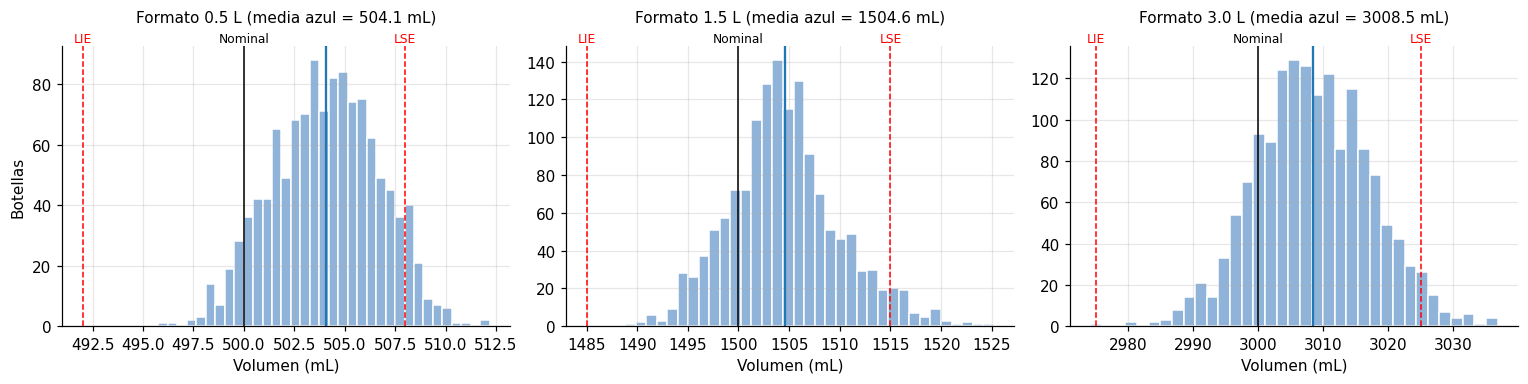

In [4]:
sub_por_comb = (llen.groupby(["linea", "formato_L", "turno"])["subgrupo"].nunique()
                    .unstack("turno"))
print("Subgrupos por línea, formato y turno (10 semanas):")
display(sub_por_comb)

resumen_llen = llen.groupby(["linea", "formato_L"])["volumen_mL"].agg(["count", "mean", "std", "min", "max"])
resumen_llen["nominal"] = esp.loc[resumen_llen.index.get_level_values("formato_L"), "nominal_mL"].values
resumen_llen["sobre_nominal_mL"] = resumen_llen["mean"] - resumen_llen["nominal"]
lim_f = esp.loc[llen["formato_L"]]
resumen_llen["%_sobre_LSE"] = pd.Series(100 * (llen["volumen_mL"].values > lim_f["LSE_mL"].values), index=llen.index).groupby([llen["linea"], llen["formato_L"]]).mean()
resumen_llen["%_bajo_LIE"] = pd.Series(100 * (llen["volumen_mL"].values < lim_f["LIE_mL"].values), index=llen.index).groupby([llen["linea"], llen["formato_L"]]).mean()
display(resumen_llen.round(2))

# Histograma de cada formato con sus especificaciones (la especificación va en el histograma, NUNCA en la carta X̄)
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (formato, d) in zip(ejes, llen.groupby("formato_L")):
    ax.hist(d["volumen_mL"], bins=35, color="#8fb3d9", edgecolor="white")
    for valor, etiqueta, color in [(esp.loc[formato, "LIE_mL"], "LIE", "red"), (esp.loc[formato, "LSE_mL"], "LSE", "red"),
                                   (esp.loc[formato, "nominal_mL"], "Nominal", "black")]:
        ax.axvline(valor, color=color, linestyle="--" if etiqueta != "Nominal" else "-", lw=1)
        ax.annotate(etiqueta, xy=(valor, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=color)
    ax.axvline(d["volumen_mL"].mean(), color="tab:blue", lw=1.5)
    ax.set_title(f"Formato {formato} L (media azul = {d['volumen_mL'].mean():.1f} mL)", pad=16, fontsize=10)
    ax.set_xlabel("Volumen (mL)")
ejes[0].set_ylabel("Botellas")
plt.tight_layout()
plt.show()

**Lectura de resultados.** L1 tiene 2 turnos (A y B, 120 subgrupos cada uno). L2 tiene 3 turnos, con
desbalance: el turno B de 1,5 L tiene 76 subgrupos contra 104 a 108 de los otros, y el B de 3,0 L tiene
124. **Las tres medias están sobre el nominal**: +4,1 mL en 0,5 L, +4,6 mL en 1,5 L y +8,5 mL en 3,0 L.
Es la primera evidencia del sobrellenado que la Parte A debe cuantificar. Los histogramas son
aproximadamente simétricos. Bajo el LIE prácticamente no hay botellas (una sola, de 3,0 L), pero **sobre el
LSE sí**: el proceso está corrido hacia arriba, y esas botellas son jarabe regalado (columna `%_sobre_LSE`).

**2.2 Cómo se compone el dato de atributos.** Cada fila es la inspección de fin de turno de una línea:
cuántas botellas se revisaron, cuántas salieron defectuosas y cuál fue la causa principal.

In [5]:
insp = atr.groupby(["linea", "turno"]).agg(inspecciones=("n_inspeccionadas", "size"),
                                           botellas=("n_inspeccionadas", "sum"),
                                           defectuosas=("n_defectuosas", "sum"))
insp["%_defectuosas"] = 100 * insp["defectuosas"] / insp["botellas"]
display(insp.round(2))

inspecciones  botellas  defectuosas  %_defectuosas
linea turno                                                        
L1    A (06-14)            30      6427          134           2.08
      B (14-22)            30      6478          114           1.76
L2    A (06-14)            50     10879          338           3.11
      B (14-22)            50     11120          346           3.11
      C (22-06)            50     10975          343           3.13

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** L1 rechaza cerca de 1,9 % de lo inspeccionado y L2 cerca de 3,1 %, con
porcentajes casi iguales entre turnos. A diferencia del llenado, la merma por atributos **no** depende del
turno. Es un primer indicio de que sus causas son distintas (sección 3.4).

**2.3 Cómo se compone el dato de demanda, y su limpieza básica.** Son 156 semanas (02/10/2023 a
21/09/2026) × 9 SKU de **ventas** en cajas. Desde aquí se fija la partición temporal: **desarrollo = semanas
1 a 143** y **prueba = 144 a 156** ($H = 13$). Todo resumen y gráfico de la demanda previo al cierre del
modelado (4.7) usa **solo el desarrollo** (corrección 2).

- **Datos faltantes.** Interpolación lineal entre la semana anterior y la siguiente. Las semanas faltantes
  (101 a 103) quedan antes de todos los orígenes de validación (≥ 109), así que no hay fuga.
- **Valores atípicos.** Cada semana se compara con su nivel local, la **mediana de las 13 semanas
  anteriores** (sin mirar el futuro). Más de `umbral_atipico` = 3 veces ese nivel no lo explica una promoción
  y se marca como **atípico de registro probable**. El valor se reemplaza por el nivel local **solo en la
  serie de entrenamiento** (`limpia`). La observación original se **conserva** (`ventas_interp`) y es contra
  ella que se mide el error de validación (corrección 3). La causa **no está confirmada**: no hay registro
  de facturación que la verifique, y así queda escrito en la bitácora.
- La limpieza es **causal**: el valor limpio de la semana $t$ depende solo de semanas $\le t$ (salvo el
  hueco 101–103, que usa la semana 104). La sección 6 lo comprueba recalculando la limpieza con los datos
  truncados en cada origen.

In [6]:
ventas = dem.pivot(index="semana", columns="sku", values="ventas_cajas")
promo = dem.pivot(index="semana", columns="sku", values="promocion")
sin_stock = dem.pivot(index="semana", columns="sku", values="dias_sin_stock")
precio_ef = dem.pivot(index="semana", columns="sku", values="precio_efectivo_clp")
precio_li = dem.pivot(index="semana", columns="sku", values="precio_lista_clp")
fechas = pd.to_datetime(dem.drop_duplicates("semana").set_index("semana")["fecha_lunes"])
mes = fechas.dt.month
skus = list(ventas.columns)

FIN_DES = int(ventas.index.max()) - CONFIG["H"]          # semana 143: fin del DESARROLLO (144-156 = PRUEBA)
print(f"Desarrollo: semanas 1 a {FIN_DES} | Prueba: semanas {FIN_DES + 1} a {ventas.index.max()}")

eda_dem = pd.DataFrame({                                  # resumen SOLO con el desarrollo
    "familia": mst.loc[skus, "familia"], "linea": mst.loc[skus, "linea_envasado"],
    "venta_media_cajas": ventas.loc[:FIN_DES].mean(), "CV": ventas.loc[:FIN_DES].std() / ventas.loc[:FIN_DES].mean(),
    "semanas_en_cero": (ventas.loc[:FIN_DES] == 0).sum(), "faltantes": ventas.loc[:FIN_DES].isna().sum(),
    "semanas_promo": promo.loc[:FIN_DES].sum(), "semanas_con_quiebre": (sin_stock.loc[:FIN_DES] > 0).sum()})
display(eda_dem.round(2))


def limpiar_ventas(v, umbral=CONFIG["umbral_atipico"]):
    """Limpieza causal de ventas. Devuelve (interpolada, limpia, máscara de atípicos, nivel local, razón).
    - interpolada: solo rellena huecos internos (observación original en todo lo demás)
    - limpia: además reemplaza los atípicos por la mediana de las 13 semanas PREVIAS"""
    interp = v.interpolate(method="linear", limit_area="inside")
    nivel = interp.shift(1).rolling(13, min_periods=7).median()
    razon = interp / nivel
    atip = (razon > umbral) & (nivel > 0)
    limpia_ = interp.mask(atip, nivel)
    return interp, limpia_, atip, nivel, razon


anomalias = []                                    # bitácora de la Parte B: qué es, cómo se detectó, qué se hizo
def anotar(sku, semana, que_es, deteccion, accion):
    anomalias.append({"sku": sku, "semana": semana, "que_es": que_es, "deteccion": deteccion, "accion": accion})

ventas_interp, limpia, atipico, nivel_local, razon = limpiar_ventas(ventas)
sin_stock_l = sin_stock.fillna(0)                 # en las semanas faltantes no hay registro de quiebre: se asume 0

faltan = ventas.isna().stack()
for sem, sku in faltan[faltan].index:
    anotar(sku, sem, "Dato faltante", "ventas_cajas y dias_sin_stock vacíos", "Interpolación lineal entre semanas vecinas")

# Justificación del umbral con el DESARROLLO: ¿cuánto sube la venta una promoción?
r_des = razon.loc[:FIN_DES].where((promo.loc[:FIN_DES] == 1) & (nivel_local.loc[:FIN_DES] > 0))
print("Razón venta / nivel local en semanas CON promoción (desarrollo), las 5 más altas:")
print(r_des.stack().dropna().sort_values().iloc[-5:].round(2))
max_promo_sin_atip = r_des.where(r_des <= CONFIG["umbral_atipico"]).max().max()
print(f"Máxima razón con promoción, sin contar los casos > {CONFIG['umbral_atipico']}: {max_promo_sin_atip:.2f}")

filas = []
for sem, sku in atipico.stack()[atipico.stack()].index:
    filas.append({"sku": sku, "semana": sem, "fecha": fechas[sem].date(), "valor_original": ventas.loc[sem, sku],
                  "promocion": promo.loc[sem, sku], "nivel_13_previas": nivel_local.loc[sem, sku],
                  "razon": razon.loc[sem, sku], "valor_entrenamiento": limpia.loc[sem, sku],
                  "causa": "No confirmada (compatible con error de digitación)", "en_prueba": sem > FIN_DES})
    anotar(sku, sem, f"Atípico probable ({ventas.loc[sem, sku]:.0f} cajas, promoción = {promo.loc[sem, sku]})",
           f"{razon.loc[sem, sku]:.1f} veces el nivel de las 13 semanas previas (con promoción no pasa de {max_promo_sin_atip:.1f})",
           "Reemplazo SOLO en la serie de entrenamiento; la validación usa la observación original; causa no confirmada")
reemplazos = pd.DataFrame(filas)
display(reemplazos.round(2))
registrar("demanda_semanal", "Valores atípicos (> 3 veces el nivel de las 13 semanas previas)",
          f"{len(reemplazos)} valores; causa no confirmada",
          "Reemplazo solo en entrenamiento; observación original conservada para validar (4.4)")
assert limpia.isna().sum().sum() == 0 and ventas_interp.isna().sum().sum() == 0, "Quedaron faltantes"
assert limpia.mask(atipico, 0).equals(ventas_interp.mask(atipico, 0)), "La limpieza tocó valores que no eran atípicos"

Desarrollo: semanas 1 a 143 | Prueba: semanas 144 a 156


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,familia,linea,venta_media_cajas,CV,semanas_en_cero,faltantes,semanas_promo,semanas_con_quiebre
sku,,,,,,,,
CIT-L05,CIT,L1,2277.88,1.18,0,0,15,1
CIT-L15,CIT,L2,2295.76,0.36,0,3,15,0
CIT-L30,CIT,L2,446.08,0.34,0,0,15,0
FUN-B05,FUN,L1,1812.23,0.37,0,0,16,0
FUN-B15,FUN,L2,1247.14,0.40,0,0,16,2
FUN-B30,FUN,L2,126.78,0.96,63,0,15,51
NEC-D05,NEC,L1,1505.85,0.26,0,0,14,0
NEC-D15,NEC,L2,2799.55,0.59,0,0,16,0
NEC-D30,NEC,L2,643.05,0.28,0,0,17,0


Razón venta / nivel local en semanas CON promoción (desarrollo), las 5 más altas:
semana  sku    
11      FUN-B05    2.38
100     FUN-B05    2.52
104     CIT-L05    2.55
62      CIT-L05    2.57
63      NEC-D15    9.35
dtype: float64
Máxima razón con promoción, sin contar los casos > 3.0: 2.57


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,semana,fecha,valor_original,promocion,nivel_13_previas,razon,valor_entrenamiento,causa,en_prueba
0,NEC-D15,63,2024-12-09,20052.0,1,2144.0,9.35,2144.0,No confirmada (compatible con error de digitac...,False
1,CIT-L05,118,2025-12-29,32916.0,0,2126.0,15.48,2126.0,No confirmada (compatible con error de digitac...,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** En el desarrollo, la razón máxima en una semana de promoción (sin contar los
atípicos) es 2,57: el umbral de 3 queda sobre todo lo que una promoción explica. Se detectan **dos atípicos
probables**: **NEC-D15, semana 63** (20.052 cajas, 9,4 veces su nivel, con promoción) y **CIT-L05, semana 118**
(32.916 cajas sin promoción, 15,5 veces su nivel). Ambos son compatibles con un error de digitación (un dígito
de más), pero **la causa no está confirmada**: se reemplazan solo en la serie de entrenamiento y la
observación original queda en `ventas_interp` para medir el error de validación (4.4). Ninguno cae en la
prueba. El CV de 1,18 de CIT-L05 se debe solo a ese valor. En el desarrollo, FUN-B30 tiene 63 semanas en cero
y 51 con quiebre de stock: es el SKU problemático de la Parte B.

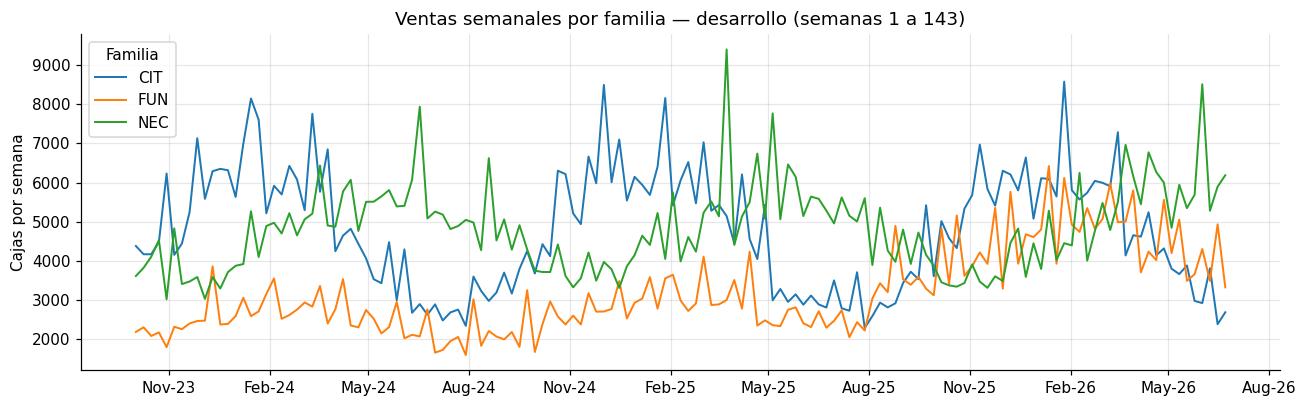

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,archivo,chequeo,resultado,decision
0,calidad_llenado,Valores faltantes,0 celdas vacías,Sin acción
1,calidad_llenado,"Duplicados (subgrupo, n_obs)",0 duplicados,Sin acción
2,calidad_llenado,Tamaño de subgrupo,n = [5] en 840 subgrupos,n = 5 constante: se usan las constantes de la ...
3,calidad_llenado,"Subgrupos que mezclan línea, SKU o turno",máximo 1 valor distinto por subgrupo,Sin acción: los subgrupos son racionales
4,calidad_llenado,Volúmenes ≤ 0,0 valores,Sin acción
5,calidad_llenado,"Subgrupos por línea, formato y turno","mínimo 76, máximo 124",Se reporta el desbalance; la capacidad por tur...
6,calidad_atributos,Valores faltantes,0 celdas vacías,Sin acción
7,calidad_atributos,Filas duplicadas,0 duplicados,Sin acción
8,calidad_atributos,Defectuosas > inspeccionadas,0 filas,Sin acción
9,calidad_atributos,Tamaño de inspección n,entre 181 y 260,n varía: carta p con límites variables (no np)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [7]:
# Vista agregada del DESARROLLO: ventas por familia (suma de sus 3 SKU), serie limpia
familia_de = mst["familia"]
familias = sorted(familia_de.unique())
skus_de = {f: [s for s in skus if familia_de[s] == f] for f in familias}

fig, ax = plt.subplots(figsize=(12, 3.8))
for f in familias:
    ax.plot(fechas.loc[:FIN_DES], limpia.loc[:FIN_DES, skus_de[f]].sum(axis=1), label=f, lw=1.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set(title="Ventas semanales por familia — desarrollo (semanas 1 a 143)", ylabel="Cajas por semana")
ax.legend(title="Familia")
plt.tight_layout()
plt.show()
display(pd.DataFrame(bitacora))

**Lectura de resultados.** Las familias no se mueven juntas. **CIT** y **FUN** tienen su peak en verano
(diciembre a febrero) y su valle en invierno. **NEC** tiene la forma contraria: sube en otoño e invierno
(abril a junio) y baja en primavera, coherente con el calendario escolar (colaciones). FUN además muestra
un **salto de nivel** a mediados de 2025. Estas dos observaciones, fases estacionales opuestas y un quiebre
estructural, condicionan toda la Parte B.



## 3. Parte A — Control estadístico y capacidad de proceso

### 3.1 Cartas X̄–R por línea × formato, Fase I y Fase II

**Qué carta usar.** Todos los subgrupos tienen $n = 5$. Con $n \le 10$ el rango $R$ estima la dispersión casi
tan bien como $S$ y es más simple: corresponde la **carta X̄–R**. Constantes para $n = 5$: $A_2 = 0{,}577$,
$D_3 = 0$, $D_4 = 2{,}114$, $d_2 = 2{,}326$.

$$LCS_{\bar X} = \bar{\bar x} + A_2 \bar R,\qquad LCI_{\bar X} = \bar{\bar x} - A_2 \bar R,\qquad
LCS_R = D_4 \bar R,\qquad \hat\sigma = \bar R / d_2$$

**Fase I y Fase II.** En la Fase I (semanas 1 a 5) se calculan los límites; en la Fase II (6 a 10) se juzgan
los subgrupos contra esos límites **congelados**, que nunca se recalculan con la Fase II.

**Criterio de exclusión (corrección 3).** La práctica estándar excluye un subgrupo de Fase I solo si se
identifica su **causa asignable**. Aquí no hay registros de operación que la confirmen, así que la exclusión
se trata como una **decisión provisional y documentada**: (i) cada subgrupo excluido queda registrado con la
ronda, el criterio que violó y los límites vigentes; (ii) su estado de causa es *no confirmada*; (iii) se
revisa la **representatividad temporal** de lo que queda; (iv) se informa la **sensibilidad** de límites,
señales y capacidad **con y sin exclusión** (3.3); y (v) se reportan las señales que **persisten** en la Fase I
depurada (3.2). La Fase I no se califica de estable solo por haber removido alarmas.

**Orden temporal.** Las mediciones de 00, 02 y 04 h del turno C (22–06) vienen con la fecha de inicio del
turno; se les suma un día. Con esa corrección, el orden en el tiempo coincide con el número de subgrupo.

In [8]:
A2, D3, D4, d2 = 0.577, 0, 2.114, 2.326          # constantes de la carta X̄–R para n = 5
N = CONFIG["n_subgrupo"]
FASE1 = CONFIG["semanas_fase1"]

g = llen.groupby("subgrupo")
sg = g.agg(fecha=("fecha", "first"), hora=("hora", "first"), semana=("semana_registro", "first"),
           turno=("turno", "first"), linea=("linea", "first"), formato=("formato_L", "first"), sku=("sku", "first"))
sg["xbar"] = g["volumen_mL"].mean()
sg["R"] = g["volumen_mL"].max() - g["volumen_mL"].min()
sg = sg.reset_index()

sg["fecha_hora"] = pd.to_datetime(sg["fecha"] + " " + sg["hora"])
madrugada = sg["turno"].str.startswith("C") & (sg["fecha_hora"].dt.hour < 6)
sg.loc[madrugada, "fecha_hora"] += pd.Timedelta(days=1)        # el turno C registra con la fecha de inicio
sg["instancia_turno"] = sg["fecha"] + " " + sg["turno"].str[0]  # un turno concreto (para errores agrupados, 3.2)
sg["fase"] = np.where(sg["semana"] <= FASE1, "I", "II")
orden_coincide = all(d.sort_values("fecha_hora")["subgrupo"].is_monotonic_increasing for _, d in sg.groupby(["linea", "formato"]))
assert orden_coincide, "El orden temporal no coincide con el número de subgrupo"
registrar("calidad_llenado", "Fecha de las mediciones de madrugada del turno C",
          f"{int(madrugada.sum())} subgrupos (00, 02 y 04 h) con la fecha de inicio del turno",
          "Se suma 1 día: el orden temporal queda igual al número de subgrupo (afecta las reglas de rachas)")

cartas = [("L1", 0.5), ("L2", 1.5), ("L2", 3.0)]
print(sg.groupby(["linea", "formato", "fase"]).size().unstack())
sg.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


fase             I   II
linea formato          
L1    0.5      120  120
L2    1.5      136  152
      3.0      164  148


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,subgrupo,fecha,hora,semana,turno,linea,formato,sku,xbar,R,fecha_hora,instancia_turno,fase
0,1,2026-07-20,06:00,1,A (06-14),L1,0.5,FUN-B05,501.560,4.01,2026-07-20 06:00:00,2026-07-20 A,I
1,2,2026-07-20,08:00,1,A (06-14),L1,0.5,FUN-B05,501.752,5.17,2026-07-20 08:00:00,2026-07-20 A,I
2,3,2026-07-20,10:00,1,A (06-14),L1,0.5,FUN-B05,503.630,4.13,2026-07-20 10:00:00,2026-07-20 A,I
3,4,2026-07-20,12:00,1,A (06-14),L1,0.5,FUN-B05,503.172,2.10,2026-07-20 12:00:00,2026-07-20 A,I
4,5,2026-07-20,14:00,1,B (14-22),L1,0.5,CIT-L05,503.396,8.49,2026-07-20 14:00:00,2026-07-20 B,I


**Función de Fase I.** Repite rondas hasta que no quede ningún punto fuera y devuelve los límites
congelados, el registro de rondas y **cada subgrupo excluido con el criterio que violó y los límites vigentes
en esa ronda**. Se calcula además una versión **sin ninguna exclusión** (`lims_sin`) para la sensibilidad de 3.3.

In [9]:
def limites_fase1(c, excluir=True):
    """Límites X̄–R con la Fase I. Si `excluir`, saca por rondas los subgrupos fuera de límites y REGISTRA
    cada exclusión (ronda, criterio violado y límites vigentes en esa ronda)."""
    f1 = c[c["fase"] == "I"].copy()
    rondas, excl = [], []
    while True:
        xbb, Rb = f1["xbar"].mean(), f1["R"].mean()
        LCSx, LCIx, LCSr = xbb + A2 * Rb, xbb - A2 * Rb, D4 * Rb
        criterio = pd.Series("", index=f1.index)
        criterio[f1["xbar"] > LCSx] += "X̄ > LCS; "
        criterio[f1["xbar"] < LCIx] += "X̄ < LCI; "
        criterio[f1["R"] > LCSr] += "R > LCS_R; "
        fuera = criterio != ""
        rondas.append({"ronda": len(rondas) + 1, "subgrupos": len(f1), "x_doble_barra": xbb, "R_barra": Rb,
                       "LCS_X": LCSx, "LCI_X": LCIx, "LCS_R": LCSr, "puntos_fuera": int(fuera.sum())})
        if not fuera.any() or not excluir:
            break
        excl.append(f1[fuera].assign(ronda=len(rondas), criterio=criterio[fuera].str.rstrip("; "),
                                     LCS_X_ronda=LCSx, LCI_X_ronda=LCIx, LCS_R_ronda=LCSr))
        f1 = f1[~fuera]
    lim = {"xbb": xbb, "Rb": Rb, "LCSx": LCSx, "LCIx": LCIx, "LCSr": LCSr, "LCIr": D3 * Rb, "sigma": Rb / d2,
           "subgrupos_estables": f1["subgrupo"].tolist()}
    return lim, pd.DataFrame(rondas), (pd.concat(excl) if excl else c.iloc[0:0].copy())


def preparar_carta(linea, formato):
    c = sg[(sg["linea"] == linea) & (sg["formato"] == formato)].sort_values("fecha_hora").reset_index(drop=True)
    c["orden"] = c.index + 1
    return c


lims, lims_sin, datos_carta, resumen, excluidos_todos = {}, {}, {}, [], []
for linea, formato in cartas:
    c = preparar_carta(linea, formato)
    lim, rondas, excl = limites_fase1(c, excluir=CONFIG["excluir_fase1"])
    lims_sin[(linea, formato)] = limites_fase1(c, excluir=False)[0]       # sensibilidad: sin ninguna exclusión
    assert c[c["subgrupo"].isin(lim["subgrupos_estables"])]["semana"].max() <= FASE1     # sin fuga de Fase II
    c["fuera_x"] = (c["xbar"] > lim["LCSx"]) | (c["xbar"] < lim["LCIx"])
    c["fuera_r"] = (c["R"] > lim["LCSr"]) | (c["R"] < lim["LCIr"])
    c["excluido_fase1"] = (c["fase"] == "I") & ~c["subgrupo"].isin(lim["subgrupos_estables"])
    lims[(linea, formato)], datos_carta[(linea, formato)] = lim, c
    excluidos_todos.append(excl.assign(carta=f"{linea} {formato} L"))
    f2 = c[c["fase"] == "II"]
    resumen.append([linea, formato, (c["fase"] == "I").sum(), len(excl), len(rondas), lim["xbb"], lim["Rb"],
                    lim["LCSx"], lim["LCIx"], lim["LCSr"], lim["sigma"], f2["fuera_x"].sum(), f2["fuera_r"].sum(), len(f2)])
    print(f"\n{linea} {formato} L — rondas de Fase I")
    display(rondas.round(2))

res = pd.DataFrame(resumen, columns=["linea", "formato", "n_fase1", "excluidos", "rondas", "xbb", "Rb", "LCSx", "LCIx",
                                     "LCSr", "sigma", "f2_fuera_x", "f2_fuera_r", "n_fase2"])
excluidos_df = pd.concat(excluidos_todos, ignore_index=True)
print("\nLímites congelados de Fase I y resultado de la Fase II")
display(res.round(3))


L1 0.5 L — rondas de Fase I


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ronda,subgrupos,x_doble_barra,R_barra,LCS_X,LCI_X,LCS_R,puntos_fuera
0,1,120,502.47,4.86,505.27,499.66,10.28,0



L2 1.5 L — rondas de Fase I


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ronda,subgrupos,x_doble_barra,R_barra,LCS_X,LCI_X,LCS_R,puntos_fuera
0,1,136,1504.55,12.01,1511.48,1497.62,25.39,5
1,2,131,1504.35,11.57,1511.03,1497.67,24.47,1
2,3,130,1504.30,11.56,1510.97,1497.63,24.44,0


... (2 outputs left out)

,ronda,subgrupos,x_doble_barra,R_barra,LCS_X,LCI_X,LCS_R,puntos_fuera
0,1,164,3008.89,19.81,3020.32,2997.46,41.89,6
1,2,158,3008.73,19.16,3019.78,2997.67,40.50,0



Límites congelados de Fase I y resultado de la Fase II


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,linea,formato,n_fase1,excluidos,rondas,xbb,Rb,LCSx,LCIx,LCSr,sigma,f2_fuera_x,f2_fuera_r,n_fase2
0,L1,0.5,120,0,1,502.467,4.863,505.274,499.661,10.281,2.091,91,0,120
1,L2,1.5,136,6,3,1504.296,11.559,1510.966,1497.626,24.436,4.970,6,4,152
2,L2,3.0,164,6,2,3008.725,19.159,3019.780,2997.671,40.502,8.237,0,2,148


**Lectura de resultados.**
- **L1 0,5 L.** Ningún punto fuera en la Fase I (una ronda, sin exclusiones): $\bar{\bar x}$ = 502,47 mL,
  $\bar R$ = 4,86 mL, $\hat\sigma$ = 2,09 mL y límites [499,66; 505,27]. En la Fase II, **91 de 120 subgrupos
  quedan sobre el LCS** y ninguno fuera en la carta R: cambió la **media**, no la variabilidad.
- **L2 1,5 L.** 3 rondas y 6 subgrupos excluidos, **todos del turno C (22 a 06 h)**: 4 por rango sobre el
  $LCS_R$ y 2 por media sobre el $LCS$. En la Fase II hay 6 puntos fuera en X̄ y 4 en R.
- **L2 3,0 L.** 2 rondas y 6 excluidos (5 del turno C y 1 del B; 4 por rango y 2 por media). En la Fase II hay
  0 puntos fuera en X̄ y 2 en R.

Que casi todos los excluidos sean del turno nocturno es una **pista**, no una prueba: la exclusión es una
decisión provisional, documentada abajo y sometida a sensibilidad en 3.3.

**Trazabilidad de las exclusiones.** Cada subgrupo excluido queda con su ronda, el criterio que violó, los
límites vigentes en esa ronda, el turno y el SKU. La «causa probable» es solo una **hipótesis** que sale del
contraste por turno de 3.2. Su estado es *no confirmada*, porque los datos no traen registros de operación,
mantención ni cambios de ajuste. La tabla de representatividad muestra si, al excluir, la Fase I deja de
representar a algún turno o semana.

In [10]:
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
traza = excluidos_df.copy()
traza["dia"] = traza["fecha_hora"].dt.dayofweek.map(dict(enumerate(DIAS)))
traza["causa_probable (hipótesis)"] = np.where(traza["turno"].str.startswith("C"),
                                               "Práctica de llenado del turno nocturno (ver 3.2)", "Sin patrón identificado")
traza["estado_causa"] = "NO confirmada: sin registro de operación en los datos"
traza["decision"] = "Fuera del cálculo de límites; se conserva en datos y en la sensibilidad (3.3)"
cols_traza = ["carta", "ronda", "criterio", "orden", "fecha_hora", "dia", "semana", "turno", "sku", "xbar", "R",
              "LCS_X_ronda", "LCI_X_ronda", "LCS_R_ronda", "causa_probable (hipótesis)", "estado_causa", "decision"]
print("Registro de exclusiones de Fase I")
display(traza.reindex(columns=cols_traza).round({c: 2 for c in ["xbar", "R", "LCS_X_ronda", "LCI_X_ronda", "LCS_R_ronda"]}))
traza.reindex(columns=cols_traza).to_csv(os.path.join(R, "registro_exclusiones_fase1.csv"), index=False)
registrar("calidad_llenado", "Exclusiones de Fase I", f"{len(traza)} subgrupos ({traza['turno'].str[0].value_counts().to_dict()})",
          "Registradas con criterio y ronda; causa no confirmada; sensibilidad con/sin exclusión en 3.3")

rep = []
for (l, f), c in datos_carta.items():
    f1 = c[c["fase"] == "I"]
    for conjunto, d in [("Fase I completa", f1), ("Fase I tras exclusión", f1[~f1["excluido_fase1"]])]:
        fila = {"carta": f"{l} {f} L", "conjunto": conjunto, "subgrupos": len(d), "semanas": d["semana"].nunique()}
        fila.update({f"% turno {t[0]}": 100 * (d["turno"] == t).mean() for t in sorted(c["turno"].unique())})
        rep.append(fila)
print("Representatividad temporal: composición por turno antes y después de excluir")
display(pd.DataFrame(rep).round(1))
print("Subgrupos excluidos por semana de Fase I")
display(traza.pivot_table(index="carta", columns="semana", values="subgrupo", aggfunc="count", fill_value=0))

Registro de exclusiones de Fase I


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,carta,ronda,criterio,orden,fecha_hora,dia,semana,turno,sku,xbar,R,LCS_X_ronda,LCI_X_ronda,LCS_R_ronda,causa_probable (hipótesis),estado_causa,decision
0,L2 1.5 L,1.0,R > LCS_R,1,2026-07-20 22:00:00,lunes,1,C (22-06),NEC-D15,1505.64,25.95,1511.48,1497.62,25.39,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
1,L2 1.5 L,1.0,X̄ > LCS,29,2026-07-28 22:00:00,martes,2,C (22-06),NEC-D15,1513.75,9.26,1511.48,1497.62,25.39,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
2,L2 1.5 L,1.0,R > LCS_R,77,2026-08-07 22:00:00,viernes,3,C (22-06),FUN-B15,1510.72,28.13,1511.48,1497.62,25.39,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
3,L2 1.5 L,1.0,R > LCS_R,78,2026-08-08 00:00:00,sábado,3,C (22-06),FUN-B15,1510.65,27.57,1511.48,1497.62,25.39,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
4,L2 1.5 L,1.0,R > LCS_R,80,2026-08-08 04:00:00,sábado,3,C (22-06),FUN-B15,1508.44,26.43,1511.48,1497.62,25.39,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
5,L2 1.5 L,2.0,X̄ > LCS,91,2026-08-11 02:00:00,martes,4,C (22-06),NEC-D15,1511.32,13.43,1511.03,1497.67,24.47,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
6,L2 3.0 L,1.0,X̄ > LCS,21,2026-07-22 22:00:00,miércoles,1,C (22-06),FUN-B30,3023.59,21.08,3020.32,2997.46,41.89,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
7,L2 3.0 L,1.0,R > LCS_R,75,2026-08-04 02:00:00,martes,3,C (22-06),FUN-B30,3010.47,43.43,3020.32,2997.46,41.89,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
8,L2 3.0 L,1.0,X̄ > LCS,108,2026-08-12 04:00:00,miércoles,4,C (22-06),FUN-B30,3021.06,20.58,3020.32,2997.46,41.89,Práctica de llenado del turno nocturno (ver 3.2),NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...
9,L2 3.0 L,1.0,R > LCS_R,148,2026-08-19 20:00:00,miércoles,5,B (14-22),CIT-L30,3008.44,42.19,3020.32,2997.46,41.89,Sin patrón identificado,NO confirmada: sin registro de operación en lo...,Fuera del cálculo de límites; se conserva en d...


Representatividad temporal: composición por turno antes y después de excluir


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,carta,conjunto,subgrupos,semanas,% turno A,% turno B,% turno C
0,L1 0.5 L,Fase I completa,120,5,50.0,50.0,NaN
1,L1 0.5 L,Fase I tras exclusión,120,5,50.0,50.0,NaN
2,L2 1.5 L,Fase I completa,136,5,47.1,17.6,35.3
3,L2 1.5 L,Fase I tras exclusión,130,5,49.2,18.5,32.3
4,L2 3.0 L,Fase I completa,164,5,22.0,46.3,31.7
5,L2 3.0 L,Fase I tras exclusión,158,5,22.8,47.5,29.7


Subgrupos excluidos por semana de Fase I


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


semana,1,2,3,4,5
carta,,,,,
L2 1.5 L,1,1,3,1,0
L2 3.0 L,1,0,1,1,3


**Lectura de resultados.** Las 12 exclusiones son de L2 (6 por carta): 11 del turno C y 1 del turno B
(CIT-L30, 19/08 a las 20:00, por rango). 8 son por rango sobre el $LCS_R$ y 4 por media sobre el $LCS$. Se
reparten en las cinco semanas de la Fase I (1,5 L: 1-1-3-1-0; 3,0 L: 1-0-1-1-3), así que no vacían ninguna
semana, y la Fase I depurada sigue representando a los tres turnos: la proporción del turno C baja de 35,3 % a
32,3 % en 1,5 L y de 31,7 % a 29,7 % en 3,0 L. Como ninguna causa está confirmada, estas exclusiones son un
**supuesto de cálculo**, no una corrección del proceso.

**Gráficos.** Cada carta muestra la Fase I y la Fase II separadas por la línea vertical, con los límites
congelados de Fase I. Los puntos rojos están fuera de los límites. Las etiquetas de los límites van en el
margen derecho para que no tapen los datos.

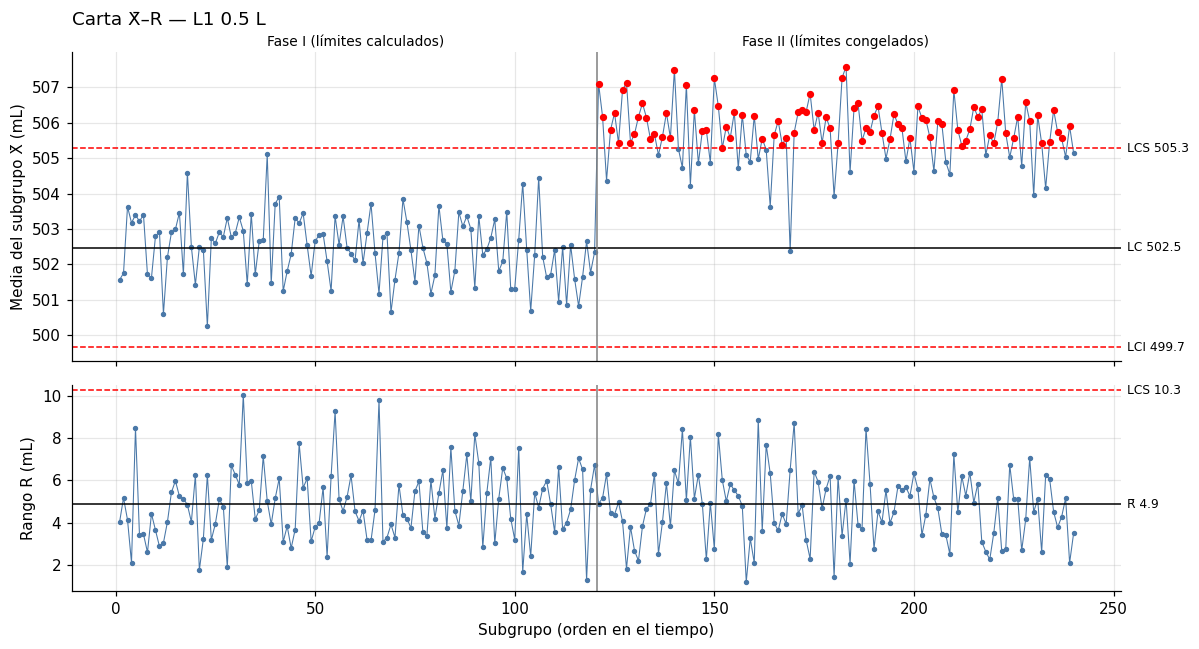

In [11]:
def graficar_xr(linea, formato):
    c, lim = datos_carta[(linea, formato)], lims[(linea, formato)]
    corte = c.loc[c["fase"] == "I", "orden"].max() + 0.5
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    ax[0].plot(c["orden"], c["xbar"], "o-", ms=2.5, lw=0.7, color="#4a78a8")
    ax[0].scatter(c.loc[c["fuera_x"], "orden"], c.loc[c["fuera_x"], "xbar"], color="red", s=14, zorder=5)
    for y, nombre in [(lim["LCSx"], "LCS"), (lim["xbb"], "LC"), (lim["LCIx"], "LCI")]:
        ax[0].axhline(y, color="black" if nombre == "LC" else "red", ls="-" if nombre == "LC" else "--", lw=1)
        ax[0].text(1.005, y, f"{nombre} {y:.1f}", transform=ax[0].get_yaxis_transform(), va="center", fontsize=8)
    ax[1].plot(c["orden"], c["R"], "o-", ms=2.5, lw=0.7, color="#4a78a8")
    ax[1].scatter(c.loc[c["fuera_r"], "orden"], c.loc[c["fuera_r"], "R"], color="red", s=14, zorder=5)
    for y, nombre in [(lim["LCSr"], "LCS"), (lim["Rb"], "R̄")]:
        ax[1].axhline(y, color="red" if nombre == "LCS" else "black", ls="--" if nombre == "LCS" else "-", lw=1)
        ax[1].text(1.005, y, f"{nombre} {y:.1f}", transform=ax[1].get_yaxis_transform(), va="center", fontsize=8)
    for a in ax:
        a.axvline(corte, color="gray", lw=1)
    ax[0].text(corte / 2, 1.02, "Fase I (límites calculados)", transform=ax[0].get_xaxis_transform(), ha="center", fontsize=9)
    ax[0].text((corte + c["orden"].max()) / 2, 1.02, "Fase II (límites congelados)", transform=ax[0].get_xaxis_transform(),
               ha="center", fontsize=9)
    ax[0].set_ylabel("Media del subgrupo X̄ (mL)")
    ax[0].set_title(f"Carta X̄–R — {linea} {formato} L", loc="left", pad=18)
    ax[1].set(xlabel="Subgrupo (orden en el tiempo)", ylabel="Rango R (mL)")
    plt.tight_layout()
    plt.show()

graficar_xr("L1", 0.5)

**Lectura de resultados.** El quiebre es nítido. Desde el primer subgrupo de la semana 6 (lunes
24/08/2026) la media salta a ≈ 505,7 mL y se queda ahí. La carta R no cambia: la dispersión es la misma
antes y después. Es el patrón típico de un **cambio de ajuste (setpoint) de la llenadora**, no de desgaste,
que aumentaría el rango.

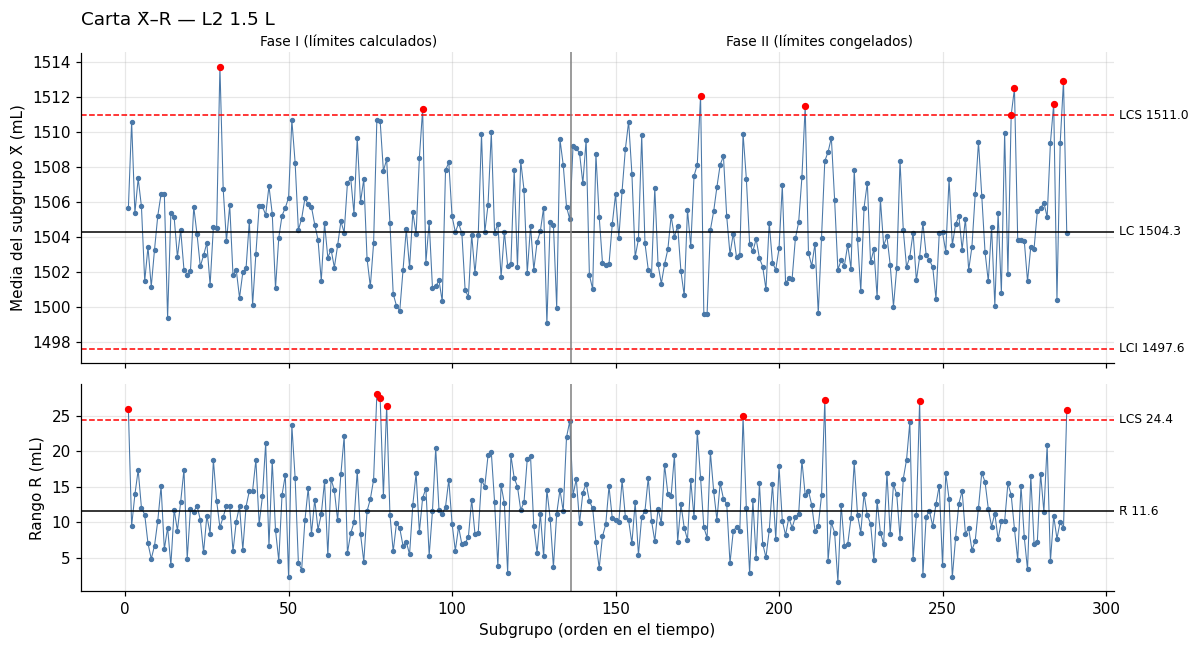

In [12]:
graficar_xr("L2", 1.5)

**Lectura de resultados.** No hay un cambio de nivel entre fases. Hay puntos dispersos sobre el LCS y
rangos altos que se repiten durante todo el periodo. Es un proceso «bajo control» en el sentido estrecho
(pocas señales), pero con una fuente de variación recurrente: el turno C, como se verá en 3.2.

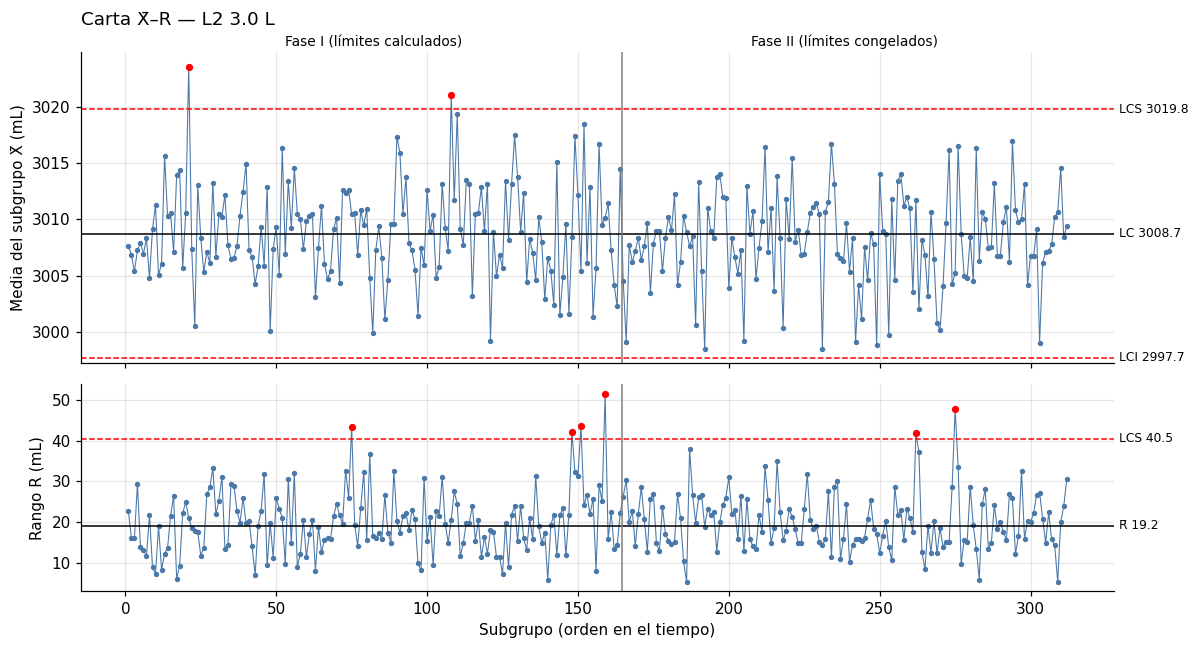

In [13]:
graficar_xr("L2", 3.0)

**Lectura de resultados.** Es la carta más estable. En la Fase II ninguna media sale de los límites y solo
dos rangos superan el LCS. Que esté bajo control no significa que sea capaz: los límites de control reflejan
la variación del proceso, no la especificación (sección 3.3).

### 3.2 Reglas de decisión (Western Electric) y causas asignables

Un punto fuera de los límites no es la única señal. Las **reglas de Western Electric** buscan patrones
que serían muy poco probables si solo actuaran causas comunes. Se aplican sobre la media estandarizada
con los parámetros congelados de Fase I:

$$z_i = \frac{\bar x_i - \bar{\bar x}}{\hat\sigma/\sqrt{n}}$$

| Regla | Señal | Detecta |
|---|---|---|
| R1 | 1 punto a más de 3σ | salto grande |
| R2 | 2 de 3 puntos seguidos a más de 2σ, del mismo lado | corrimiento moderado |
| R3 | 4 de 5 puntos seguidos a más de 1σ, del mismo lado | corrimiento pequeño sostenido |
| R4 | 8 puntos seguidos del mismo lado de la LC | cambio de nivel persistente |
| R alta | rango sobre $LCS_R$ | aumento de la variabilidad |

In [14]:
def reglas_we(z):
    r1 = z.abs() > 3
    r2 = ((z > 2).astype(int).rolling(3).sum() >= 2) | ((z < -2).astype(int).rolling(3).sum() >= 2)
    r3 = ((z > 1).astype(int).rolling(5).sum() >= 4) | ((z < -1).astype(int).rolling(5).sum() >= 4)
    r4 = ((z > 0).astype(int).rolling(8).sum() == 8) | ((z < 0).astype(int).rolling(8).sum() == 8)
    return r1, r2, r3, r4

def aplicar_we(c, lim):
    c = c.copy()
    c["z"] = (c["xbar"] - lim["xbb"]) / (lim["sigma"] / np.sqrt(N))
    c["R1"], c["R2"], c["R3"], c["R4"] = reglas_we(c["z"])
    c["R_alta"] = c["R"] > lim["LCSr"]
    c["senal"] = c[["R1", "R2", "R3", "R4", "R_alta"]].any(axis=1)
    return c

senales, filas = {}, []
for linea, formato in cartas:
    lim = lims[(linea, formato)]
    c = aplicar_we(datos_carta[(linea, formato)], lim)
    senales[(linea, formato)] = c
    # Fase I DEPURADA: se recalculan las reglas sobre la secuencia sin los excluidos (¿persisten señales?)
    dep = aplicar_we(c[(c["fase"] == "I") & ~c["excluido_fase1"]].reset_index(drop=True), lim)
    for fase, d in [("I", c[c["fase"] == "I"]), ("I depurada", dep), ("II", c[c["fase"] == "II"])]:
        filas.append([f"{linea} {formato} L", fase, len(d), d["R1"].sum(), d["R2"].sum(), d["R3"].sum(),
                      d["R4"].sum(), d["R_alta"].sum(), d["senal"].sum(), 100 * d["senal"].mean()])

tabla_we = pd.DataFrame(filas, columns=["carta", "fase", "subgrupos", "R1", "R2", "R3", "R4", "R alta",
                                        "con señal", "% con señal"])
display(tabla_we.round(1))
persisten = tabla_we[tabla_we["fase"] == "I depurada"].set_index("carta")["con señal"]
print("Señales que PERSISTEN en la Fase I depurada (no se califica de estable solo por remover alarmas):")
print(persisten.to_string())

,carta,fase,subgrupos,R1,R2,R3,R4,R alta,con señal,% con señal
0,L1 0.5 L,I,120,0,0,0,2,0,2,1.7
1,L1 0.5 L,I depurada,120,0,0,0,2,0,2,1.7
2,L1 0.5 L,II,120,91,119,117,105,0,120,100.0
3,L2 1.5 L,I,136,2,2,4,4,4,14,10.3
4,L2 1.5 L,I depurada,130,0,0,2,4,0,6,4.6
5,L2 1.5 L,II,152,6,18,6,2,4,25,16.4
6,L2 3.0 L,I,164,2,1,1,1,4,9,5.5
7,L2 3.0 L,I depurada,158,0,1,1,1,0,3,1.9
8,L2 3.0 L,II,148,0,3,2,1,2,8,5.4


Señales que PERSISTEN en la Fase I depurada (no se califica de estable solo por remover alarmas):
carta
L1 0.5 L    2
L2 1.5 L    6
L2 3.0 L    3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** En **L1** el **100 % de los subgrupos de Fase II** activa alguna regla (R1 = 91,
R2 = 119, R3 = 117, R4 = 105): es un corrimiento sostenido. En **L2 1,5 L** las señales suben de 10,3 % (Fase I) a
16,4 % (Fase II), repartidas entre R1, R2 y rango alto. En **L2 3,0 L** se mantienen bajas (≈ 5,5 %).

**Señales que persisten en la Fase I depurada** (corrección 3): 2 en L1 (R4), 6 en L2 1,5 L (R3 y R4) y 3 en L2
3,0 L. Quitar los puntos fuera de límites **no** elimina las rachas, que apuntan al mismo efecto del turno C.
Por eso la Fase I de L2 se califica como **estable con reservas**: sin puntos fuera de límites, pero con patrones
no aleatorios. Sus límites sirven como referencia operativa para juzgar la Fase II, no como prueba de un
proceso libre de causas especiales.

**Contraste con los campos disponibles (turno, semana, SKU).** Para proponer una causa asignable hay que
ver *dónde* se concentran las señales. Una causa que actúa en todas las semanas de Fase II, en todos los
turnos y en todos los SKU apunta a la máquina o a su ajuste. Una causa que aparece en un solo turno apunta
a la operación de ese turno.

In [15]:
todos = pd.concat([d.assign(carta=f"{l} {f} L") for (l, f), d in senales.items()], ignore_index=True)

print("Media de X̄ por semana (mL) — la Fase I son las semanas 1 a 5")
display(todos.pivot_table(index="carta", columns="semana", values="xbar", aggfunc="mean").round(1))
print("Subgrupos con señal por semana")
display(todos.pivot_table(index="carta", columns="semana", values="senal", aggfunc="sum"))

por_turno = todos.groupby(["carta", "fase", "turno"]).agg(subgrupos=("senal", "size"), con_senal=("senal", "sum"),
                                                          xbar_medio=("xbar", "mean"), R_medio=("R", "mean"))
por_turno["%_con_senal"] = 100 * por_turno["con_senal"] / por_turno["subgrupos"]
print("Señales, media y rango por carta, fase y turno")
display(por_turno.round(2))

por_sku = todos.groupby(["carta", "sku"]).agg(subgrupos=("senal", "size"), con_senal=("senal", "sum"),
                                              xbar_medio=("xbar", "mean"), R_medio=("R", "mean"))
por_sku["%_con_senal"] = 100 * por_sku["con_senal"] / por_sku["subgrupos"]
print("Señales por SKU")
display(por_sku.round(2))

Media de X̄ por semana (mL) — la Fase I son las semanas 1 a 5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


semana,1,2,3,4,5,6,7,8,9,10
carta,,,,,,,,,,
L1 0.5 L,502.5,502.8,502.5,502.5,502.1,505.9,505.6,505.9,505.7,505.6
L2 1.5 L,1504.3,1504.6,1505.4,1504.0,1504.7,1505.8,1504.6,1504.2,1503.6,1505.3
L2 3.0 L,3009.1,3008.2,3008.7,3010.7,3008.4,3007.7,3008.5,3007.8,3007.8,3008.7


Subgrupos con señal por semana


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


semana,1,2,3,4,5,6,7,8,9,10
carta,,,,,,,,,,
L1 0.5 L,0,2,0,0,0,24,24,24,24,24
L2 1.5 L,1,1,8,4,0,8,4,3,2,8
L2 3.0 L,2,0,1,2,4,2,0,3,3,0


... (2 outputs left out)

subgrupos  con_senal  xbar_medio  R_medio  %_con_senal
carta    fase turno                                                            
L1 0.5 L I    A (06-14)         60          0      502.38     4.81         0.00
              B (14-22)         60          2      502.56     4.92         3.33
         II   A (06-14)         60         60      505.67     4.89       100.00
              B (14-22)         60         60      505.77     4.59       100.00
L2 1.5 L I    A (06-14)         64          5     1503.29    10.31         7.81
              B (14-22)         24          0     1503.31    11.09         0.00
              C (22-06)         48          9     1506.86    14.74        18.75
         II   A (06-14)         44          4     1503.00    10.18         9.09
              B (14-22)         52          1     1503.76    10.61         1.92
              C (22-06)         56         20     1506.76    13.25        35.71
L2 3.0 L I    A (06-14)         36          1     3007.56    18.72         2.78
              B (14-22)         76          2     3007.83    17.79         2.63
              C (22-06)         52          6     3011.35    23.53        11.54
         II   A (06-14)         56          3     3007.29    19.45         5.36
              B (14-22)         48          3     3007.40    19.68         6.25
              C (22-06)         44          2     3009.80    21.73         4.55

Señales por SKU


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


subgrupos  con_senal  xbar_medio  R_medio  %_con_senal
carta    sku                                                            
L1 0.5 L CIT-L05         96         42      503.86     5.06        43.75
         FUN-B05         64         32      504.05     5.02        50.00
         NEC-D05         80         48      504.41     4.32        60.00
L2 1.5 L CIT-L15         88          9     1503.63    10.74        10.23
         FUN-B15        104         21     1505.34    12.34        20.19
         NEC-D15         96          9     1504.69    11.94         9.38
L2 3.0 L CIT-L30        136          7     3007.88    19.32         5.15
         FUN-B30         80          6     3009.30    19.44         7.50
         NEC-D30         96          4     3008.71    21.43         4.17

**Lectura de resultados (contraste con turno, semana y SKU).**
- **L1:** la media pasa de ≈ 502,5 mL (semanas 1 a 5) a ≈ 505,7 mL (semanas 6 a 10). Las cinco semanas de la
  Fase II tienen 24 de 24 subgrupos con señal, **en ambos turnos por igual** (A: 505,67; B: 505,77) y en los
  **tres SKU**. Un efecto que no distingue turno ni producto y empieza en una fecha precisa es **compatible
  con** una intervención sobre la máquina, como un reajuste del setpoint de L1 el 24/08/2026. Es una
  **hipótesis**: se confirma o se descarta con la bitácora de mantención y de cambios de ajuste de esa fecha.
- **L2:** las señales se concentran en el **turno C**: en 1,5 L el 80 % de las señales de Fase II son de ese turno,
  que llena en promedio 1.506,8 mL contra 1.503,0 y 1.503,8 de A y B, con rangos más altos (≈ 13 a 15 mL contra
  ≈ 10 a 11). En 3,0 L el turno C también es el más alto (3.011 mL en Fase I) y el más disperso. **Hipótesis:**
  una práctica de ajuste propia del turno nocturno («llenar de más por seguridad»), menor supervisión o
  recalibraciones al inicio del turno. Los datos muestran **dónde** está la diferencia, no **por qué**.
- Las diferencias por SKU de L2 pueden ser un efecto del turno (CIT-L15 casi no se envasa de noche). La celda
  siguiente lo separa.

**¿Es el turno o es el SKU? Y una cautela sobre independencia.** En L2 los SKU no se reparten igual entre
turnos, así que un «efecto SKU» podría ser el efecto del turno. Se ajusta un ANOVA de dos factores
(turno + SKU) sobre $\bar x$ en la Fase I depurada. El ANOVA supone **observaciones independientes**, y
subgrupos tomados cada 2 horas dentro de un mismo turno podrían estar correlacionados (mismo operador, mismo
ajuste), lo que volvería optimistas los p-valores. Por eso: (i) se mide la autocorrelación de los residuos en
el orden temporal (lag 1 y Ljung-Box) y (ii) se repite el contraste con **errores agrupados por instancia de
turno** (cada turno de cada día es un grupo). El rango se compara con Kruskal-Wallis (no es normal).

In [16]:
# ANOVA de dos factores (turno + SKU) sobre X̄ en la Fase I depurada, con dos cautelas (cátedra):
#  (1) independencia: autocorrelación de los residuos en el orden temporal (lag 1 y Ljung-Box);
#  (2) contraste robusto: los mismos términos con errores AGRUPADOS por instancia de turno, que admiten
#      correlación entre subgrupos de un mismo turno.
filas = []
for linea, formato in cartas:
    c = senales[(linea, formato)]
    est = c[(c["fase"] == "I") & ~c["excluido_fase1"]].sort_values("fecha_hora").reset_index(drop=True)
    m_ols = ols("xbar ~ C(turno) + C(sku)", data=est).fit()
    tabla = anova_lm(m_ols, typ=2)
    grupos = pd.factorize(est["instancia_turno"])[0]
    m_cl = ols("xbar ~ C(turno) + C(sku)", data=est).fit(cov_type="cluster", cov_kwds={"groups": grupos})
    wald = m_cl.wald_test_terms(skip_single=False, scalar=True).table
    resid = m_ols.resid
    filas.append({"carta": f"{linea} {formato} L", "subgrupos": len(est), "instancias_turno": len(np.unique(grupos)),
                  "p turno (ANOVA OLS)": tabla.loc["C(turno)", "PR(>F)"], "p SKU (ANOVA OLS)": tabla.loc["C(sku)", "PR(>F)"],
                  "p turno (errores agrupados)": wald.loc["C(turno)", "pvalue"], "p SKU (errores agrupados)": wald.loc["C(sku)", "pvalue"],
                  "p turno, rango (Kruskal-Wallis)": stats.kruskal(*[gr["R"] for _, gr in est.groupby("turno")]).pvalue,
                  "autocorr. residuos lag 1": resid.autocorr(1),
                  "p Ljung-Box (lag 6)": acorr_ljungbox(resid, lags=[6])["lb_pvalue"].iloc[0]})
anova = pd.DataFrame(filas)
display(anova.round(4))

c = senales[("L2", 1.5)]
print("L2 1,5 L, Fase I: media de X̄ por SKU y turno")
display(c[c["fase"] == "I"].pivot_table(index="sku", columns="turno", values="xbar", aggfunc="mean").round(1))

,carta,subgrupos,instancias_turno,p turno (ANOVA OLS),p SKU (ANOVA OLS),p turno (errores agrupados),p SKU (errores agrupados),"p turno, rango (Kruskal-Wallis)",autocorr. residuos lag 1,p Ljung-Box (lag 6)
0,L1 0.5 L,120,30,0.1038,0.3381,0.0900,0.1410,0.7789,-0.0042,0.1229
1,L2 1.5 L,130,34,0.0000,0.3544,0.0000,0.2193,0.0024,0.0118,0.6906
2,L2 3.0 L,158,41,0.0000,0.3059,0.0001,0.3350,0.0027,-0.0533,0.8612


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


L2 1,5 L, Fase I: media de X̄ por SKU y turno


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


turno,A (06-14),B (14-22),C (22-06)
sku,,,
CIT-L15,1503.0,1503.3,NaN
FUN-B15,1503.8,1503.6,1506.9
NEC-D15,1503.2,1502.7,1506.8


**Lectura de resultados.** Con turno y SKU en el mismo modelo, el **turno es significativo** en ambas cartas
de L2 (p < 0,0001 con OLS y p ≤ 0,0001 con errores agrupados por instancia de turno), en la media y en el rango
(Kruskal-Wallis p ≈ 0,002 a 0,003). El **SKU no lo es** (p = 0,22 a 0,35). **Independencia:** la autocorrelación
de los residuos es casi nula (lag 1 entre −0,05 y 0,01; Ljung-Box p ≥ 0,12) y el contraste agrupado lleva a la
misma conclusión: la dependencia entre subgrupos no está inflando la significancia. En L1 ni turno ni SKU son
significativos (p ≥ 0,09).

**Alcance (cátedra).** Estos contrastes muestran una **asociación estadística** entre el turno C y un llenado
más alto y disperso. **No demuestran una causa física**: sirven para priorizar dónde verificar (registro de
ajustes de la llenadora por turno, observación del arranque del turno C, entrevistas a operadores), no para
reemplazar esa verificación.

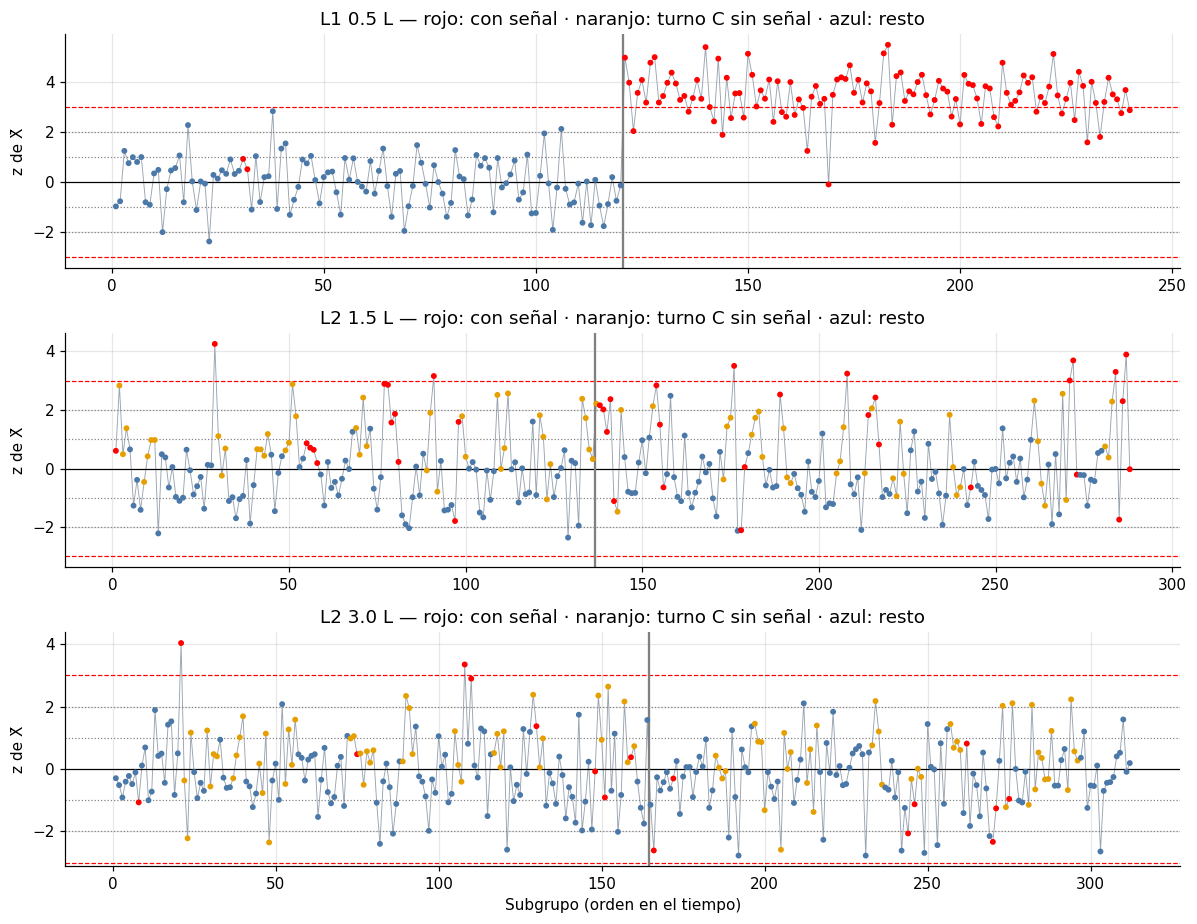

In [17]:
# Gráfico de z con las zonas de 1, 2 y 3 sigma (rojo = subgrupo con alguna señal)
fig, ejes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=False)
for ax, (linea, formato) in zip(ejes, cartas):
    c = senales[(linea, formato)]
    ax.plot(c["orden"], c["z"], "-", color="#9aa5b1", lw=0.6)
    colores = np.where(c["senal"], "red", np.where(c["turno"].str.startswith("C"), "#e69f00", "#4a78a8"))
    ax.scatter(c["orden"], c["z"], c=colores, s=8, zorder=3)
    for zl, est in [(3, "--"), (2, ":"), (1, ":")]:
        ax.axhline(zl, color="red" if zl == 3 else "gray", ls=est, lw=0.8)
        ax.axhline(-zl, color="red" if zl == 3 else "gray", ls=est, lw=0.8)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(c.loc[c["fase"] == "I", "orden"].max() + 0.5, color="gray")
    ax.set(ylabel="z de X̄", title=f"{linea} {formato} L — rojo: con señal · naranjo: turno C sin señal · azul: resto")
ejes[-1].set_xlabel("Subgrupo (orden en el tiempo)")
plt.tight_layout()
plt.show()

In [18]:
# Tabla de causas asignables: se agrupan las señales y se contrastan con semana, turno y SKU
causas = (todos[todos["senal"]].groupby(["carta", "fase"])
          .agg(subgrupos_con_senal=("senal", "size"),
               semanas=("semana", lambda s: sorted(s.unique().tolist())),
               turno_mas_frecuente=("turno", lambda s: s.value_counts().index[0]),
               pct_en_ese_turno=("turno", lambda s: round(100 * s.value_counts().iloc[0] / len(s), 1)),
               skus=("sku", "nunique"),
               z_medio=("z", "mean")))
display(causas.round(2))

subgrupos_con_senal           semanas turno_mas_frecuente  pct_en_ese_turno  skus  z_medio
carta    fase                                                                                            
L1 0.5 L I                       2               [2]           B (14-22)             100.0     1     0.72
         II                    120  [6, 7, 8, 9, 10]           A (06-14)              50.0     3     3.48
L2 1.5 L I                      14      [1, 2, 3, 4]           C (22-06)              64.3     3     1.40
         II                     25  [6, 7, 8, 9, 10]           C (22-06)              80.0     3     1.45
L2 3.0 L I                       9      [1, 3, 4, 5]           C (22-06)              66.7     3     1.16
         II                      8         [6, 8, 9]           A (06-14)              37.5     3    -1.23

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** El gráfico z y la tabla resumen la **hipótesis de causa asignable** de cada carta:

| Carta | Señal | Dónde se concentra | Hipótesis de causa asignable | Verificación requerida | Acción si se confirma |
|---|---|---|---|---|---|
| L1 0,5 L | Corrimiento +3,25 mL desde el 24/08 (R1 a R4) | Todas las semanas de Fase II, ambos turnos, 3 SKU | Reajuste del setpoint de la llenadora L1 | Bitácora de mantención y de cambios de setpoint del 24/08 | Recentrar la media (barato) |
| L2 1,5 L | Puntos y rangos altos recurrentes | Turno C (80 % de las señales de Fase II) | Práctica de llenado del turno nocturno | Registro de ajustes por turno; observación del arranque del turno C | Estandarizar el ajuste y la supervisión del turno C |
| L2 3,0 L | Pocas señales, rangos altos ocasionales | Turno C en Fase I (67 % de las señales) | Mismo patrón nocturno, más débil | Ídem | Igual que 1,5 L |

### 3.3 Capacidad de proceso: Cp, Cpk, Pp y Ppk (global y por turno), normalidad y límite legal

La capacidad solo tiene sentido en un **proceso estable**. Por eso los índices se calculan con los
subgrupos de la **Fase I estable** (los que quedaron dentro de los límites). Se usan dos sigmas:

- **Cp y Cpk** usan la $\sigma$ de *corto plazo* $= \bar R/d_2$, la variación dentro del subgrupo. Miden
  lo que el proceso *puede* hacer.
- **Pp y Ppk** usan la $\sigma$ de *largo plazo* (desviación estándar de todas las botellas). Miden lo que
  el proceso *hace* realmente.

$$C_p = \frac{LSE-LIE}{6\sigma},\qquad C_{pk}=\frac{\min(LSE-\mu,\ \mu-LIE)}{3\sigma}$$

Si Cp ≈ Cpk el proceso está centrado. Si Cp > Cpk está **descentrado**: el problema es la **media**.
Si Cp < 1,33 el problema es la **variabilidad**: aunque se centre, no cabe en la tolerancia.

In [19]:
def indices(d, LIE, LSE):
    """Cp, Cpk (sigma corto plazo = R̄/d2) y Pp, Ppk (sigma largo plazo) de un conjunto de botellas."""
    grupos = d.groupby("subgrupo")["volumen_mL"]
    mu = d["volumen_mL"].mean()
    s_c = (grupos.max() - grupos.min()).mean() / d2
    s_l = d["volumen_mL"].std(ddof=1)
    return {"subgrupos": grupos.ngroups, "media": mu, "sigma_corto": s_c, "sigma_largo": s_l,
            "Cp": (LSE - LIE) / (6 * s_c), "Cpk": min(LSE - mu, mu - LIE) / (3 * s_c),
            "Pp": (LSE - LIE) / (6 * s_l), "Ppk": min(LSE - mu, mu - LIE) / (3 * s_l)}

capacidades, desempeno = [], []
for linea, formato in cartas:
    LIE, LSE = esp.loc[formato, "LIE_mL"], esp.loc[formato, "LSE_mL"]
    d1 = llen[llen["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]          # Fase I estable
    d2_ = llen[(llen["linea"] == linea) & (llen["formato_L"] == formato) & (llen["semana_registro"] > FASE1)]
    capacidades.append({"linea": linea, "formato": formato, "grupo": "Global", **indices(d1, LIE, LSE)})
    desempeno.append({"linea": linea, "formato": formato, "grupo": "Global", **indices(d2_, LIE, LSE)})
    for turno in sorted(d1["turno"].unique()):
        capacidades.append({"linea": linea, "formato": formato, "grupo": turno, **indices(d1[d1["turno"] == turno], LIE, LSE)})
        desempeno.append({"linea": linea, "formato": formato, "grupo": turno, **indices(d2_[d2_["turno"] == turno], LIE, LSE)})

tabla_cap = pd.DataFrame(capacidades)
tabla_cap["Cp/Cpk"] = tabla_cap["Cp"] / tabla_cap["Cpk"]
print("CAPACIDAD — Fase I estable (proceso bajo control)")
display(tabla_cap.round(2))

tabla_f2 = pd.DataFrame(desempeno)[["linea", "formato", "grupo", "subgrupos", "media", "sigma_largo", "Pp", "Ppk"]]
print("DESEMPEÑO — Fase II (solo Pp y Ppk: si el proceso no está bajo control, Cp y Cpk no aplican)")
display(tabla_f2.round(2))

CAPACIDAD — Fase I estable (proceso bajo control)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,linea,formato,grupo,subgrupos,media,sigma_corto,sigma_largo,Cp,Cpk,Pp,Ppk,Cp/Cpk
0,L1,0.5,Global,120,502.47,2.09,2.06,1.28,0.88,1.30,0.90,1.45
1,L1,0.5,A (06-14),60,502.38,2.07,2.01,1.29,0.91,1.33,0.93,1.42
2,L1,0.5,B (14-22),60,502.56,2.12,2.10,1.26,0.86,1.27,0.86,1.47
3,L2,1.5,Global,130,1504.30,4.97,5.15,1.01,0.72,0.97,0.69,1.40
4,L2,1.5,A (06-14),64,1503.29,4.43,4.44,1.13,0.88,1.12,0.88,1.28
5,L2,1.5,B (14-22),24,1503.31,4.77,4.53,1.05,0.82,1.10,0.86,1.28
6,L2,1.5,C (22-06),42,1506.40,5.90,5.82,0.85,0.49,0.86,0.49,1.74
7,L2,3.0,Global,158,3008.73,8.24,8.43,1.01,0.66,0.99,0.64,1.54
8,L2,3.0,A (06-14),36,3007.56,8.05,8.29,1.04,0.72,1.01,0.70,1.43
9,L2,3.0,B (14-22),75,3007.83,7.51,7.61,1.11,0.76,1.10,0.75,1.46


DESEMPEÑO — Fase II (solo Pp y Ppk: si el proceso no está bajo control, Cp y Cpk no aplican)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,linea,formato,grupo,subgrupos,media,sigma_largo,Pp,Ppk
0,L1,0.5,Global,120,505.72,2.02,1.32,0.38
1,L1,0.5,A (06-14),60,505.67,2.08,1.28,0.37
2,L1,0.5,B (14-22),60,505.77,1.95,1.36,0.38
3,L2,1.5,Global,152,1504.65,5.37,0.93,0.64
4,L2,1.5,A (06-14),44,1503.00,4.40,1.14,0.91
5,L2,1.5,B (14-22),52,1503.76,4.51,1.11,0.83
6,L2,1.5,C (22-06),56,1506.76,6.07,0.82,0.45
7,L2,3.0,Global,148,3008.07,8.82,0.95,0.64
8,L2,3.0,A (06-14),56,3007.29,8.45,0.99,0.70
9,L2,3.0,B (14-22),48,3007.40,8.33,1.00,0.70


**Lectura de resultados.**
- **L1 0,5 L:** Cp = 1,28 y Cpk = 0,88 en la Fase I. La razón Cp/Cpk = 1,45 indica un **problema de media**: el
  proceso cabe casi en la tolerancia, pero está corrido 2,5 mL hacia el LSE. En la Fase II la media sube a
  505,7 mL y el **Ppk cae a 0,38** con el Pp intacto (1,32). Ambos turnos son prácticamente iguales.
- **L2 1,5 L y 3,0 L:** Cp = 1,01 en ambos. **Aunque se centraran perfectamente no llegarían a Cpk = 1,33**,
  porque Cpk nunca supera a Cp: es un **problema de variabilidad**. Cpk = 0,72 y 0,66.
- **Por turno**, el **turno C** es el peor en los dos formatos de L2: Cpk = 0,49, con la media más alta *y* la σ
  más grande (5,9 mL contra 4,4 a 4,8 en 1,5 L).
- σ de corto y de largo plazo son muy parecidas (2,09 contra 2,06 en L1): dentro de la Fase I depurada no hay
  variación adicional entre subgrupos. Cp ≈ Pp lo confirma.

**Sensibilidad con y sin exclusión (corrección 3).** Se recalcula todo lo que depende de la Fase I con dos
versiones de los límites: la base (con las exclusiones registradas en 3.1) y una sin ninguna exclusión. Si las
conclusiones (qué carta está fuera de control y cuál es incapaz) no cambian, la decisión de excluir no
determina el diagnóstico.

In [20]:
filas = []
for linea, formato in cartas:
    LIE, LSE = esp.loc[formato, "LIE_mL"], esp.loc[formato, "LSE_mL"]
    c = datos_carta[(linea, formato)]
    for version, lim in [("Con exclusión (base)", lims[(linea, formato)]), ("Sin exclusión", lims_sin[(linea, formato)])]:
        cc = aplicar_we(c, lim)
        f2 = cc[cc["fase"] == "II"]
        ind = indices(llen[llen["subgrupo"].isin(lim["subgrupos_estables"])], LIE, LSE)
        filas.append({"carta": f"{linea} {formato} L", "version": version, "subgrupos_fase1": len(lim["subgrupos_estables"]),
                      "xbb": lim["xbb"], "sigma_corto": lim["sigma"], "LCS_X": lim["LCSx"], "LCI_X": lim["LCIx"], "LCS_R": lim["LCSr"],
                      "F2 fuera X̄": int(((f2["xbar"] > lim["LCSx"]) | (f2["xbar"] < lim["LCIx"])).sum()),
                      "F2 fuera R": int((f2["R"] > lim["LCSr"]).sum()), "F2 % con señal WE": 100 * f2["senal"].mean(),
                      "Cp": ind["Cp"], "Cpk": ind["Cpk"]})
sensibilidad_fase1 = pd.DataFrame(filas)
display(sensibilidad_fase1.round(3))
cambio = sensibilidad_fase1.groupby("carta")[["Cp", "Cpk", "F2 % con señal WE"]].agg(lambda s: s.iloc[1] - s.iloc[0])
print("Diferencia (sin exclusión − con exclusión):")
display(cambio.round(3))

,carta,version,subgrupos_fase1,xbb,sigma_corto,LCS_X,LCI_X,LCS_R,F2 fuera X̄,F2 fuera R,F2 % con señal WE,Cp,Cpk
0,L1 0.5 L,Con exclusión (base),120,502.467,2.091,505.274,499.661,10.281,91,0,100.000,1.275,0.882
1,L1 0.5 L,Sin exclusión,120,502.467,2.091,505.274,499.661,10.281,91,0,100.000,1.275,0.882
2,L2 1.5 L,Con exclusión (base),130,1504.296,4.970,1510.966,1497.626,24.436,6,4,16.447,1.006,0.718
3,L2 1.5 L,Sin exclusión,136,1504.551,5.164,1511.482,1497.621,25.391,5,3,11.184,0.968,0.674
4,L2 3.0 L,Con exclusión (base),158,3008.725,8.237,3019.780,2997.671,40.502,0,2,5.405,1.012,0.659
5,L2 3.0 L,Sin exclusión,164,3008.888,8.519,3020.321,2997.455,41.888,0,1,6.757,0.978,0.630


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Diferencia (sin exclusión − con exclusión):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Cp,Cpk,F2 % con señal WE
carta,,,
L1 0.5 L,0.000,0.000,0.000
L2 1.5 L,-0.038,-0.043,-5.263
L2 3.0 L,-0.033,-0.028,1.351


**Lectura de resultados.** En L1 no hubo exclusiones, así que las dos versiones coinciden. En L2, **sin
exclusión** los límites se abren un poco ($LCS_{\bar X}$ 1.511,5 contra 1.511,0 mL en 1,5 L) y la σ de corto
plazo sube 4 % (1,5 L) y 3 % (3,0 L). Cp baja de 1,01 a 0,97–0,98 y Cpk de 0,72 a 0,67 (1,5 L) y de 0,66 a 0,63
(3,0 L). Las señales de Fase II cambian poco (1,5 L: 16,4 % → 11,2 %; 3,0 L: 5,4 % → 6,8 %). **Ninguna conclusión
cambia**: L1 está fuera de control por un corrimiento de la media y L2 es predecible pero incapaz (Cp < 1,33) en
las dos versiones. La exclusión vuelve los índices de L2 **algo más optimistas**, así que el caso base no
exagera la incapacidad.

**Normalidad.** Cp, Cpk y la conversión a PPM suponen que el volumen es aproximadamente normal. Se
verifica con Shapiro-Wilk, asimetría y curtosis, y con gráficos QQ. Con cientos de botellas, Shapiro-Wilk
rechaza desviaciones pequeñas sin importancia práctica. Por eso se lee junto con la asimetría y la
curtosis (cerca de 0 = normal) y con el QQ.

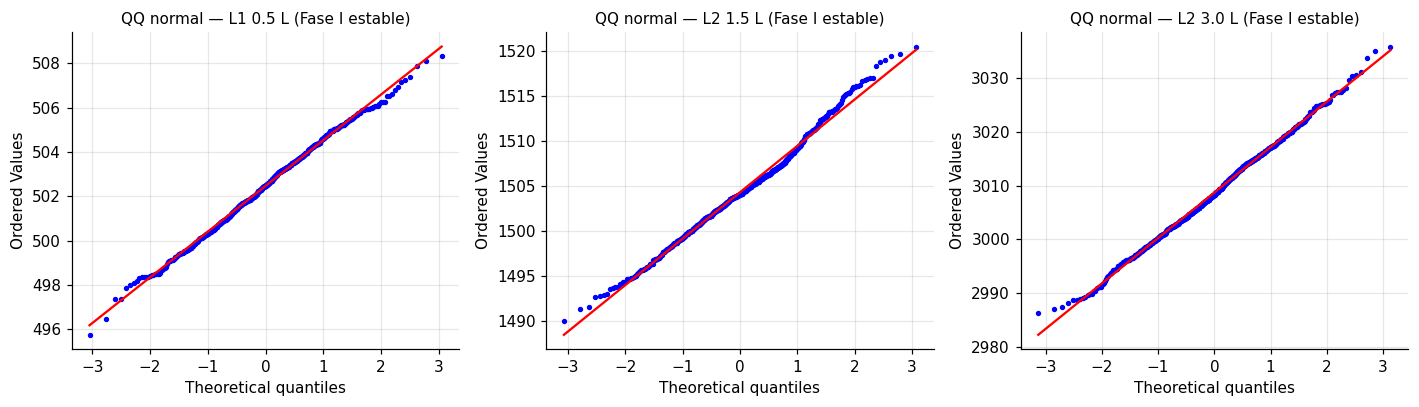

,carta,botellas,p_Shapiro,asimetria,curtosis_exceso
0,L1 0.5 L,600,0.511,-0.066,-0.268
1,L2 1.5 L,650,0.001,0.281,0.196
2,L2 3.0 L,790,0.333,0.090,-0.138


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
filas = []
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (linea, formato) in zip(ejes, cartas):
    x = llen[llen["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]["volumen_mL"]
    filas.append([f"{linea} {formato} L", len(x), stats.shapiro(x).pvalue, stats.skew(x), stats.kurtosis(x)])
    stats.probplot(x, dist="norm", plot=ax)
    ax.get_lines()[0].set_markersize(2.5)
    ax.set_title(f"QQ normal — {linea} {formato} L (Fase I estable)", fontsize=10)
plt.tight_layout()
plt.show()

normalidad = pd.DataFrame(filas, columns=["carta", "botellas", "p_Shapiro", "asimetria", "curtosis_exceso"])
display(normalidad.round(3))

**Lectura de resultados.** En L1 (p = 0,51) y L2 3,0 L (p = 0,33) no se rechaza la normalidad. En L2 1,5 L
sí se rechaza (p = 0,001), pero la desviación es pequeña: asimetría 0,28 y curtosis 0,20, y el QQ es casi
recto con una cola derecha algo más larga. Esa leve asimetría a la derecha es la **mezcla de turnos**: el
turno C llena más alto. Los índices de capacidad son una buena aproximación. Del lado inferior (el que
importa para el límite legal) el riesgo está bien representado, y la cola superior real es algo más pesada
de lo que supone la normal, lo que refuerza el diagnóstico de sobrellenado.

**Límite legal (OIML R87).** La norma de preenvasados no mira la especificación de ingeniería sino la
*cantidad nominal* $Q_n$ y la deficiencia tolerable $T$ (15 mL en 0,5 L; 22,5 mL en 1,5 L; 45 mL en 3,0 L).
Exige tres criterios: (1) la media del lote ≥ $Q_n$; (2) a lo más un 2,5 % de botellas bajo $Q_n - T$
(error T1); (3) ninguna botella bajo $Q_n - 2T$ (error T2). Se verifica con **todas** las mediciones,
por línea × formato y también por turno.

In [22]:
filas = []
for linea, formato in cartas:
    nominal, T = esp.loc[formato, "nominal_mL"], esp.loc[formato, "tolerancia_oiml_mL"]
    d = llen[(llen["linea"] == linea) & (llen["formato_L"] == formato)]
    for grupo, x in [("Global", d["volumen_mL"])] + [(t, g["volumen_mL"]) for t, g in d.groupby("turno")]:
        t1 = ((x < nominal - T) & (x >= nominal - 2 * T)).sum()
        t2 = (x < nominal - 2 * T).sum()
        cumple = (x.mean() >= nominal) and (100 * t1 / len(x) <= 2.5) and (t2 == 0)
        filas.append([linea, formato, grupo, len(x), x.mean(), x.min(), nominal - T, x.min() - (nominal - T),
                      t1, 100 * t1 / len(x), t2, cumple])

tabla_legal = pd.DataFrame(filas, columns=["linea", "formato", "grupo", "botellas", "media", "minimo", "limite_T1",
                                           "margen_minimo", "error_T1", "%_T1", "error_T2", "cumple_R87"])
display(tabla_legal.round(2))

,linea,formato,grupo,botellas,media,minimo,limite_T1,margen_minimo,error_T1,%_T1,error_T2,cumple_R87
0,L1,0.5,Global,1200,504.09,495.76,485.0,10.76,0,0.0,0,True
1,L1,0.5,A (06-14),600,504.02,495.76,485.0,10.76,0,0.0,0,True
2,L1,0.5,B (14-22),600,504.16,496.48,485.0,11.48,0,0.0,0,True
3,L2,1.5,Global,1440,1504.60,1488.80,1477.5,11.30,0,0.0,0,True
4,L2,1.5,A (06-14),540,1503.17,1491.52,1477.5,14.02,0,0.0,0,True
5,L2,1.5,B (14-22),380,1503.62,1491.30,1477.5,13.80,0,0.0,0,True
6,L2,1.5,C (22-06),520,1506.81,1488.80,1477.5,11.30,0,0.0,0,True
7,L2,3.0,Global,1560,3008.50,2974.20,2955.0,19.20,0,0.0,0,True
8,L2,3.0,A (06-14),460,3007.40,2981.15,2955.0,26.15,0,0.0,0,True
9,L2,3.0,B (14-22),620,3007.67,2980.36,2955.0,25.36,0,0.0,0,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** **Las tres combinaciones cumplen OIML R87**, globalmente y en cada turno: la
media supera al nominal, no hay ninguna botella con error T1 ni T2 y la botella más baja queda 10,8 mL
(0,5 L), 11,3 mL (1,5 L) y 19,2 mL (3,0 L) por sobre el límite legal $Q_n - T$. **El riesgo legal no es el
problema de BdM.** El LIE interno (492 mL en 0,5 L) es más exigente que el límite legal (485 mL), y la planta
llena con un margen que excede ambos. La merma que ve Finanzas es **económica**, no legal.

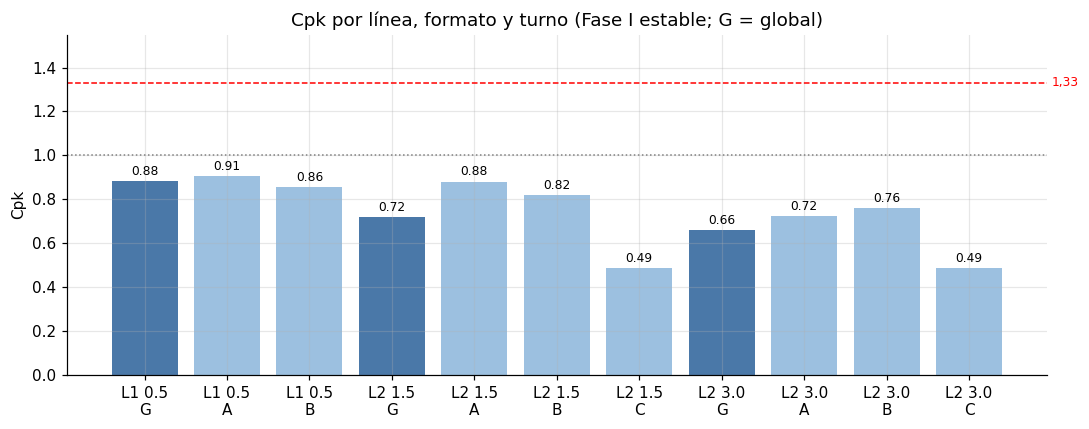

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
etiquetas = tabla_cap["linea"] + " " + tabla_cap["formato"].astype(str) + "\n" + tabla_cap["grupo"].str[:1]
colores = np.where(tabla_cap["grupo"] == "Global", "#4a78a8", "#9cc0e0")
barras = ax.bar(etiquetas, tabla_cap["Cpk"], color=colores)
ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(CONFIG["cpk_objetivo"], color="red", ls="--", lw=1)
ax.text(1.005, CONFIG["cpk_objetivo"], "1,33", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="red")
ax.axhline(1, color="gray", ls=":", lw=1)
ax.set(ylabel="Cpk", title="Cpk por línea, formato y turno (Fase I estable; G = global)", ylim=(0, 1.55))
plt.tight_layout()
plt.show()

**Respuesta a la pregunta de decisión: ¿se puede estar bajo control y ser incapaz?** **Sí, y BdM tiene los
dos casos.**
- **L2 (1,5 y 3,0 L) está bajo control estadístico, con reservas**: sin puntos fuera de límites en la Fase I
  depurada, pocas señales en la Fase II y sin cambio de nivel, aunque persisten rachas ligadas al turno C. Aun
  así es **incapaz**: Cp = 1,01 y Cpk de 0,66 a 0,72. El control dice que el proceso es *predecible*; la capacidad
  dice que lo predecible **no cabe en la especificación**. La acción ataca la **variabilidad**: homologar el
  turno C con A y B y luego mantener las válvulas de llenado. Para llegar a Cp = 1,33 hay que **reducir σ ≈ 24 %**.
  Es la acción más cara y lenta.
- **L1 era casi capaz (Cp = 1,28) pero descentrado** (Cpk = 0,88), y desde el 24/08 además está **fuera de
  control** por un corrimiento de la media (Ppk = 0,38). Recentrar es barato y recupera casi todo el sobrellenado
  de L1, pero **no basta para la meta de capacidad**: con Cp = 1,28 el mejor Cpk posible es 1,28 (3.5).

### 3.4 Carta p (atributos) y Pareto de causas

**¿p o np?** La carta np exige el mismo tamaño de inspección en cada muestra. Aquí $n$ varía entre 181
y 260 botellas, así que corresponde la **carta p** con límites que cambian con cada $n_i$:

$$LC = \bar p,\qquad LCS_i = \bar p + 3\sqrt{\frac{\bar p(1-\bar p)}{n_i}},\qquad
LCI_i = \max\!\left(0,\ \bar p - 3\sqrt{\frac{\bar p(1-\bar p)}{n_i}}\right)$$

Se usa la **misma disciplina de fases** que en la carta X̄–R: $\bar p$ se calcula con las semanas 1 a 5
(sacando los puntos fuera hasta estabilizar), se congela y se juzgan las semanas 6 a 10. Así un episodio
de Fase II no infla los límites que deben detectarlo.

,linea,inspeccionadas,defectuosas,%_defectuosas_total,p_barra_FaseI_%,excluidos_FaseI,fuera_FaseII,semanas_fuera
0,L1,12905,248,1.92,1.86,0,0,[]
1,L2,32974,1027,3.11,2.61,0,12,"[6, 8]"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


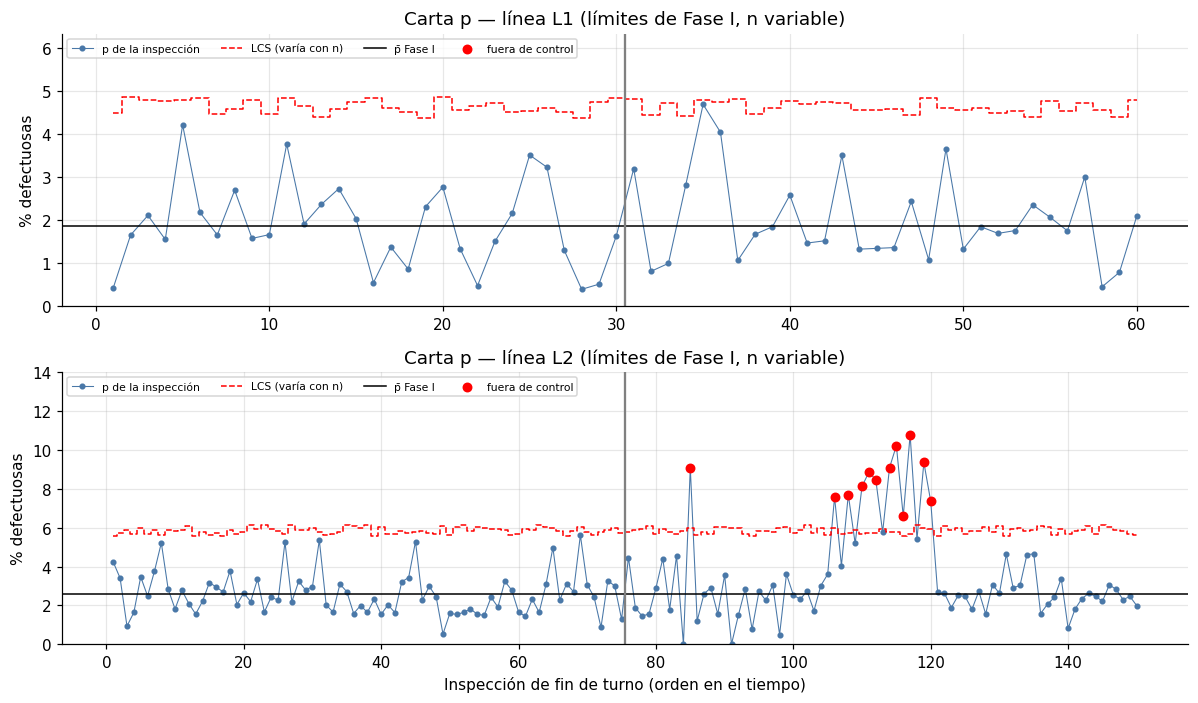

In [24]:
cartas_p, resumen_p = {}, []
for linea_nom, datos in atr.groupby("linea"):
    datos = datos.sort_values(["fecha", "turno"]).reset_index(drop=True)
    datos["orden"] = datos.index + 1
    datos["p"] = datos["n_defectuosas"] / datos["n_inspeccionadas"]
    datos["fase"] = np.where(datos["semana_registro"] <= FASE1, "I", "II")

    f1 = datos[datos["fase"] == "I"]
    while True:                                                  # Fase I iterativa
        p_bar = f1["n_defectuosas"].sum() / f1["n_inspeccionadas"].sum()
        e = np.sqrt(p_bar * (1 - p_bar) / f1["n_inspeccionadas"])
        fuera = (f1["p"] > p_bar + 3 * e) | (f1["p"] < np.maximum(0, p_bar - 3 * e))
        if fuera.sum() == 0:
            break
        f1 = f1[~fuera]
    datos["en_fase1_usada"] = datos.index.isin(f1.index)     # inspecciones de Fase I con que se calculó p̄

    e = np.sqrt(p_bar * (1 - p_bar) / datos["n_inspeccionadas"])
    datos["p_bar"] = p_bar
    datos["LCS"], datos["LCI"] = p_bar + 3 * e, np.maximum(0, p_bar - 3 * e)
    datos["fuera"] = (datos["p"] > datos["LCS"]) | (datos["p"] < datos["LCI"])
    cartas_p[linea_nom] = datos
    resumen_p.append([linea_nom, datos["n_inspeccionadas"].sum(), datos["n_defectuosas"].sum(),
                      100 * datos["n_defectuosas"].sum() / datos["n_inspeccionadas"].sum(), 100 * p_bar,
                      (datos["fase"] == "I").sum() - len(f1), datos.loc[datos["fase"] == "II", "fuera"].sum(),
                      sorted(datos.loc[datos["fuera"], "semana_registro"].unique().tolist())])

tabla_p = pd.DataFrame(resumen_p, columns=["linea", "inspeccionadas", "defectuosas", "%_defectuosas_total",
                                           "p_barra_FaseI_%", "excluidos_FaseI", "fuera_FaseII", "semanas_fuera"])
display(tabla_p.round(2))

fig, ejes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, (linea_nom, datos) in zip(ejes, cartas_p.items()):
    ax.plot(datos["orden"], 100 * datos["p"], "o-", ms=3, lw=0.7, color="#4a78a8", label="p de la inspección")
    ax.step(datos["orden"], 100 * datos["LCS"], where="mid", color="red", ls="--", lw=1, label="LCS (varía con n)")
    ax.axhline(100 * datos["p_bar"].iloc[0], color="black", lw=1, label="p̄ Fase I")
    f = datos[datos["fuera"]]
    ax.scatter(f["orden"], 100 * f["p"], color="red", s=30, zorder=5, label="fuera de control")
    ax.axvline(datos.loc[datos["fase"] == "I", "orden"].max() + 0.5, color="gray")
    ax.set(ylabel="% defectuosas", title=f"Carta p — línea {linea_nom} (límites de Fase I, n variable)")
    ax.set_ylim(0, 100 * max(datos["p"].max(), datos["LCS"].max()) * 1.3)     # espacio para la leyenda
    ax.legend(fontsize=7, loc="upper left", ncol=4)
ejes[-1].set_xlabel("Inspección de fin de turno (orden en el tiempo)")
plt.tight_layout()
plt.show()

**Lectura de resultados.** **L1:** $\bar p$ = 1,86 % en Fase I y ningún punto fuera en las 10 semanas; la
merma por atributos de L1 es estable. **L2:** $\bar p$ = 2,61 % en Fase I (estable, sin exclusiones) y **12
inspecciones fuera de control en la Fase II**. Por eso su tasa total (3,11 %) es mayor que la estable. El
gráfico muestra que no están dispersas: forman un **episodio** concentrado en la semana 8.

In [25]:
# Causa y turno de los puntos fuera de control
fuera_p = pd.concat([d[d["fuera"]].assign(linea=l) for l, d in cartas_p.items()])
display(fuera_p[["linea", "fecha", "semana_registro", "turno", "sku", "n_inspeccionadas", "n_defectuosas", "p", "causa_principal"]].round(3))

,linea,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,causa_principal
84,L2,2026-08-27,6,A (06-14),FUN-B30,198,18,0.091,Nivel de llenado
105,L2,2026-09-07,8,A (06-14),CIT-L30,198,15,0.076,Etiqueta
107,L2,2026-09-07,8,C (22-06),NEC-D30,234,18,0.077,Etiqueta
109,L2,2026-09-08,8,B (14-22),FUN-B15,246,20,0.081,Etiqueta
110,L2,2026-09-08,8,C (22-06),FUN-B15,237,21,0.089,Etiqueta
111,L2,2026-09-09,8,A (06-14),CIT-L30,236,20,0.085,Sello/tapa
113,L2,2026-09-09,8,C (22-06),CIT-L30,231,21,0.091,Etiqueta
114,L2,2026-09-10,8,A (06-14),NEC-D30,225,23,0.102,Nivel de llenado
115,L2,2026-09-10,8,B (14-22),CIT-L30,258,17,0.066,Etiqueta
116,L2,2026-09-10,8,C (22-06),NEC-D30,241,26,0.108,Sello/tapa


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** 11 de los 12 puntos fuera son del **07 al 11/09/2026 (semana 8)**, en **los tres
turnos** y en SKU de las tres familias, con la causa **Etiqueta** como principal. Una causa que afecta a
todos los turnos y productos a la vez apunta a un **insumo o equipo común**: un lote defectuoso de
etiquetas o un desajuste de la etiquetadora de L2. El punto restante (27/08, FUN-B30, «Nivel de llenado»)
es un evento aislado.

**Pareto.** Se excluye la categoría «Sin defectos» y se separa el **episodio** (inspecciones fuera de control
de la carta p) del resto. **Cómo está ponderado:** cada inspección registra una sola `causa_principal`, y
*todas* sus defectuosas se atribuyen a esa causa. Es un Pareto **ponderado por defectuosas según la causa
principal de la inspección**, no un conteo de defectos individuales: si una inspección tuvo fallas de varias
causas, las secundarias no se ven. Como control se muestra también el Pareto por **frecuencia** (número de
inspecciones en que cada causa fue la principal).

Pareto TOTAL (ponderado por defectuosas, causa principal)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,defectuosas,%,%_acumulado
causa_principal,,,
Etiqueta,440,34.5,34.5
Sello/tapa,344,27.0,61.5
Nivel de llenado,324,25.4,86.9
Envase deformado,92,7.2,94.1
Cuerpo extranio,75,5.9,100.0


Pareto SIN el episodio (crónico)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,defectuosas,%,%_acumulado
causa_principal,,,
Sello/tapa,298,28.6,28.6
Etiqueta,294,28.2,56.8
Nivel de llenado,283,27.2,84.0
Envase deformado,92,8.8,92.8
Cuerpo extranio,75,7.2,100.0


... (5 outputs left out)

,defectuosas,%,%_acumulado
causa_principal,,,
Etiqueta,146,62.7,62.7
Sello/tapa,46,19.7,82.4
Nivel de llenado,41,17.6,100.0


Pareto crónico por línea (defectuosas)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


linea,L1,L2
causa_principal,,
Cuerpo extranio,11,64
Envase deformado,26,66
Etiqueta,60,234
Nivel de llenado,92,191
Sello/tapa,59,239


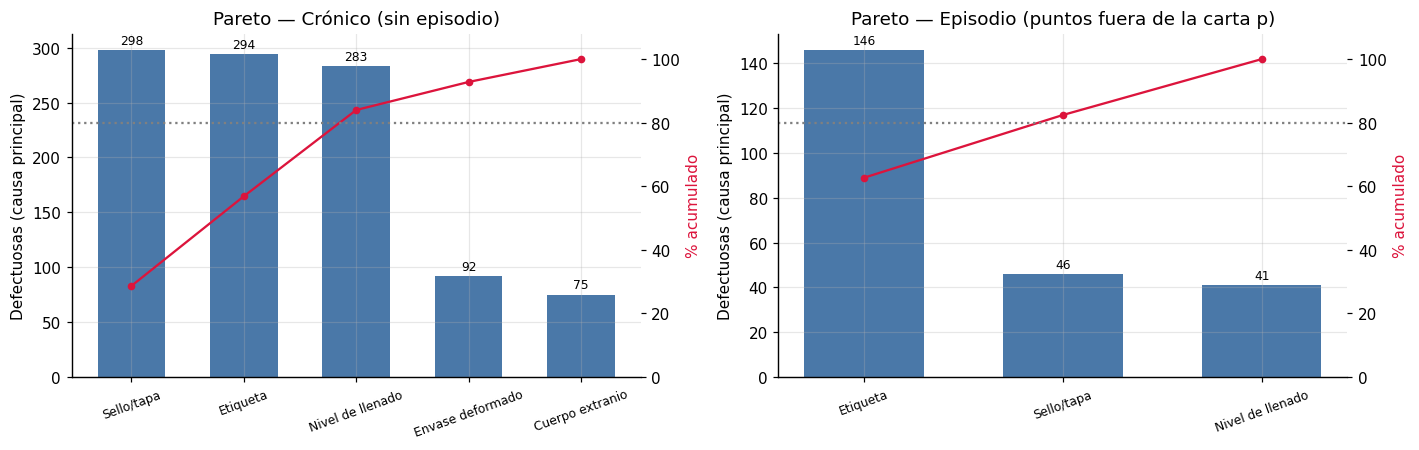

In [26]:
base = atr[atr["causa_principal"] != "Sin defectos"].copy()
clave_ep = set(zip(fuera_p["fecha"], fuera_p["turno"], fuera_p["linea"]))
base["episodio"] = [(f, t, l) in clave_ep for f, t, l in zip(base["fecha"], base["turno"], base["linea"])]

def pareto(d, peso="defectuosas"):
    if peso == "defectuosas":   # todas las defectuosas de la inspección se atribuyen a su causa principal
        p = d.groupby("causa_principal")["n_defectuosas"].sum()
    else:                       # número de inspecciones en que la causa fue la principal
        p = d.groupby("causa_principal").size()
    p = p.sort_values(ascending=False).to_frame(peso)
    p["%"] = 100 * p[peso] / p[peso].sum()
    p["%_acumulado"] = p["%"].cumsum()
    return p

par_total, par_cronico, par_episodio = pareto(base), pareto(base[~base["episodio"]]), pareto(base[base["episodio"]])
print("Pareto TOTAL (ponderado por defectuosas, causa principal)"); display(par_total.round(1))
print("Pareto SIN el episodio (crónico)"); display(par_cronico.round(1))
print("Pareto crónico por FRECUENCIA de inspecciones (control)"); display(pareto(base[~base["episodio"]], "inspecciones").round(1))
print("Pareto del EPISODIO"); display(par_episodio.round(1))
print("Pareto crónico por línea (defectuosas)")
display(base[~base["episodio"]].pivot_table(index="causa_principal", columns="linea", values="n_defectuosas", aggfunc="sum").round(0))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (titulo, p) in zip(ejes, [("Crónico (sin episodio)", par_cronico), ("Episodio (puntos fuera de la carta p)", par_episodio)]):
    b = ax.bar(p.index, p["defectuosas"], color="#4a78a8", width=0.6)
    ax.bar_label(b, fmt="%d", fontsize=8, padding=2)
    ax.tick_params(axis="x", rotation=20, labelsize=8)
    ax.set(title=f"Pareto — {titulo}", ylabel="Defectuosas (causa principal)")
    a2 = ax.twinx()
    a2.plot(p.index, p["%_acumulado"], "o-", color="crimson", ms=4)
    a2.axhline(80, color="gray", ls=":")
    a2.set_ylim(0, 108)
    a2.set_ylabel("% acumulado", color="crimson")
    a2.grid(False)
    a2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

**Lectura de resultados.** El Pareto **total** muestra a «Etiqueta» como causa dominante (34,5 % de las
defectuosas). **Sin el episodio**, el Pareto crónico es casi **plano**: Sello/tapa 28,6 %, Etiqueta 28,2 % y Nivel
de llenado 27,2 % suman el 84 %. El Pareto por **frecuencia** de inspecciones confirma la misma lectura
(Etiqueta 28,1 %, Nivel de llenado 28,1 %, Sello/tapa 26,0 %), así que la conclusión no depende de cómo se
pondera. Dos conclusiones:
1. El problema de etiquetas es en buena parte un **episodio** (63 % de las defectuosas de la semana 8). Se
   corrige con control de insumos, no con un proyecto de mejora permanente.
2. El problema **crónico** no tiene una causa dominante: reducir la merma exige atacar tres causas. Una de ellas,
   *Nivel de llenado*, conecta la merma por atributos con la variabilidad del llenado de 3.3.

Recordatorio: el Pareto atribuye todas las defectuosas de una inspección a su causa principal; las causas
secundarias no se registran.

### 3.5 Cuantificación económica del sobrellenado

**Lógica.** Litros regalados al año = botellas al año × (media − nominal) / 1000, valorizados al **costo
variable por litro** de cada SKU. El resultado depende de **dos supuestos que se separan explícitamente**
(cátedra):

1. **Base de volumen anual (cajas al año):**
   - **Año típico:** promedio anual de la venta limpia de los 3 años (156 semanas / 3).
   - **Régimen actual:** venta limpia de las últimas 52 semanas (105 a 156). **Es el caso base.**
   - **Demanda recuperada:** demanda reconstruida (sin censura, 4.2) de las últimas 52 semanas: lo que se
     envasaría si no hubiera quiebres de stock.
2. **Sobrellenado por botella:** **vigente** (Fase II, semanas 6 a 10, la situación de hoy) o **promedio de
   las 10 semanas** (referencia).

Las cifras usan ventas como aproximación de la producción. **No se valorizan las botellas defectuosas como
producto perdido**: no hay información del destino de cada defecto (una etiqueta mal puesta se reprocesa; un
sello defectuoso puede implicar descarte), así que multiplicarlas por un volumen perdido sin ese dato
sobrestimaría la merma.

In [27]:
ULT52 = slice(int(limpia.index.max()) - 51, int(limpia.index.max()))
demanda_rec_anual = limpia * 7 / (7 - sin_stock_l)          # misma corrección por censura de 4.2 (fila a fila)
bases_volumen = {
    "Año típico": limpia.sum() / (len(limpia) / 52),
    "Régimen actual": limpia.loc[ULT52].sum(),
    "Demanda recuperada": demanda_rec_anual.loc[ULT52].sum(),
}
BASE_REF, ESC_F2 = CONFIG["base_volumen_ref"], "Vigente (Fase II)"
display(pd.DataFrame({b: v for b, v in bases_volumen.items()}).T.assign(total=lambda d: d.sum(axis=1)).round(0))

escenarios = [(ESC_F2, llen[llen["semana_registro"] > FASE1]), ("Promedio 10 semanas", llen)]
filas = []
for base_nom, cajas in bases_volumen.items():
    for nombre, d in escenarios:
        for sku in skus:
            formato = mst.loc[sku, "formato_L"]
            sobre = d.loc[d["sku"] == sku, "volumen_mL"].mean() - esp.loc[formato, "nominal_mL"]
            botellas = cajas[sku] * mst.loc[sku, "botellas_por_caja"]
            costo_L = mst.loc[sku, "costo_variable_caja_clp"] / mst.loc[sku, "litros_por_caja"]
            filas.append([base_nom, nombre, mst.loc[sku, "linea_envasado"], formato, sku, sobre, botellas,
                          botellas * sobre / 1000, costo_L, botellas * sobre / 1000 * costo_L])
tabla_eco = pd.DataFrame(filas, columns=["base_volumen", "escenario", "linea", "formato", "sku", "sobrellenado_mL",
                                         "botellas_anio", "litros_anio", "costo_var_CLP_L", "valor_CLP_anio"])

matriz_eco = tabla_eco.groupby(["base_volumen", "escenario"])[["litros_anio", "valor_CLP_anio"]].sum()
matriz_eco["valor_MM_CLP"] = matriz_eco["valor_CLP_anio"] / 1e6
print("Matriz de sobrellenado: base de volumen × escenario de llenado (litros/año y MM CLP/año)")
display(matriz_eco.round(1))

eco_ref = tabla_eco[tabla_eco["base_volumen"] == BASE_REF]               # CASO BASE: régimen actual
cajas_anio = bases_volumen[BASE_REF]
print(f"Caso base ({BASE_REF} × {ESC_F2}) por SKU")
display(eco_ref[eco_ref["escenario"] == ESC_F2].round(2))
tot = eco_ref.groupby(["escenario", "linea", "formato"])[["litros_anio", "valor_CLP_anio"]].sum()
tot["valor_MM_CLP"] = tot["valor_CLP_anio"] / 1e6
display(tot.round(1))
tot_planta = eco_ref.groupby("escenario")[["litros_anio", "valor_CLP_anio"]].sum()
tot_planta["valor_MM_CLP"] = tot_planta["valor_CLP_anio"] / 1e6
display(tot_planta.round(1))

sku,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30,total
Año típico,104186.0,115495.0,22448.0,95833.0,65915.0,6727.0,78335.0,138656.0,33284.0,660879.0
Régimen actual,102324.0,114955.0,22513.0,128996.0,90729.0,7580.0,79233.0,139996.0,32359.0,718685.0
Demanda recuperada,102324.0,114955.0,22513.0,128996.0,91725.0,11985.0,79233.0,139996.0,32359.0,724086.0


Matriz de sobrellenado: base de volumen × escenario de llenado (litros/año y MM CLP/año)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


litros_anio  valor_CLP_anio  valor_MM_CLP
base_volumen       escenario                                                     
Año típico         Promedio 10 semanas      24275.6      15359915.5          15.4
                   Vigente (Fase II)        29870.8      18746109.0          18.7
Demanda recuperada Promedio 10 semanas      26865.4      17481301.4          17.5
                   Vigente (Fase II)        32956.2      21281891.1          21.3
Régimen actual     Promedio 10 semanas      26669.7      17322741.3          17.3
                   Vigente (Fase II)        32792.9      21149629.6          21.1

Caso base (Régimen actual × Vigente (Fase II)) por SKU


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,base_volumen,escenario,linea,formato,sku,sobrellenado_mL,botellas_anio,litros_anio,costo_var_CLP_L,valor_CLP_anio
18,Régimen actual,Vigente (Fase II),L1,0.5,CIT-L05,5.85,1227888.0,7188.49,470.0,3378588.47
19,Régimen actual,Vigente (Fase II),L2,1.5,CIT-L15,4.00,689730.0,2756.27,470.0,1295445.58
20,Régimen actual,Vigente (Fase II),L2,3.0,CIT-L30,7.77,90052.0,700.01,470.0,329004.05
21,Régimen actual,Vigente (Fase II),L1,0.5,FUN-B05,5.52,1547952.0,8537.73,810.0,6915560.70
22,Régimen actual,Vigente (Fase II),L2,1.5,FUN-B15,5.20,544374.0,2833.40,810.0,2295057.12
23,Régimen actual,Vigente (Fase II),L2,3.0,FUN-B30,7.50,30320.0,227.46,810.0,184246.19
24,Régimen actual,Vigente (Fase II),L1,0.5,NEC-D05,5.74,950796.0,5461.17,640.0,3495151.45
25,Régimen actual,Vigente (Fase II),L2,1.5,NEC-D15,4.74,839976.0,3983.97,640.0,2549741.55
26,Régimen actual,Vigente (Fase II),L2,3.0,NEC-D30,8.53,129436.0,1104.43,640.0,706834.46


litros_anio  valor_CLP_anio  valor_MM_CLP
escenario           linea formato                                           
Promedio 10 semanas L1    0.5          15198.9       9986388.8          10.0
                    L2    1.5           9351.6       6052815.5           6.1
                          3.0           2119.2       1283537.0           1.3
Vigente (Fase II)   L1    0.5          21187.4      13789300.6          13.8
                    L2    1.5           9573.6       6140244.3           6.1
                          3.0           2031.9       1220084.7           1.2

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,litros_anio,valor_CLP_anio,valor_MM_CLP
escenario,,,
Promedio 10 semanas,26669.7,17322741.3,17.3
Vigente (Fase II),32792.9,21149629.6,21.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [28]:
from scipy.stats import norm

ESC_F2 = "Vigente (Fase II)"                 # escenario de la situación actual en tabla_eco

filas_ppm = []
for linea, formato in cartas:
    LIE, LSE = esp.loc[formato, "LIE_mL"], esp.loc[formato, "LSE_mL"]
    d_p = llen[(llen["linea"] == linea) & (llen["formato_L"] == formato)]
    f1_p = d_p[d_p["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]   # Fase I estable
    f2_p = d_p[d_p["semana_registro"] > FASE1]                                       # Fase II (situación actual)

    # 1. PPM observado: botellas medidas fuera de especificación
    ppm_sobre_f1 = 1e6 * (f1_p["volumen_mL"] > LSE).sum() / len(f1_p)
    ppm_sobre_f2 = 1e6 * (f2_p["volumen_mL"] > LSE).sum() / len(f2_p)
    ppm_bajo_tot = 1e6 * (d_p["volumen_mL"] < LIE).sum() / len(d_p)

    # 2. PPM según el modelo normal de cada fase (ambas colas)
    ppm_norm_p = []
    for fase_p in (f1_p, f2_p):
        mu_p, sd_p = fase_p["volumen_mL"].mean(), fase_p["volumen_mL"].std(ddof=1)
        ppm_norm_p.append(1e6 * (norm.sf((LSE - mu_p) / sd_p) + norm.cdf((LIE - mu_p) / sd_p)))

    # 3. Valor de la pérdida vigente: jarabe regalado a costo variable
    eco_p = eco_ref[(eco_ref["escenario"] == ESC_F2) & (eco_ref["linea"] == linea) & (eco_ref["formato"] == formato)]
    botellas_p = eco_p["botellas_anio"].sum()
    costo_litro_p = eco_p["valor_CLP_anio"].sum() / eco_p["litros_anio"].sum()
    exceso_lse_p = (f2_p["volumen_mL"] - LSE).clip(lower=0).mean()

    filas_ppm.append([linea, formato, ppm_sobre_f1, ppm_sobre_f2, ppm_bajo_tot, ppm_norm_p[0], ppm_norm_p[1],
                      ppm_sobre_f2 * botellas_p / 1e6,
                      eco_p["valor_CLP_anio"].sum() / 1e6,
                      exceso_lse_p * botellas_p / 1000 * costo_litro_p / 1e6])

tabla_ppm = pd.DataFrame(filas_ppm, columns=[
    "linea", "formato", "PPM_sobre_LSE_F1", "PPM_sobre_LSE_F2", "PPM_bajo_LIE_total",
    "PPM_normal_F1", "PPM_normal_F2", "botellas_anio_sobre_LSE_F2",
    "perdida_sobrellenado_MM_CLP", "perdida_sobre_LSE_MM_CLP"])

display(tabla_ppm.round(1))
print(f"Pérdida total por sobrellenado vigente (Fase II): {tabla_ppm['perdida_sobrellenado_MM_CLP'].sum():.1f} MM CLP al año")
print(f"De ella, la que está sobre el LSE: {tabla_ppm['perdida_sobre_LSE_MM_CLP'].sum():.1f} MM CLP al año")
tabla_ppm.to_csv(os.path.join(CONFIG["carpeta_resultados"], "ppm_fuera_especificacion.csv"), index=False)

,linea,formato,PPM_sobre_LSE_F1,PPM_sobre_LSE_F2,PPM_bajo_LIE_total,PPM_normal_F1,PPM_normal_F2,botellas_anio_sobre_LSE_F2,perdida_sobrellenado_MM_CLP,perdida_sobre_LSE_MM_CLP
0,L1,0.5,3333.3,131666.7,0.0,3555.2,129073.6,490673.7,13.8,0.3
1,L2,1.5,33846.2,38157.9,0.0,18897.4,26949.4,79142.5,6.1,0.1
2,L2,3.0,29113.9,29729.7,641.0,26871.6,27521.8,7426.7,1.2,0.0


Pérdida total por sobrellenado vigente (Fase II): 21.1 MM CLP al año
De ella, la que está sobre el LSE: 0.4 MM CLP al año


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** En el **caso base** (régimen actual × sobrellenado vigente) BdM regala **≈ 32.800
litros de jarabe al año, ≈ 21,1 MM CLP a costo variable**. **L1 explica el 65 %** (21.200 L; 13,8 MM CLP), y por SKU
el mayor costo es FUN-B05 (6,9 MM CLP). La matriz muestra cuánto depende la cifra de cada supuesto:
- **Base de volumen** (con el sobrellenado vigente): **año típico 18,7 MM CLP**, régimen actual 21,1 y demanda
  recuperada 21,3. El año típico es menor porque FUN creció; la demanda recuperada casi no cambia el total,
  porque solo FUN-B15 y FUN-B30 tienen censura relevante y son SKU pequeños en litros.
- **Escenario de llenado:** con el promedio de 10 semanas (antes del corrimiento de L1) la cifra baja a 15,4–17,5
  MM CLP. La diferencia es el corrimiento de L1 desde el 24/08.

El rango defendible es **≈ 19 a 21 MM CLP al año** con el sobrellenado de hoy.

**Por turno.** Se reparte el volumen anual de cada línea × formato entre turnos en proporción a sus
subgrupos muestreados. El supuesto es que se muestrea cada 2 horas en todos los turnos, así que los
subgrupos son proporcionales a las horas producidas. Escenario vigente (Fase II).

In [29]:
filas = []
d_vig = llen[llen["semana_registro"] > FASE1]
for linea, formato in cartas:
    nominal = esp.loc[formato, "nominal_mL"]
    d = d_vig[(d_vig["linea"] == linea) & (d_vig["formato_L"] == formato)]
    skus_fl = mst[(mst["linea_envasado"] == linea) & (mst["formato_L"] == formato)].index
    botellas = (cajas_anio[skus_fl] * mst.loc[skus_fl, "botellas_por_caja"]).sum()
    litros_sku = cajas_anio[skus_fl] * mst.loc[skus_fl, "litros_por_caja"]
    costo_L = (litros_sku * mst.loc[skus_fl, "costo_variable_caja_clp"] / mst.loc[skus_fl, "litros_por_caja"]).sum() / litros_sku.sum()
    n_sub = d.groupby("turno")["subgrupo"].nunique()
    for turno in n_sub.index:
        sobre = d.loc[d["turno"] == turno, "volumen_mL"].mean() - nominal
        bt = botellas * n_sub[turno] / n_sub.sum()
        filas.append([linea, formato, turno, sobre, bt, bt * sobre / 1000, bt * sobre / 1000 * costo_L])

tabla_turno = pd.DataFrame(filas, columns=["linea", "formato", "turno", "sobrellenado_mL", "botellas_anio", "litros_anio", "valor_CLP_anio"])
tabla_turno["valor_MM_CLP"] = tabla_turno["valor_CLP_anio"] / 1e6
display(tabla_turno.round(2))

,linea,formato,turno,sobrellenado_mL,botellas_anio,litros_anio,valor_CLP_anio,valor_MM_CLP
0,L1,0.5,A (06-14),5.67,1863318.00,10563.65,6914968.74,6.91
1,L1,0.5,B (14-22),5.77,1863318.00,10751.84,7038161.36,7.04
2,L2,1.5,A (06-14),3.00,600391.58,1802.46,1132098.31,1.13
3,L2,1.5,B (14-22),3.76,709553.68,2668.19,1675855.86,1.68
4,L2,1.5,C (22-06),6.76,764134.74,5164.49,3243741.83,3.24
5,L2,3.0,A (06-14),7.29,94521.95,689.09,413007.99,0.41
6,L2,3.0,B (14-22),7.40,81018.81,599.41,359259.57,0.36
7,L2,3.0,C (22-06),9.80,74267.24,728.04,436350.56,0.44


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** En L1 ambos turnos regalan lo mismo (≈ 7 MM CLP cada uno): el problema es de la
máquina. En L2 1,5 L el **turno C regala 3,2 MM CLP al año, contra 1,1 y 1,7 MM CLP de A y B**, porque
llena +6,8 mL contra +3,0 y +3,8. Este es el número que pide el enunciado para la recomendación ejecutiva:
*el turno de noche regala ≈ 3,7 MM CLP al año en sobrellenado* (1,5 L + 3,0 L).

**Ahorro frente a capacidad (corrección 4).** Son dos preguntas distintas y se responden por separado:

- **Escenario A — actuar solo sobre la media (recentrar).** La media se baja hasta la **mínima admisible por
  el lado inferior** con la σ actual: $\mu_A = \max\big(Q_n,\ Q_n - T + 1{,}96\,\sigma,\ LIE + 3\cdot1{,}33\,\sigma\big)$
  (media legal, error T1 de OIML ≤ 2,5 % y Cpk inferior ≥ 1,33). Si $\mu_A$ supera la media de hoy, no se baja.
  Es un **ahorro económico**. Su Cpk resultante es $\min(LSE-\mu_A,\ \mu_A-LIE)/3\sigma$, y **nunca supera
  Cp**: si Cp < 1,33, ningún recentrado logra Cpk = 1,33.
- **Escenario B — reducir la variabilidad.** La σ que da Cp = 1,33 es $\sigma_B = (LSE-LIE)/(6\cdot1{,}33)$, y con
  ella se recalculan las restricciones y la media mínima $\mu_B$. Es el **requisito de capacidad**; su ahorro
  adicional sobre A es lo que paga la intervención en variabilidad.

In [30]:
K, z_t1 = CONFIG["cpk_objetivo"], CONFIG["z_oiml_t1"]
d_vig = llen[llen["semana_registro"] > FASE1]

def cpk(mu, s, LIE, LSE):
    return min(LSE - mu, mu - LIE) / (3 * s)

def mu_minima(s, Qn, T, LIE):
    """Media mínima que cumple las restricciones del lado inferior con desviación s."""
    return max(Qn, Qn - T + z_t1 * s, LIE + 3 * K * s)

filas, sobre_esc = [], []
for linea, formato in cartas:
    Qn, LIE, LSE, T = esp.loc[formato, ["nominal_mL", "LIE_mL", "LSE_mL", "tolerancia_oiml_mL"]]
    s_hoy = lims[(linea, formato)]["sigma"]
    mu_hoy = d_vig[(d_vig["linea"] == linea) & (d_vig["formato_L"] == formato)]["volumen_mL"].mean()
    eco = eco_ref[(eco_ref["escenario"] == ESC_F2) & (eco_ref["linea"] == linea) & (eco_ref["formato"] == formato)]
    clp_por_mL = eco["valor_CLP_anio"].sum() / (mu_hoy - Qn)          # CLP/año por cada mL de sobrellenado
    cp_hoy = (LSE - LIE) / (6 * s_hoy)
    mu_A = min(mu_hoy, mu_minima(s_hoy, Qn, T, LIE))                   # A: solo media
    s_B = (LSE - LIE) / (6 * K)                                        # B: sigma para Cp = 1,33
    mu_B = min(mu_hoy, mu_minima(s_B, Qn, T, LIE))
    filas.append({"carta": f"{linea} {formato} L", "sigma_hoy": s_hoy, "Cp_hoy": cp_hoy, "media_hoy": mu_hoy,
                  "Cpk_hoy": cpk(mu_hoy, s_hoy, LIE, LSE),
                  "A: media": mu_A, "A: mL ahorrados": mu_hoy - mu_A, "A: ahorro MM CLP/año": (mu_hoy - mu_A) * clp_por_mL / 1e6,
                  "A: Cpk resultante": cpk(mu_A, s_hoy, LIE, LSE), "A: Cpk máx. posible (= Cp)": cp_hoy,
                  "A: cumple Cpk 1,33": cpk(mu_A, s_hoy, LIE, LSE) >= K - 1e-9,
                  "B: sigma requerida": s_B, "B: reducción sigma %": 100 * (1 - s_B / s_hoy), "B: media": mu_B,
                  "B: ahorro total MM CLP/año": (mu_hoy - mu_B) * clp_por_mL / 1e6,
                  "B: ahorro adicional sobre A": (mu_A - mu_B) * clp_por_mL / 1e6, "B: Cpk resultante": cpk(mu_B, s_B, LIE, LSE)})
    for esc, mu in [("Hoy (vigente)", mu_hoy), ("A: recentrado", mu_A), ("B: σ reducida + recentrado", mu_B)]:
        sobre_esc.append({"formato_L": formato, "escenario": esc, "sobrellenado_mL": mu - Qn})

recuperable = pd.DataFrame(filas)
display(recuperable.set_index("carta").T.round(3))
bxc_fmt = maestro.drop_duplicates("formato_L").set_index("formato_L")["botellas_por_caja"]
escenarios_sobrellenado = pd.DataFrame(sobre_esc)
escenarios_sobrellenado["L_jarabe_extra_por_caja"] = (escenarios_sobrellenado["sobrellenado_mL"]
                                                       * escenarios_sobrellenado["formato_L"].map(bxc_fmt) / 1000)
print("Restricción recalculada para la Entrega 2: litros de jarabe extra por caja según escenario")
display(escenarios_sobrellenado.pivot(index="formato_L", columns="escenario", values="L_jarabe_extra_por_caja").round(4))

carta,L1 0.5 L,L2 1.5 L,L2 3.0 L
sigma_hoy,2.090893,4.969542,8.236909
Cp_hoy,1.275372,1.006129,1.011706
media_hoy,505.719767,1504.6455,3008.072378
Cpk_hoy,0.363518,0.694531,0.685031
A: media,500.342662,1504.6455,3007.865267
A: mL ahorrados,5.377104,0.0,0.207111
A: ahorro MM CLP/año,12.963205,0.0,0.031303
A: Cpk resultante,1.220745,0.694531,0.693413
A: Cpk máx. posible (= Cp),1.275372,1.006129,1.011706
"A: cumple Cpk 1,33",False,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Restricción recalculada para la Entrega 2: litros de jarabe extra por caja según escenario


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


escenario,A: recentrado,B: σ reducida + recentrado,Hoy (vigente)
formato_L,,,
0.5,0.0041,0.0,0.0686
1.5,0.0279,0.0,0.0279
3.0,0.0315,0.0,0.0323


**Lectura de resultados (ahorro separado de capacidad).**
- **L1 0,5 L.** *Escenario A:* bajar la media de 505,7 a 500,3 mL ahorra ≈ 5,4 mL por botella, **≈ 13,0 MM CLP al
  año**, con una acción barata (reprogramar la llenadora). Pero su Cpk resultante es **1,22, no 1,33**: con
  Cp = 1,28 ningún recentrado alcanza la meta. *Escenario B:* para Cpk = 1,33 hay que bajar σ de 2,09 a 2,01 mL
  (−4,1 %) y centrar en 500 mL, lo que agrega solo ≈ 0,8 MM CLP. **El ahorro de L1 es de media; su meta de
  capacidad exige además una pequeña mejora de variabilidad.**
- **L2 1,5 L y 3,0 L.** Con la σ actual, la media mínima admisible queda sobre la media de hoy (1,5 L) o casi en
  ella (3,0 L): recentrar ahorra 0 y 0,03 MM CLP y el Cpk se queda en ≈ 0,69. **Todo el ahorro de L2 (≈ 6,1 y
  1,2 MM CLP) depende de reducir σ ≈ 24 %** (escenario B), empezando por el turno C.
- **Restricciones para la Entrega 2:** el jarabe extra por caja es hoy 0,069 / 0,028 / 0,032 L (0,5 / 1,5 / 3,0 L);
  con A, 0,004 / 0,028 / 0,032; con B, 0 en los tres formatos (tabla C2).

Ésta es la respuesta cuantitativa a «las acciones que atacan la media y las que atacan la variabilidad no son las
mismas ni cuestan lo mismo»: el ahorro económico del recentrado y el cumplimiento de capacidad son metas
distintas y se informan por separado.

## 4. Parte B — Pronóstico de demanda

### 4.1 Diagnóstico documentado de las 9 series (solo desarrollo)

El enunciado pide revisar tendencia, estacionalidad, atípicos, faltantes, quiebres estructurales,
intermitencia y promociones. Faltantes y atípicos se trataron en 2.3. **Todo el diagnóstico de esta sección
usa solo el desarrollo (semanas 1 a 143)**, porque orienta decisiones de modelado (corrección 2): la prueba
no se mira hasta que la política quede congelada en 4.7. Cada diagnóstico deja registrada la última semana
que usó (`diagnostico_hasta`), y la sección 6 verifica que ninguna pase de la semana 143.

**Tendencia.** Nivel medio por bloque anual del desarrollo. Como el tercer bloque está incompleto (semanas
105 a 143), su variación se mide contra **las mismas semanas del año anterior** (53 a 91), para no mezclar
estaciones.

In [31]:
H, S = CONFIG["H"], CONFIG["S"]
lim_d, promo_d, sin_stock_d = limpia.loc[:FIN_DES], promo.loc[:FIN_DES], sin_stock_l.loc[:FIN_DES]
ventas_d, fechas_d, mes_d = ventas.loc[:FIN_DES], fechas.loc[:FIN_DES], mes.loc[:FIN_DES]
diagnostico_hasta = {}                       # última semana usada por cada diagnóstico (auditoría, sección 6)

bloques = {"año 1 (1-52)": (1, 52), "año 2 (53-104)": (53, 104), f"año 3 parcial (105-{FIN_DES})": (105, FIN_DES)}
nivel_anual = pd.DataFrame({k: lim_d.loc[a:b].mean() for k, (a, b) in bloques.items()})
nivel_anual["cambio año1→2 %"] = 100 * (nivel_anual["año 2 (53-104)"] / nivel_anual["año 1 (1-52)"] - 1)
nivel_anual["cambio interanual %"] = 100 * (lim_d.loc[105:FIN_DES].mean() / lim_d.loc[53:FIN_DES - 52].mean() - 1)
diagnostico_hasta["tendencia"] = int(lim_d.index.max())
display(nivel_anual.round(1))

,año 1 (1-52),año 2 (53-104),año 3 parcial (105-143),cambio año1→2 %,cambio interanual %
sku,,,,,
CIT-L05,2004.4,2038.6,2172.1,1.7,-3.4
CIT-L15,2216.5,2236.0,2435.9,0.9,-0.9
CIT-L30,438.8,423.3,486.1,-3.5,3.2
FUN-B05,1377.7,1670.5,2580.7,21.3,57.6
FUN-B15,955.2,1102.8,1828.9,15.5,68.2
FUN-B30,121.1,121.3,141.7,0.2,36.4
NEC-D05,1488.6,1507.0,1527.3,1.2,0.5
NEC-D15,2650.3,2656.9,2729.6,0.2,2.5
NEC-D30,649.3,648.6,627.3,-0.1,-5.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


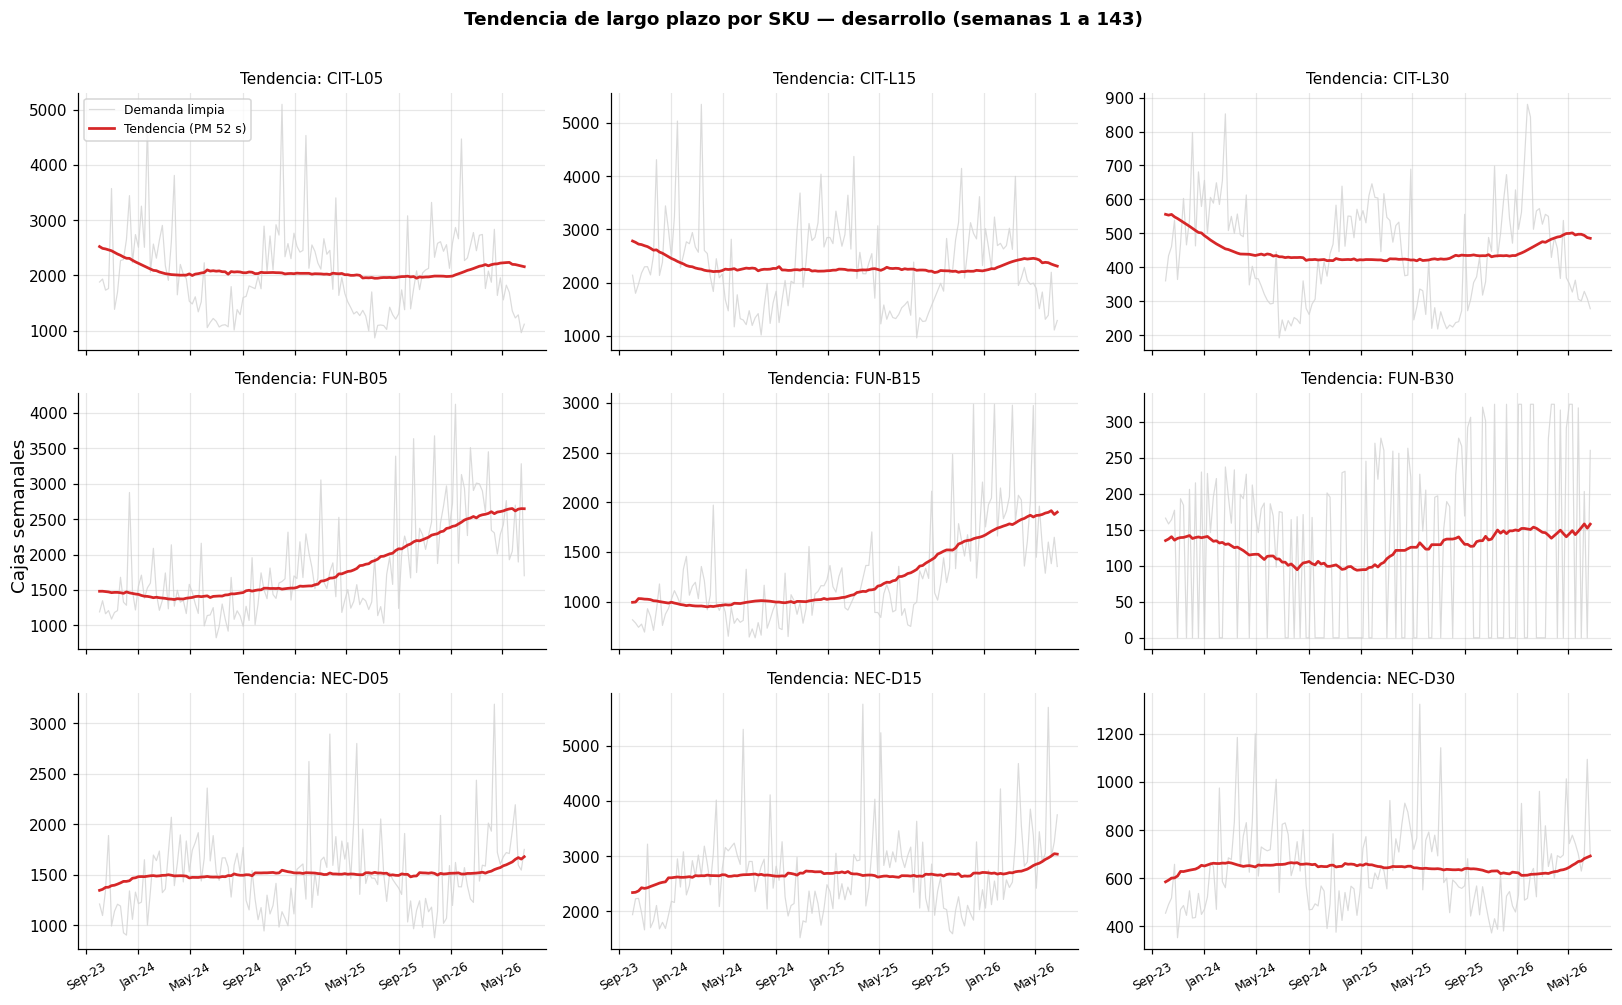

In [32]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    ax.plot(fechas_d, lim_d[sku], color="lightgray", alpha=0.8, lw=0.8, label="Demanda limpia")
    ax.plot(fechas_d, lim_d[sku].rolling(52, center=True, min_periods=26).mean(), color="tab:red", lw=1.8,
            label="Tendencia (PM 52 s)")
    ax.set_title(f"Tendencia: {sku}", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
ejes[0, 0].legend(fontsize=8, loc="upper left")
fig.supylabel("Cajas semanales")
plt.suptitle("Tendencia de largo plazo por SKU — desarrollo (semanas 1 a 143)", y=1.01, fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura de resultados.** Solo la familia **FUN crece**: en las semanas 105 a 143, FUN-B05 está +57,6 %,
FUN-B15 +68,2 % y FUN-B30 +36,4 % sobre las mismas semanas del año anterior, después de crecer 21 %, 16 % y 0 %
entre los años 1 y 2. CIT y NEC son estables (±5 %). Un modelo sin tendencia o sin nivel adaptativo subestimará FUN.

**Estacionalidad.** Índice mensual = venta / promedio móvil centrado de 52 semanas, con las semanas del
desarrollo **sin promoción**. 1,00 = mes normal; 1,26 = 26 % sobre lo normal.

In [33]:
sin_promo = lim_d.where(promo_d == 0)
tendencia_ciclo = lim_d.rolling(52, center=True, min_periods=40).mean()
indice_mes = (sin_promo / tendencia_ciclo).groupby(mes_d).mean()
diagnostico_hasta["estacionalidad"] = int(lim_d.index.max())
display(indice_mes.round(2).T)

fuerza = pd.DataFrame({"mes_pico": indice_mes.idxmax(), "indice_pico": indice_mes.max(),
                       "mes_valle": indice_mes.idxmin(), "indice_valle": indice_mes.min()})
fuerza["amplitud (pico/valle)"] = fuerza["indice_pico"] / fuerza["indice_valle"]
display(fuerza.round(2))

fecha_lunes,1,2,3,4,5,6,7,8,9,10,11,12
sku,,,,,,,,,,,,
CIT-L05,1.25,1.20,1.12,0.91,0.72,0.59,0.53,0.61,0.79,0.96,1.20,1.24
CIT-L15,1.24,1.23,1.06,0.97,0.63,0.63,0.58,0.62,0.78,1.09,1.16,1.28
CIT-L30,1.37,1.26,1.17,0.93,0.74,0.59,0.56,0.57,0.76,0.96,1.14,1.31
FUN-B05,1.15,1.09,1.06,0.91,0.86,0.75,0.67,0.83,0.81,0.97,1.02,1.05
FUN-B15,1.15,1.05,1.12,0.99,0.86,0.77,0.68,0.88,0.79,0.93,0.95,1.06
FUN-B30,0.89,1.37,1.16,1.34,0.93,1.02,0.89,1.01,0.76,1.22,1.01,0.25
NEC-D05,0.91,0.96,1.07,1.11,1.17,1.07,1.03,0.98,0.85,0.73,0.73,0.77
NEC-D15,0.89,0.91,1.05,1.06,1.16,1.12,1.04,0.91,0.92,0.70,0.74,0.78
NEC-D30,0.88,0.95,1.08,1.25,1.06,1.13,1.02,0.94,0.79,0.75,0.68,0.78


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,mes_pico,indice_pico,mes_valle,indice_valle,amplitud (pico/valle)
sku,,,,,
CIT-L05,1,1.25,7,0.53,2.36
CIT-L15,12,1.28,7,0.58,2.21
CIT-L30,1,1.37,7,0.56,2.47
FUN-B05,1,1.15,7,0.67,1.71
FUN-B15,1,1.15,7,0.68,1.70
FUN-B30,2,1.37,12,0.25,5.48
NEC-D05,5,1.17,10,0.73,1.61
NEC-D15,5,1.16,10,0.70,1.66
NEC-D30,4,1.25,11,0.68,1.82


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


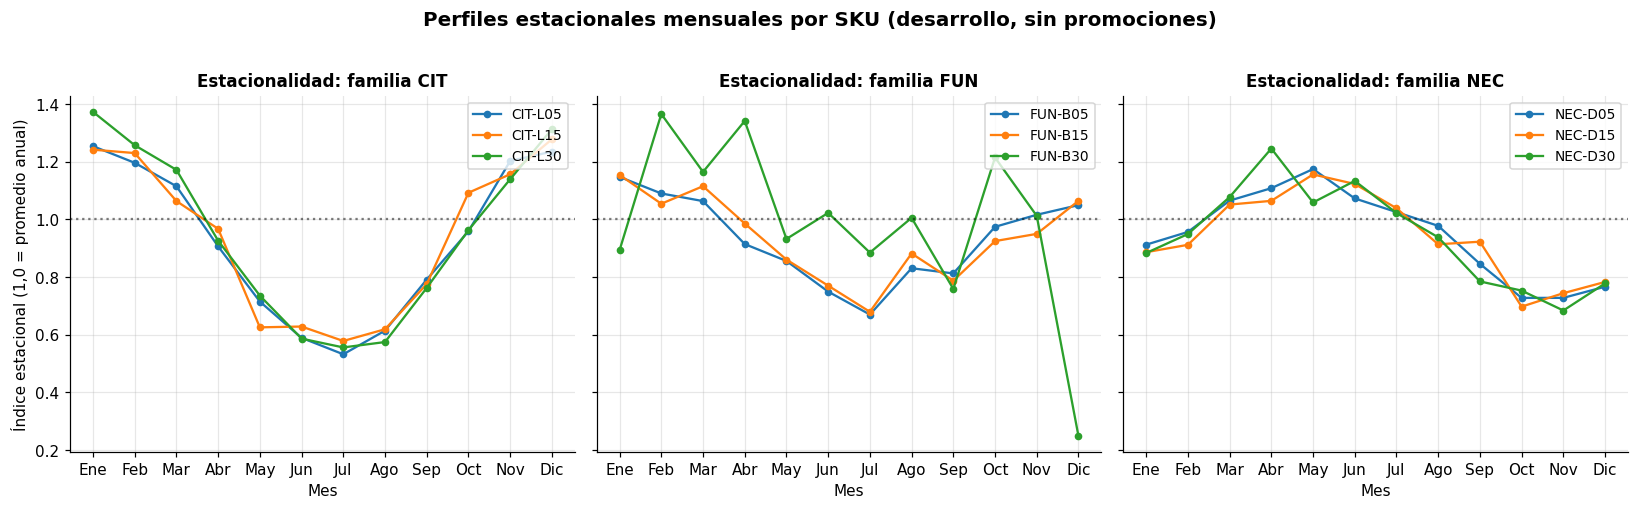

In [34]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
meses_nombres = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for ax, fam in zip(ejes, familias):
    for sku in skus_de[fam]:
        ax.plot(meses_nombres, indice_mes[sku], marker="o", ms=4, lw=1.5, label=sku)
    ax.axhline(1.0, color="black", linestyle=":", alpha=0.5)
    ax.set_title(f"Estacionalidad: familia {fam}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Mes")
    ax.legend(fontsize=9, loc="upper right")
ejes[0].set_ylabel("Índice estacional (1,0 = promedio anual)")
plt.suptitle("Perfiles estacionales mensuales por SKU (desarrollo, sin promociones)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura de resultados.** **CIT** tiene la estacionalidad más fuerte: peak en diciembre y enero (índice 1,24 a
1,37), valle en julio (0,53 a 0,58) y amplitud de 2,2 a 2,5 veces. **FUN** tiene la misma fase (peak en enero,
valle en julio) con amplitud de 1,7. **NEC** va en contrafase: peak de abril a mayo, valle de octubre a noviembre y
amplitud de 1,6 a 1,8. En FUN-B30 el índice es errático (amplitud 5,5) por su intermitencia, no por una estación
real. Las familias de verano son CIT y FUN; la del calendario escolar es NEC.

**Quiebres estructurales.** Se quita la estacionalidad y se busca el corte que mejor separa la serie en
dos niveles constantes, minimizando la suma de errores cuadrados. Se exigen al menos 26 semanas a cada
lado. Hay quiebre si el nivel cambia más de 20 % **y** el corte explica más de 25 % de la variación.

In [35]:
desest = lim_d / indice_mes.loc[mes_d].values
filas = []
for sku in skus:
    y = desest[sku].values
    mejor_sse, mejor_t = np.inf, None
    for t in range(26, len(y) - 26):
        sse = ((y[:t] - y[:t].mean()) ** 2).sum() + ((y[t:] - y[t:].mean()) ** 2).sum()
        if sse < mejor_sse:
            mejor_sse, mejor_t = sse, t
    antes, despues = y[:mejor_t].mean(), y[mejor_t:].mean()
    filas.append([sku, mejor_t + 1, fechas_d.iloc[mejor_t].date(), antes, despues, 100 * (despues / antes - 1),
                  100 * (1 - mejor_sse / ((y - y.mean()) ** 2).sum())])
quiebre = pd.DataFrame(filas, columns=["sku", "semana_corte", "fecha", "nivel_antes", "nivel_despues", "cambio_%",
                                       "variacion_explicada_%"])
quiebre["hay_quiebre"] = (quiebre["cambio_%"].abs() > 20) & (quiebre["variacion_explicada_%"] > 25)
diagnostico_hasta["quiebres"] = int(lim_d.index.max())
for _, f in quiebre[quiebre["hay_quiebre"]].iterrows():
    anotar(f["sku"], int(f["semana_corte"]), f"Quiebre estructural (nivel {f['cambio_%']:+.0f} %)",
           "Corte de dos niveles en la serie desestacionalizada (desarrollo)", "Se conserva; los modelos con nivel adaptativo lo siguen")
display(quiebre.round(1))

,sku,semana_corte,fecha,nivel_antes,nivel_despues,cambio_%,variacion_explicada_%,hay_quiebre
0,CIT-L05,81,2025-04-14,2202.3,2105.9,-4.4,0.9,False
1,CIT-L15,96,2025-07-28,2391.8,2331.7,-2.5,0.3,False
2,CIT-L30,39,2024-06-24,473.7,451.8,-4.6,1.4,False
3,FUN-B05,98,2025-08-11,1590.2,2617.9,64.6,51.9,True
4,FUN-B15,96,2025-07-28,1068.0,1798.5,68.4,54.6,True
5,FUN-B30,94,2025-07-14,118.7,168.6,42.0,1.8,False
6,NEC-D05,115,2025-12-08,1576.1,1656.1,5.1,1.0,False
7,NEC-D15,116,2025-12-15,2792.0,3027.8,8.4,2.3,False
8,NEC-D30,94,2025-07-14,693.7,654.1,-5.7,2.0,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** Hay **quiebre estructural en FUN-B05 (semana 98, 11/08/2025, +65 %) y FUN-B15
(semana 96, 28/07/2025, +68 %)**. El corte explica 52 a 55 % de su variación: no es una tendencia gradual sino un
**salto de nivel** a mediados de 2025. FUN-B30 también cambia de nivel (+42 %), pero el corte explica solo 1,8 %
de su variación porque domina la intermitencia, así que no se marca. **Decisión:** no se recorta la historia; se
usan modelos con nivel adaptativo (ETS) o diferencia estacional con constante (SARIMA), y la validación verifica
que sigan el nivel nuevo.

**Intermitencia** (clasificación de Syntetos-Boylan). **ADI** es el número promedio de semanas entre ventas
y **CV²** es la variabilidad del tamaño de la venta cuando sí hay venta. ADI > 1,32 indica demanda
intermitente.

In [36]:
filas = []
for sku in skus:
    v = lim_d[sku]
    con_venta = v[v > 0]
    adi, cv2 = len(v) / len(con_venta), (con_venta.std() / con_venta.mean()) ** 2
    tipo = ("intermitente" if cv2 < 0.49 else "irregular") if adi > 1.32 else ("errática" if cv2 > 0.49 else "suave")
    filas.append([sku, (v == 0).sum(), adi, cv2, tipo, ((v == 0) & (sin_stock_d[sku] > 0)).sum()])
intermit = pd.DataFrame(filas, columns=["sku", "semanas_en_cero", "ADI", "CV2", "tipo", "ceros_con_quiebre"])
diagnostico_hasta["intermitencia"] = int(lim_d.index.max())
display(intermit.round(2))
for _, f in intermit[intermit["tipo"] != "suave"].iterrows():
    anotar(f["sku"], "varias", f"Demanda {f['tipo']} ({f['semanas_en_cero']} semanas en cero)",
           f"ADI = {f['ADI']:.2f} > 1,32; ningún cero coincide con quiebre de stock",
           "Los ceros se conservan; la calibración de sus intervalos se revisa aparte (4.6)")

,sku,semanas_en_cero,ADI,CV2,tipo,ceros_con_quiebre
0,CIT-L05,0,1.00,0.14,suave,0
1,CIT-L15,0,1.00,0.13,suave,0
2,CIT-L30,0,1.00,0.11,suave,0
3,FUN-B05,0,1.00,0.14,suave,0
4,FUN-B15,0,1.00,0.16,suave,0
5,FUN-B30,63,1.79,0.07,intermitente,0
6,NEC-D05,0,1.00,0.07,suave,0
7,NEC-D15,0,1.00,0.08,suave,0
8,NEC-D30,0,1.00,0.08,suave,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** Solo **FUN-B30 es intermitente**: ADI = 1,79 y CV² = 0,07, es decir, vende cada
≈ 1,8 semanas, pero cuando vende lo hace en cantidades parecidas. **Ninguno de sus 63 ceros del desarrollo
coincide con un quiebre de stock**, así que son demanda nula real y se conservan. Su WAPE será alto con
cualquier modelo, y la calibración de sus intervalos se revisa aparte (4.6).

**Promociones.** El *lift* es la venta en semana de promoción dividida por la mediana de las semanas
vecinas (±6) **sin** promoción. También se mide el descuento de precio asociado.

In [37]:
filas = []
for sku in skus:
    lifts = []
    for sem in promo_d.index[promo_d[sku] == 1]:
        ventana = lim_d[sku].loc[sem - 6: sem + 6]                       # .loc no pasa de la semana 143
        base_ = ventana[promo_d[sku].loc[sem - 6: sem + 6] == 0].median()
        if base_ > 0:
            lifts.append(lim_d.loc[sem, sku] / base_)
    desc = 1 - precio_ef.loc[:FIN_DES, sku] / precio_li.loc[:FIN_DES, sku]
    filas.append([sku, int(promo_d[sku].sum()), 100 * promo_d[sku].mean(), 100 * desc[promo_d[sku] == 1].mean(),
                  np.mean(lifts), np.min(lifts), np.max(lifts)])
efecto_promo = pd.DataFrame(filas, columns=["sku", "semanas_promo", "%_semanas", "descuento_medio_%", "lift_medio", "lift_min", "lift_max"])
diagnostico_hasta["promociones"] = int(lim_d.index.max())
display(efecto_promo.round(2))
anotar("todos", "≈11 % de las semanas", "Promociones: suben la venta ≈1,5 a 1,7 veces",
       "Lift contra semanas vecinas sin promoción (desarrollo)", "Se evalúa como regresor en SARIMAX (4.3)")

,sku,semanas_promo,%_semanas,descuento_medio_%,lift_medio,lift_min,lift_max
0,CIT-L05,15,10.49,22.26,1.71,1.44,2.02
1,CIT-L15,15,10.49,20.29,1.62,1.00,2.09
2,CIT-L30,15,10.49,22.98,1.46,0.95,2.04
3,FUN-B05,16,11.19,22.94,1.64,1.29,2.12
4,FUN-B15,16,11.19,21.91,1.59,1.22,2.00
5,FUN-B30,15,10.49,22.39,1.13,0.00,3.65
6,NEC-D05,14,9.79,24.97,1.55,1.14,1.87
7,NEC-D15,16,11.19,21.57,1.55,1.05,2.19
8,NEC-D30,17,11.89,23.34,1.52,1.14,1.91


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** En el desarrollo, las promociones ocurren en ≈ 11 % de las semanas, con un descuento
medio de ≈ 22,5 %, y suben la venta **1,5 a 1,7 veces** (FUN-B30: 1,13, por su intermitencia). Es un efecto grande,
sistemático y repartido en todos los SKU: tiene sentido evaluarlo como regresor (4.3).

**Quiebres de stock (censura).** Aquí solo se *detectan*. La reconstrucción de la demanda es el punto 4.2.
Una segunda pista de censura es una venta que «choca» contra un tope: la serie repite su máximo varias
semanas.

In [38]:
cens = pd.DataFrame({"semanas_con_quiebre": (sin_stock_d > 0).sum(), "dias_sin_stock": sin_stock_d.sum(),
                     "semanas_en_el_maximo": [(ventas_d[s] >= ventas_d[s].max() * 0.995).sum() for s in skus],
                     "maximo_cajas": ventas_d.max()})
cens = cens[cens["dias_sin_stock"] > 0]
diagnostico_hasta["censura"] = int(ventas_d.index.max())
display(cens)
for sku in cens.index:
    anotar(sku, "varias", f"Quiebres de stock ({cens.loc[sku, 'dias_sin_stock']:.0f} días en {cens.loc[sku, 'semanas_con_quiebre']} semanas)",
           "dias_sin_stock > 0" + (f"; la venta repite su máximo ({cens.loc[sku, 'maximo_cajas']:.0f} cajas)" if cens.loc[sku, "semanas_en_el_maximo"] >= 3 else ""),
           "Venta censurada: se reconstruye la demanda (4.2)")

,semanas_con_quiebre,dias_sin_stock,semanas_en_el_maximo,maximo_cajas
sku,,,,
CIT-L05,1,1.0,1,32916.0
FUN-B15,2,2.0,4,2988.0
FUN-B30,51,129.0,10,324.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** Tres SKU tienen quiebres en el desarrollo. **FUN-B30 es el caso grave**: 51 semanas
con quiebre (129 días), y su venta repite el máximo de **324 cajas en 10 semanas**: la firma de un **tope de
oferta** (se vendió lo que había, no lo que se pedía). FUN-B15 (2 semanas) y CIT-L05 (1 semana) son marginales.

In [39]:
resumen_diag = pd.DataFrame(index=skus)
resumen_diag["cambio interanual %"] = nivel_anual["cambio interanual %"]
resumen_diag["mes_pico"] = fuerza["mes_pico"]
resumen_diag["amplitud_estacional"] = fuerza["amplitud (pico/valle)"]
resumen_diag["faltantes"] = ventas_d.isna().sum()
resumen_diag["atipicos"] = atipico.loc[:FIN_DES].sum()
resumen_diag["quiebre_estructural"] = quiebre.set_index("sku")["hay_quiebre"]
resumen_diag["tipo_demanda"] = intermit.set_index("sku")["tipo"]
resumen_diag["lift_promo"] = efecto_promo.set_index("sku")["lift_medio"]
resumen_diag["semanas_quiebre_stock"] = (sin_stock_d > 0).sum()
print("=== RESUMEN DEL DIAGNÓSTICO POR SKU (desarrollo, semanas 1 a 143) ===")
display(resumen_diag.round(2))
print("=== BITÁCORA DE ANOMALÍAS (qué es, cómo se detectó, qué se hizo) ===")
tabla_anom = pd.DataFrame(anomalias)
display(tabla_anom)

=== RESUMEN DEL DIAGNÓSTICO POR SKU (desarrollo, semanas 1 a 143) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cambio interanual %,mes_pico,amplitud_estacional,faltantes,atipicos,quiebre_estructural,tipo_demanda,lift_promo,semanas_quiebre_stock
CIT-L05,-3.44,1,2.36,0,1,False,suave,1.71,1
CIT-L15,-0.94,12,2.21,3,0,False,suave,1.62,0
CIT-L30,3.16,1,2.47,0,0,False,suave,1.46,0
FUN-B05,57.56,1,1.71,0,0,True,suave,1.64,0
FUN-B15,68.17,1,1.70,0,0,True,suave,1.59,2
FUN-B30,36.40,2,5.48,0,0,False,intermitente,1.13,51
NEC-D05,0.55,5,1.61,0,0,False,suave,1.55,0
NEC-D15,2.48,5,1.66,0,1,False,suave,1.55,0
NEC-D30,-5.03,4,1.82,0,0,False,suave,1.52,0


=== BITÁCORA DE ANOMALÍAS (qué es, cómo se detectó, qué se hizo) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,semana,que_es,deteccion,accion
0,CIT-L15,101,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
1,CIT-L15,102,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
2,CIT-L15,103,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
3,NEC-D15,63,"Atípico probable (20052 cajas, promoción = 1)",9.4 veces el nivel de las 13 semanas previas (...,Reemplazo SOLO en la serie de entrenamiento; l...
4,CIT-L05,118,"Atípico probable (32916 cajas, promoción = 0)",15.5 veces el nivel de las 13 semanas previas ...,Reemplazo SOLO en la serie de entrenamiento; l...
5,FUN-B05,98,Quiebre estructural (nivel +65 %),Corte de dos niveles en la serie desestacional...,Se conserva; los modelos con nivel adaptativo ...
6,FUN-B15,96,Quiebre estructural (nivel +68 %),Corte de dos niveles en la serie desestacional...,Se conserva; los modelos con nivel adaptativo ...
7,FUN-B30,varias,Demanda intermitente (63 semanas en cero),"ADI = 1.79 > 1,32; ningún cero coincide con qu...",Los ceros se conservan; la calibración de sus ...
8,todos,≈11 % de las semanas,"Promociones: suben la venta ≈1,5 a 1,7 veces",Lift contra semanas vecinas sin promoción (des...,Se evalúa como regresor en SARIMAX (4.3)
9,CIT-L05,varias,Quiebres de stock (1 días en 1 semanas),dias_sin_stock > 0,Venta censurada: se reconstruye la demanda (4.2)


**Lectura de resultados.** La bitácora reúne las **12 anomalías** detectadas en el desarrollo, con qué es, cómo se
detectó y qué se hizo: 3 faltantes, 2 atípicos probables (causa no confirmada), 2 quiebres estructurales, 1 serie
intermitente, promociones y 3 SKU con censura. Es la tabla que pide el punto 1 de la Parte B.

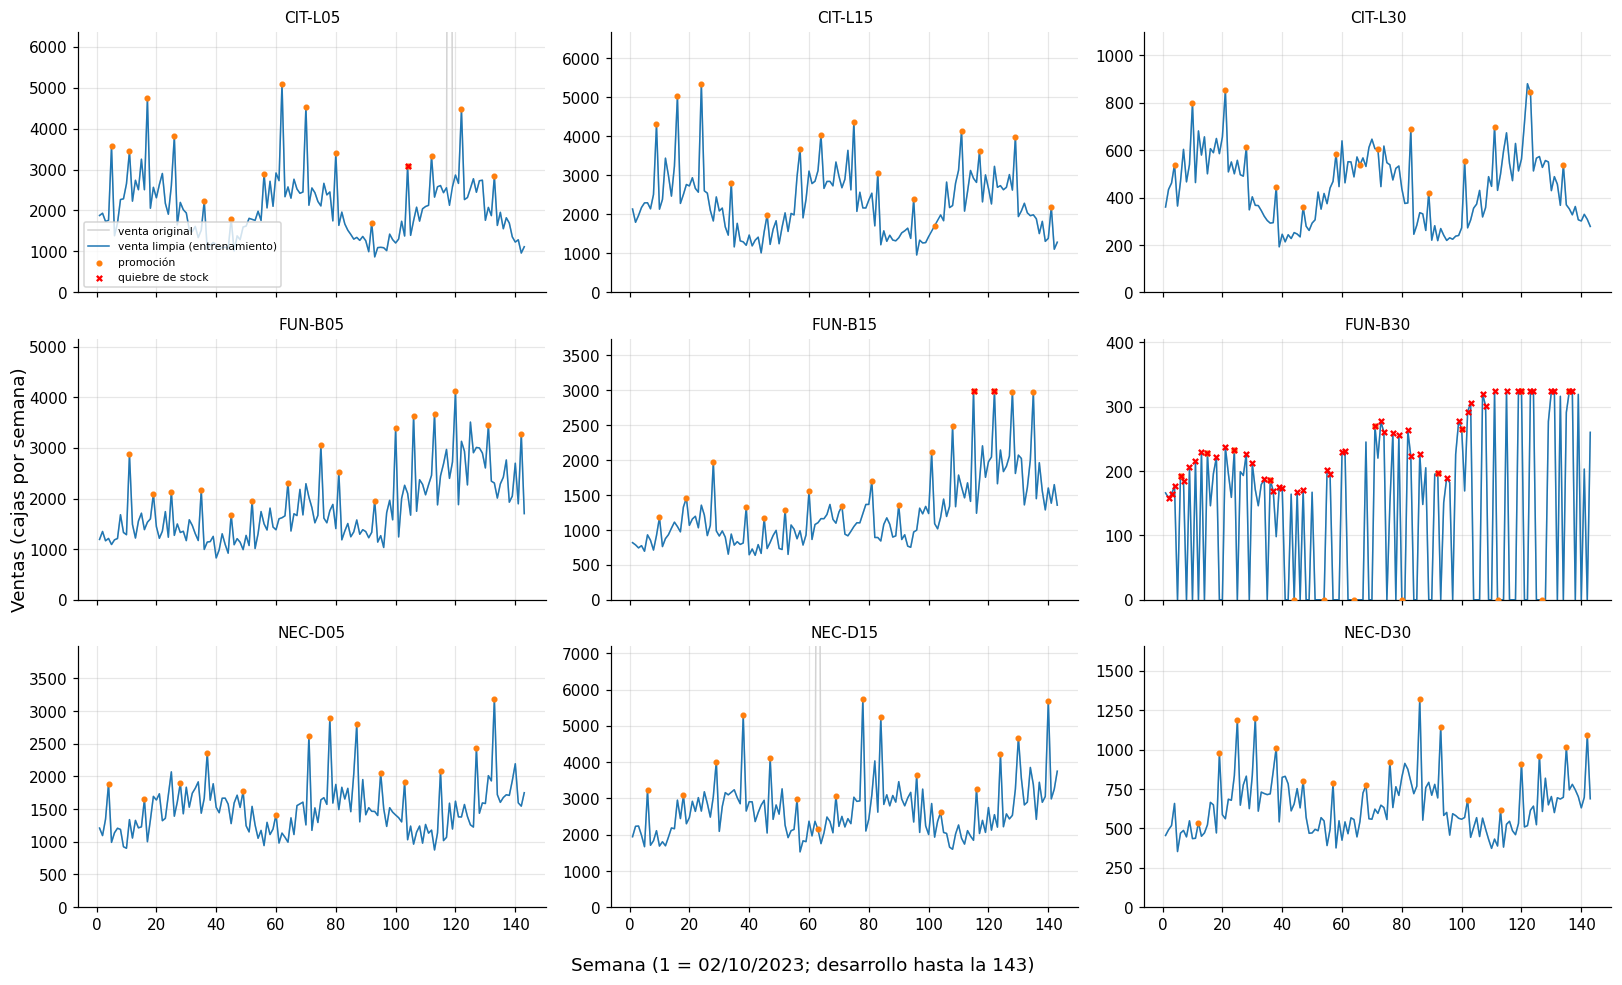

In [40]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    ax.plot(ventas_d.index, ventas_d[sku], color="lightgray", lw=1, label="venta original")
    ax.plot(lim_d.index, lim_d[sku], color="tab:blue", lw=1, label="venta limpia (entrenamiento)")
    p = promo_d[sku] == 1
    ax.scatter(lim_d.index[p], lim_d[sku][p], color="tab:orange", s=9, zorder=3, label="promoción")
    q = sin_stock_d[sku] > 0
    ax.scatter(lim_d.index[q], lim_d[sku][q], color="red", marker="x", s=12, zorder=3, label="quiebre de stock")
    ax.set_title(sku, fontsize=10)
    ax.set_ylim(0, lim_d[sku].max() * 1.25)
ejes[0, 0].legend(fontsize=7, loc="lower left")
fig.supxlabel("Semana (1 = 02/10/2023; desarrollo hasta la 143)")
fig.supylabel("Ventas (cajas por semana)")
plt.tight_layout()
plt.show()

### 4.2 Tratamiento de la censura: de ventas a demanda

**Supuesto explícito.** La demanda de una semana se reparte de forma homogénea entre sus 7 días. Si hubo $d$ días
sin stock, lo vendido corresponde solo a los $7-d$ días con stock:

$$\hat D_t = V_t \cdot \frac{7}{7-d_t}$$

**Justificación.** Es el supuesto más simple que usa la información disponible y es una corrección **fila a fila**:
no estima nada con otras semanas, así que **no genera fuga**. **Límites:** si $d = 7$ no hay información (no ocurre);
si la demanda se concentra en ciertos días o se traslada a otro SKU, la corrección sobrestima o subestima.

**Dos series, dos usos (corrección 3).** `demanda` (venta **limpia** × factor) es la serie con que se **entrenan**
los modelos. `demanda_obs` (venta **original**, solo con huecos interpolados, × factor) es la serie contra la que se
**mide el error de validación**. Difieren únicamente en las dos semanas con atípico probable.

Efecto de la reconstrucción en el desarrollo (semanas 1 a 143)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,semanas_quiebre,dias_sin_stock,ventas_cajas,demanda_estimada,cajas_perdidas,incremento_%
sku,,,,,,
CIT-L05,1,1.0,294947.0,295460.0,513.0,0.2
CIT-L15,0,0.0,326530.0,326530.0,0.0,0.0
CIT-L30,0,0.0,63789.0,63789.0,0.0,0.0
FUN-B05,0,0.0,259149.0,259149.0,0.0,0.0
FUN-B15,2,2.0,178341.0,179337.0,996.0,0.6
FUN-B30,51,129.0,18129.0,27291.5,9162.5,50.5
NEC-D05,0,0.0,215336.0,215336.0,0.0,0.0
NEC-D15,0,0.0,382427.0,382427.0,0.0,0.0
NEC-D30,0,0.0,91956.0,91956.0,0.0,0.0


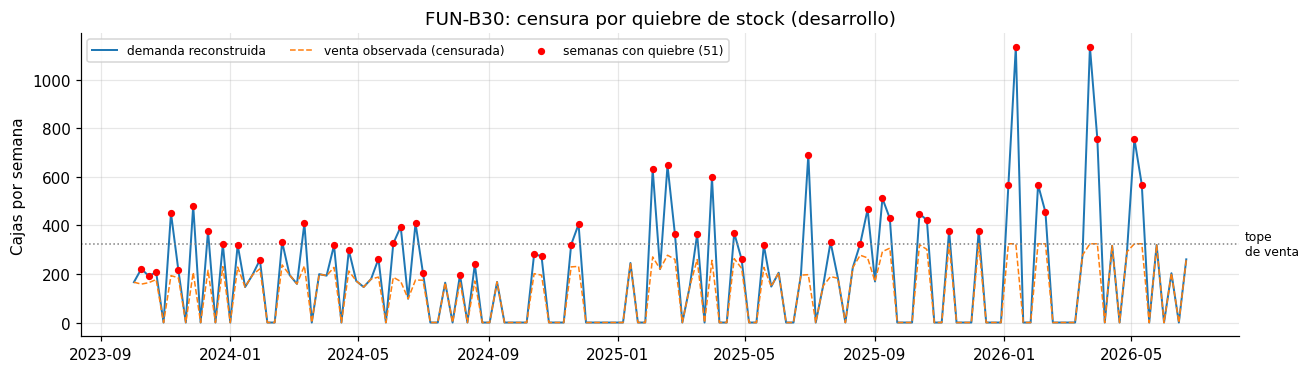

In [41]:
assert (sin_stock_l < 7).all().all(), "Hay semanas con 7 días sin stock: el supuesto no aplica"
factor = 7 / (7 - sin_stock_l)
demanda = limpia * factor            # serie de ENTRENAMIENTO: limpia y reconstruida (sin censura)
demanda_obs = ventas_interp * factor # serie OBJETIVO de validación: observación ORIGINAL (atípicos sin reemplazar) + censura
assert (demanda.round(9) != demanda_obs.round(9)).sum().sum() == len(reemplazos), "Las dos series difieren justo en los atípicos"

tabla_censura = pd.DataFrame({"semanas_quiebre": (sin_stock_d > 0).sum(), "dias_sin_stock": sin_stock_d.sum(),
                              "ventas_cajas": lim_d.sum(), "demanda_estimada": demanda.loc[:FIN_DES].sum()})
tabla_censura["cajas_perdidas"] = tabla_censura["demanda_estimada"] - tabla_censura["ventas_cajas"]
tabla_censura["incremento_%"] = 100 * tabla_censura["cajas_perdidas"] / tabla_censura["ventas_cajas"]
print("Efecto de la reconstrucción en el desarrollo (semanas 1 a 143)")
display(tabla_censura.round(1))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(fechas_d, demanda.loc[:FIN_DES, "FUN-B30"], color="tab:blue", lw=1.3, label="demanda reconstruida")
ax.plot(fechas_d, lim_d["FUN-B30"], color="tab:orange", ls="--", lw=1, label="venta observada (censurada)")
q = sin_stock_d["FUN-B30"] > 0
ax.scatter(fechas_d[q], demanda.loc[:FIN_DES, "FUN-B30"][q], color="red", s=14, zorder=4, label=f"semanas con quiebre ({q.sum()})")
ax.axhline(ventas_d["FUN-B30"].max(), color="gray", ls=":", lw=1)
ax.text(1.005, ventas_d["FUN-B30"].max(), "tope\nde venta", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
ax.set(title="FUN-B30: censura por quiebre de stock (desarrollo)", ylabel="Cajas por semana")
ax.legend(fontsize=8, loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

**Lectura de resultados.** En el desarrollo, la corrección es despreciable en CIT-L05 (+0,2 %) y FUN-B15 (+0,6 %).
En **FUN-B30 la demanda reconstruida es 50,5 % mayor que la venta** (+9.163 cajas en 143 semanas). Tratar las
ventas como demanda subestimaría su pronóstico en un tercio y perpetuaría el quiebre. Un costo del supuesto: en
semanas con 4 o 5 días sin stock el factor es 2,3 a 3,5, y esas semanas quedan como picos. Por eso FUN-B30 es el
SKU más incierto. Desde aquí el pronóstico usa `demanda` para entrenar y `demanda_obs` para validar.

### 4.3 Partición temporal, regresores y modelos

**Partición.** El **desarrollo** son las semanas 1 a 143 y la **prueba** las 13 últimas (144 a 156). Toda la
selección (modelo, órdenes, método jerárquico, regla de intervalos) se hace con origen deslizante **dentro**
del desarrollo. La prueba queda detrás de una guardia: solo se lee con `leer_prueba()`, que **falla** si la
política no está congelada (4.7), y cada lectura queda registrada.

In [42]:
FIN_TRAIN = FIN_DES                                            # semana 143
train = demanda.loc[:FIN_TRAIN]
print("Desarrollo: semanas", train.index.min(), "a", train.index.max(), f"({len(train)} semanas)")
print("Prueba:     semanas", FIN_TRAIN + 1, "a", int(demanda.index.max()), "(cerrada hasta 4.7)")

_PRUEBA = {"abierta": False, "hash_politica": None, "accesos": []}
def leer_prueba(df, motivo):
    """Única puerta de acceso a las semanas de prueba. Falla si la política no está congelada."""
    assert _PRUEBA["abierta"], "La prueba está cerrada: primero se congela la política (4.7)"
    _PRUEBA["accesos"].append(motivo)
    return df.loc[FIN_TRAIN + 1:]

Desarrollo: semanas 1 a 143 (143 semanas)
Prueba:     semanas 144 a 156 (cerrada hasta 4.7)


**¿Promoción y precio como regresores? (se justifica, no se asume; solo desarrollo).** Se revisa si el
precio de lista cambia, si el precio efectivo se mueve fuera de las promociones y cuánto se correlaciona con
la promoción. Todo con las semanas 1 a 143 (corrección 2: la v1 usaba las 156).

In [43]:
descuento_d = 1 - precio_ef.loc[:FIN_DES] / precio_li.loc[:FIN_DES]
corr_promo_desc = np.corrcoef(promo_d.values.ravel(), descuento_d.values.ravel())[0, 1]
diagnostico_hasta["correlacion_promo_descuento"] = int(descuento_d.index.max())
print("Valores distintos del precio de lista por SKU (desarrollo):", precio_li.loc[:FIN_DES].nunique().unique().tolist())
print("Semanas con descuento SIN promoción (desarrollo):", int(((descuento_d > 0) & (promo_d == 0)).sum().sum()))
print(f"Descuento en semanas con promoción: media {100 * descuento_d[promo_d == 1].stack().mean():.1f} % "
      f"| desviación {100 * descuento_d[promo_d == 1].stack().std():.1f} %")
print(f"Correlación promoción–descuento (semanas 1 a {FIN_DES}): {corr_promo_desc:.3f}")

Valores distintos del precio de lista por SKU (desarrollo): [1]
Semanas con descuento SIN promoción (desarrollo): 0
Descuento en semanas con promoción: media 22.5 % | desviación 4.0 %
Correlación promoción–descuento (semanas 1 a 143): 0.982


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados y decisión (solo desarrollo).** En las semanas 1 a 143 el precio de lista **nunca
cambia**, el precio efectivo **solo** baja en semanas de promoción y el descuento es casi constante (22,5 % ± 4,0 %).
La correlación promoción–descuento es **0,98**. **Precio y promoción contienen la misma información**: meter ambos
sería colinealidad sin ganancia. **Se usa solo `promocion` como regresor**; la celda siguiente verifica que sea
significativa.

**Modelos.** Cuatro modelos con la misma firma, para usarlos igual en validación, prueba y pronóstico final:

1. **Ingenuo estacional** (benchmark): $\hat y_{T+h} = y_{T+h-52}$.
2. **ETS (Holt-Winters)**: nivel + tendencia amortiguada + estacionalidad aditiva de 52 semanas.
3. **SARIMA** $(p,0,q)(0,1,0)_{52}$, con $p, q$ y constante elegidos por AIC.
4. **SARIMAX**: el mismo SARIMA con `promocion` como regresor. Como no hay calendario futuro de
   promociones, se pronostica con la **promoción esperada** (frecuencia de las 52 semanas previas al origen).
   «SARIMAX (calendario)», con la promoción real, es solo una referencia del valor de esa información.

**Convergencia (corrección 5).** Cada ajuste captura sus advertencias y registra si el optimizador convergió
(`registro_ajustes`). Si un SARIMA/SARIMAX no converge con L-BFGS, se **reintenta** con Nelder-Mead y luego
con Powell. En la búsqueda de órdenes por AIC **solo compiten los ajustes que convergen**: el AIC de un
ajuste no convergido no es confiable. Si un ajuste lanza una excepción se usa el ingenuo estacional y queda
registrado en `fallos`.

In [44]:
registro_ajustes = []                       # una fila por ajuste usado en un pronóstico
fallos = []                                 # ajustes que lanzaron excepción
busqueda_ordenes = {"ajustes": 0, "no_convergidos": 0}

def _texto_avisos(avisos):
    return "; ".join(sorted({f"{type(a.message).__name__}: {str(a.message)[:70]}" for a in avisos}))

def _convergio(res):
    """SARIMAX informa `converged`; Holt-Winters entrega el OptimizeResult de scipy (`success`)."""
    rv = getattr(res, "mle_retvals", None)
    if rv is None:
        return False
    return bool(rv["converged"]) if "converged" in rv else bool(rv.get("success", False))

def pron_naive_est(y, h):
    return y.iloc[-S:].iloc[:h].values

def pron_ets(y, h, etiqueta="ETS"):
    try:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            m = ExponentialSmoothing(y.values, trend="add", damped_trend=True, seasonal="add", seasonal_periods=S,
                                     initialization_method="estimated").fit()
        registro_ajustes.append({"modelo": etiqueta, "serie": y.name, "origen": int(y.index.max()), "intentos": 1,
                                 "metodo_final": "ETS", "convergio": _convergio(m), "n_avisos": len(avisos),
                                 "avisos": _texto_avisos(avisos)})
        return np.maximum(m.forecast(h), 0)
    except Exception as err:
        fallos.append((etiqueta, y.name, len(y), str(err)[:80]))
        return pron_naive_est(y, h)

OPTIMIZADORES = [("lbfgs", 50), ("nm", CONFIG["max_iter_reintento"]), ("powell", CONFIG["max_iter_reintento"])]

def ajustar_sarima(y, orden, x_hist=None, etiqueta=None):
    """SARIMA(p,0,q)(0,1,0)_S (con regresor si x_hist). Reintenta con otro optimizador si no converge.
    Con `etiqueta`, registra convergencia, número de intentos y avisos del ajuste."""
    p, q, tendencia = orden
    modelo = SARIMAX(y.values, exog=x_hist, order=(p, 0, q), seasonal_order=(0, 1, 0, S), trend=tendencia)
    avisos_todos = []
    for intento, (metodo, maxiter) in enumerate(OPTIMIZADORES, start=1):
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            res = modelo.fit(disp=False, method=metodo, maxiter=maxiter)
        avisos_todos += avisos
        if _convergio(res):
            break
    if etiqueta is not None:
        registro_ajustes.append({"modelo": etiqueta, "serie": getattr(y, "name", None), "origen": int(y.index.max()),
                                 "intentos": intento, "metodo_final": metodo, "convergio": _convergio(res),
                                 "n_avisos": len(avisos_todos), "avisos": _texto_avisos(avisos_todos)})
    return res

def elegir_orden(y, x_hist=None):
    """p, q y constante por AIC con SOLO la serie y entregada; compiten solo los ajustes que convergen."""
    mejor_aic, mejor = np.inf, None
    for p in [0, 1, 2]:
        for q in [0, 1]:
            for tendencia in ["n", "c"]:
                try:
                    r = ajustar_sarima(y, (p, q, tendencia), x_hist)
                    busqueda_ordenes["ajustes"] += 1
                    if not _convergio(r):
                        busqueda_ordenes["no_convergidos"] += 1
                        continue
                    if r.aic < mejor_aic:
                        mejor_aic, mejor = r.aic, (p, q, tendencia)
                except Exception as err:
                    fallos.append(("búsqueda de órdenes", y.name, len(y), str(err)[:80]))
    if mejor is None:
        fallos.append(("búsqueda de órdenes sin ajuste convergido", y.name, len(y), "se usa (0, 0, 'n')"))
        mejor = (0, 0, "n")
    return mejor

def pron_sarimas(y, h, orden_s, orden_x, x_hist, x_fut_real, sufijo=""):
    """Pronósticos SARIMA, SARIMAX (promoción esperada) y SARIMAX (calendario real, solo referencia)."""
    salida = {}
    try:
        salida["SARIMA"] = np.maximum(ajustar_sarima(y, orden_s, etiqueta="SARIMA" + sufijo).forecast(h), 0)
    except Exception as err:
        fallos.append(("SARIMA", y.name, len(y), str(err)[:80])); salida["SARIMA"] = pron_naive_est(y, h)
    try:
        m = ajustar_sarima(y, orden_x, x_hist, etiqueta="SARIMAX" + sufijo)
        x_esp = np.full((h, 1), x_hist[-S:].mean())                     # promoción esperada: 52 semanas previas
        salida["SARIMAX"] = np.maximum(m.forecast(h, exog=x_esp), 0)
        salida["SARIMAX (calendario)"] = np.maximum(m.forecast(h, exog=x_fut_real), 0)
    except Exception as err:
        fallos.append(("SARIMAX", y.name, len(y), str(err)[:80]))
        salida["SARIMAX"] = salida["SARIMAX (calendario)"] = pron_naive_est(y, h)
    return salida

**¿La promoción es significativa?** Se ajusta el SARIMAX con todo el entrenamiento y se mira el
coeficiente de `promocion` y su p-valor. Es solo una prueba de significancia: los órdenes que se usan
en la validación se eligen en la celda de 4.4, con datos anteriores al primer origen.

In [45]:
filas, orden_x_143 = [], {}
for sku in skus:
    y, x = train[sku], promo.loc[:FIN_TRAIN, [sku]].values
    orden = elegir_orden(y, x)
    orden_x_143[sku] = orden
    m = ajustar_sarima(y, orden, x, etiqueta="SARIMAX (significancia)")
    i = m.param_names.index("x1")
    filas.append([sku, orden, m.params[i], m.pvalues[i], m.params[i] / y.mean() * 100, _convergio(m)])
regresor = pd.DataFrame(filas, columns=["sku", "orden SARIMAX (p,q,tend)", "efecto_promo_cajas", "p_valor",
                                        "efecto_%_del_nivel", "convergio"])
regresor["significativa_5%"] = regresor["p_valor"] < 0.05
display(regresor.round(3))

,sku,"orden SARIMAX (p,q,tend)",efecto_promo_cajas,p_valor,efecto_%_del_nivel,convergio,significativa_5%
0,CIT-L05,"(2, 1, n)",1367.002,0.000,66.162,True,True
1,CIT-L15,"(0, 0, n)",1315.056,0.000,57.591,True,True
2,CIT-L30,"(0, 0, n)",158.150,0.000,35.454,True,True
3,FUN-B05,"(1, 1, c)",954.610,0.000,52.676,True,True
4,FUN-B15,"(1, 1, n)",768.631,0.000,61.289,True,True
5,FUN-B30,"(0, 0, c)",178.852,0.003,93.713,True,True
6,NEC-D05,"(1, 0, n)",736.925,0.000,48.938,True,True
7,NEC-D15,"(0, 1, n)",1394.789,0.000,52.155,True,True
8,NEC-D30,"(0, 0, n)",295.789,0.000,45.998,True,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** El coeficiente de promoción es **significativo al 5 % en los 9 SKU** (p ≤ 0,003)
y equivale a +35 % a +94 % del nivel medio de cada serie. **La promoción se justifica como regresor**. Que
mejore el pronóstico *fuera de muestra* se verifica en la validación (4.4), no se asume por el p-valor.

### 4.4 Validación por origen deslizante (8 ventanas, h = 13): WAPE, MASE y sesgo por horizonte

**Diseño.** 8 orígenes dentro del desarrollo: 109, 112, …, 130 (130 + 13 = 143). En cada origen cada modelo
se ajusta **solo con las semanas hasta el origen** (ventana creciente). Los órdenes de SARIMA/SARIMAX se eligen
por AIC con las semanas 1 a 109 (el primer origen), que están dentro del entrenamiento de todos los pliegues.

**Contra qué se mide el error (corrección 3).** El objetivo de validación es la **observación original**
(`demanda_obs`: venta registrada, con los huecos interpolados y la corrección por censura, **sin reemplazar
atípicos**). El reemplazo de CIT-L05 semana 118 solo afecta al **entrenamiento**; en los tres pliegues cuya
ventana de evaluación contiene esa semana (orígenes 109, 112 y 115) el error se mide contra el valor
registrado. Se reporta además la **sensibilidad**: (i) el mismo error medido contra la serie limpia y (ii) los
SKU con atípicos reentrenados **sin** limpieza.

**Métricas** ($e = \hat y - y$; positivo = sobrestima): **WAPE** $= \sum|e|/\sum y$; **MASE** $=
\text{media}(|e|/q)$ con $q$ = error medio del ingenuo estacional en el entrenamiento del pliegue; **Sesgo %**
$= \sum e/\sum y$.

In [47]:
ORIGENES = [FIN_TRAIN - H - CONFIG["paso"] * k for k in range(CONFIG["ventanas"] - 1, -1, -1)]
assert len(ORIGENES) >= 8 and max(ORIGENES) + H <= FIN_TRAIN, "Algún pliegue toca la prueba"
print("Orígenes:", ORIGENES, "| semanas evaluadas:", ORIGENES[0] + 1, "a", ORIGENES[-1] + H)
OBJETIVO = demanda_obs if CONFIG["objetivo_validacion"] == "observado" else demanda

SEMANA_SELECCION = ORIGENES[0]
ordenes_cv = {}
for sku in skus:
    y0, x0 = demanda.loc[:SEMANA_SELECCION, sku], promo.loc[:SEMANA_SELECCION, [sku]].values
    ordenes_cv[sku] = (elegir_orden(y0), elegir_orden(y0, x0))
display(pd.DataFrame(ordenes_cv, index=["orden SARIMA", "orden SARIMAX"]).T)

def pronosticar_todos(y, x_hist, x_fut_real, ordenes, h=H, sufijo=""):
    f = {"Ingenuo estacional": pron_naive_est(y, h), "ETS": pron_ets(y, h, etiqueta="ETS" + sufijo)}
    f.update(pron_sarimas(y, h, ordenes[0], ordenes[1], x_hist, x_fut_real, sufijo=sufijo))
    return f

def validar(serie_entrenamiento, lista_skus, sufijo=""):
    filas = []
    for sku in lista_skus:
        for o in ORIGENES:
            y = serie_entrenamiento.loc[:o, sku]
            assert y.index.max() == o                                   # el ajuste no ve nada después del origen
            x_hist, x_fut = promo.loc[:o, [sku]].values, promo.loc[o + 1:o + H, [sku]].values
            real, real_limpio = OBJETIVO.loc[o + 1:o + H, sku].values, demanda.loc[o + 1:o + H, sku].values
            escala = y.diff(S).abs().mean()
            for modelo, f in pronosticar_todos(y, x_hist, x_fut, ordenes_cv[sku], sufijo=sufijo).items():
                for h in range(1, H + 1):
                    filas.append([sku, modelo, o, h, real[h - 1], real_limpio[h - 1], f[h - 1], escala])
    out = pd.DataFrame(filas, columns=["sku", "modelo", "origen", "h", "y", "y_limpio", "yhat", "escala"])
    out["e"], out["e_limpio"] = out["yhat"] - out["y"], out["yhat"] - out["y_limpio"]
    return out

cv = validar(demanda, skus)
MODELOS = ["Ingenuo estacional", "ETS", "SARIMA", "SARIMAX", "SARIMAX (calendario)"]
print("Filas de validación:", len(cv), "=", len(skus), "SKU x", len(ORIGENES), "orígenes x", H, "h x", len(MODELOS), "modelos")

# Sensibilidad del ENTRENAMIENTO: SKU con atípicos dentro de alguna ventana de ajuste, reentrenados sin limpieza
skus_atip = sorted(reemplazos.loc[reemplazos["semana"] <= max(ORIGENES), "sku"].unique())
cv_sin_limpieza = validar(demanda_obs, skus_atip, sufijo=" [sens. sin limpieza]")
pliegues_afectados = {s: [o for o in ORIGENES if any((reemplazos["sku"] == s) & reemplazos["semana"].between(o + 1, o + H))]
                      for s in reemplazos["sku"]}
print("Pliegues cuya ventana de evaluación contiene un atípico:", pliegues_afectados)

reg_aj = pd.DataFrame(registro_ajustes)
conv_cv = (reg_aj[reg_aj["origen"].isin(ORIGENES)].groupby("modelo")
           .agg(ajustes=("convergio", "size"), convergidos=("convergio", "sum"), con_reintento=("intentos", lambda s: (s > 1).sum()),
                con_avisos=("n_avisos", lambda s: (s > 0).sum())))
conv_cv["% no convergido"] = 100 * (1 - conv_cv["convergidos"] / conv_cv["ajustes"])
print("Convergencia de los ajustes de la validación (registro, sin suprimir advertencias)")
display(conv_cv)
print(f"Búsqueda de órdenes: {busqueda_ordenes['ajustes']} ajustes, {busqueda_ordenes['no_convergidos']} descartados por no converger")
print("Ajustes con excepción (se usó el ingenuo):", len(fallos))

Orígenes: [109, 112, 115, 118, 121, 124, 127, 130] | semanas evaluadas: 110 a 143


,orden SARIMA,orden SARIMAX
CIT-L05,"(1, 0, n)","(2, 1, n)"
CIT-L15,"(0, 1, n)","(0, 0, n)"
CIT-L30,"(0, 1, c)","(0, 1, c)"
FUN-B05,"(0, 0, c)","(1, 1, c)"
FUN-B15,"(0, 0, c)","(1, 1, c)"
FUN-B30,"(0, 0, n)","(0, 0, n)"
NEC-D05,"(0, 1, n)","(0, 0, n)"
NEC-D15,"(1, 0, n)","(0, 0, n)"
NEC-D30,"(0, 1, n)","(0, 0, n)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Filas de validación: 4680 = 9 SKU x 8 orígenes x 13 h x 5 modelos


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Pliegues cuya ventana de evaluación contiene un atípico: {'NEC-D15': [], 'CIT-L05': [109, 112, 115]}
Convergencia de los ajustes de la validación (registro, sin suprimir advertencias)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ajustes,convergidos,con_reintento,con_avisos,% no convergido
modelo,,,,,
ETS,72,72,0,0,0.0
ETS [sens. sin limpieza],16,16,0,0,0.0
SARIMA,72,72,0,1,0.0
SARIMA [sens. sin limpieza],16,16,0,0,0.0
SARIMAX,72,72,6,6,0.0
SARIMAX [sens. sin limpieza],16,16,1,3,0.0


Búsqueda de órdenes: 527 ajustes, 0 descartados por no converger
Ajustes con excepción (se usó el ingenuo): 0


**Lectura de resultados.** La validación genera 4.680 pronósticos (9 SKU × 8 orígenes × 13 horizontes × 5
modelos). **Convergencia (sin advertencias ocultas):** los 216 ajustes de ETS, SARIMA y SARIMAX de la validación
convergieron; 5 ajustes SARIMAX necesitaron un **reintento** con otro optimizador y quedaron registrados con sus
avisos. En la búsqueda de órdenes, ningún ajuste se descartó por no converger. Los órdenes elegidos con las semanas
1 a 109 son pequeños ($p \le 2$, $q \le 1$), y la constante (deriva) aparece en las series que crecen. La semana 118
de CIT-L05 cae en la ventana de evaluación de los orígenes 109, 112 y 115: en esos pliegues el error se mide contra
el valor registrado (32.916 cajas).

=== MÉTRICAS GLOBALES (objetivo: observación original; 9 SKU, 8 orígenes, h = 1 a 13) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,WAPE_%,MASE,Sesgo_%
modelo,,,
Ingenuo estacional,31.29,1.50,-17.26
ETS,24.96,1.21,-4.50
SARIMA,27.83,1.36,-12.86
SARIMAX,24.29,1.22,-9.73
SARIMAX (calendario),21.45,1.07,-9.78


=== WAPE_% por horizonte ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,26.81,19.46,21.31,20.52,17.23
2,25.41,18.81,21.50,17.01,13.24
3,42.58,37.99,41.15,36.98,34.91
4,26.36,19.27,22.08,20.08,16.36
5,26.41,18.76,22.56,16.69,13.94
6,43.83,38.88,42.07,37.38,34.84
7,26.34,17.46,22.05,19.73,16.50
8,26.02,19.44,21.96,17.91,15.55
9,43.07,38.85,41.39,36.90,34.86


... (2 outputs left out)

modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,1.23,0.94,1.04,1.01,0.89
2,1.18,0.97,1.04,0.90,0.68
3,2.19,1.89,2.12,1.92,1.80
4,1.26,0.96,1.10,1.05,0.89
5,1.21,0.97,1.07,0.86,0.68
6,2.30,1.99,2.21,1.99,1.84
7,1.26,0.89,1.11,1.03,0.88
8,1.28,1.02,1.13,0.95,0.79
9,2.15,1.85,2.06,1.86,1.75


=== Sesgo_% por horizonte ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,-14.69,-1.98,-8.89,-4.03,-3.87
2,-13.46,0.07,-8.95,-3.60,-3.59
3,-25.44,-17.70,-21.78,-20.79,-19.41
4,-13.69,-1.24,-9.23,-4.16,-3.83
5,-12.54,1.41,-8.01,-4.30,-4.64
6,-26.20,-17.42,-22.56,-22.56,-22.12
7,-15.36,-2.61,-10.92,-6.11,-6.80
8,-14.63,2.14,-10.10,-6.54,-6.91
9,-24.22,-15.35,-20.46,-20.28,-20.73


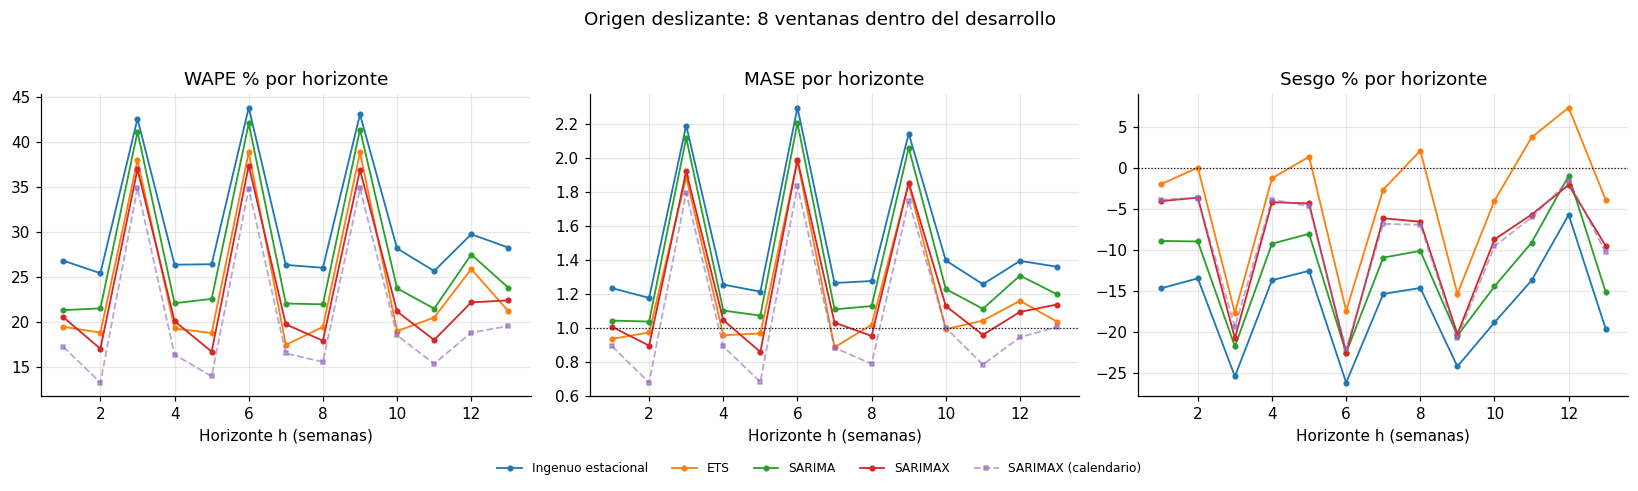

Sensibilidad al OBJETIVO de validación (todos los SKU)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,WAPE % vs observación original (base),WAPE % vs serie limpia,diferencia (pts)
modelo,,,
Ingenuo estacional,31.29,27.60,3.69
ETS,24.96,20.86,4.09
SARIMA,27.83,23.94,3.89
SARIMAX,24.29,20.21,4.08
SARIMAX (calendario),21.45,17.16,4.29


Sensibilidad del ENTRENAMIENTO en CIT-L05 (WAPE % contra la observación original)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,entrenado con serie limpia (base),entrenado sin limpieza
modelo,,
Ingenuo estacional,38.36,38.36
ETS,39.70,41.77
SARIMA,38.23,39.00
SARIMAX,36.77,45.42
SARIMAX (calendario),34.48,43.23


Sensibilidad del ENTRENAMIENTO en NEC-D15 (WAPE % contra la observación original)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,entrenado con serie limpia (base),entrenado sin limpieza
modelo,,
Ingenuo estacional,22.83,34.79
ETS,19.10,32.11
SARIMA,22.66,34.95
SARIMAX,19.36,33.19
SARIMAX (calendario),17.51,29.92


In [48]:
def metricas(g, e="e", y="y"):
    return pd.Series({"WAPE_%": 100 * g[e].abs().sum() / g[y].sum(),
                      "MASE": (g[e].abs() / g["escala"]).mean(),
                      "Sesgo_%": 100 * g[e].sum() / g[y].sum()})

global_cv = cv.groupby("modelo")[["e", "y", "escala"]].apply(metricas).loc[MODELOS]
print("=== MÉTRICAS GLOBALES (objetivo: observación original; 9 SKU, 8 orígenes, h = 1 a 13) ===")
display(global_cv.round(2))

por_h = cv.groupby(["modelo", "h"])[["e", "y", "escala"]].apply(metricas).reset_index()
for met in ["WAPE_%", "MASE", "Sesgo_%"]:
    print(f"=== {met} por horizonte ===")
    display(por_h.pivot(index="h", columns="modelo", values=met)[MODELOS].round(2))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, met, ref in zip(ejes, ["WAPE_%", "MASE", "Sesgo_%"], [None, 1, 0]):
    for m in MODELOS:
        r = por_h[por_h["modelo"] == m]
        ax.plot(r["h"], r[met], "o-" if m != "SARIMAX (calendario)" else "s--", ms=3, lw=1.2, label=m,
                alpha=0.6 if m == "SARIMAX (calendario)" else 1)
    if ref is not None:
        ax.axhline(ref, color="black", lw=0.8, ls=":")
    ax.set(xlabel="Horizonte h (semanas)", title=met.replace("_", " ") + " por horizonte")
h_, l_ = ejes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.suptitle("Origen deslizante: 8 ventanas dentro del desarrollo", y=1.02)
plt.tight_layout()
plt.show()

# ---- Sensibilidad (corrección 3)
wape = lambda g, e, y: 100 * g[e].abs().sum() / g[y].sum()
sens_objetivo = pd.DataFrame({
    "WAPE % vs observación original (base)": cv.groupby("modelo")[["e", "y"]].apply(wape, "e", "y"),
    "WAPE % vs serie limpia": cv.groupby("modelo")[["e_limpio", "y_limpio"]].apply(wape, "e_limpio", "y_limpio")}).loc[MODELOS]
sens_objetivo["diferencia (pts)"] = sens_objetivo.iloc[:, 0] - sens_objetivo.iloc[:, 1]
print("Sensibilidad al OBJETIVO de validación (todos los SKU)")
display(sens_objetivo.round(2))
for s in skus_atip:
    base_s = cv[cv["sku"] == s].groupby("modelo")[["e", "y"]].apply(wape, "e", "y")
    sin_s = cv_sin_limpieza[cv_sin_limpieza["sku"] == s].groupby("modelo")[["e", "y"]].apply(wape, "e", "y")
    print(f"Sensibilidad del ENTRENAMIENTO en {s} (WAPE % contra la observación original)")
    display(pd.DataFrame({"entrenado con serie limpia (base)": base_s, "entrenado sin limpieza": sin_s}).loc[MODELOS].round(2))

**Lectura de resultados.**
- **Todos los modelos le ganan al benchmark.** Contra la observación original, el ingenuo estacional tiene WAPE =
  31,3 % y sesgo −17,3 % (subestima: repite el año anterior y no ve el crecimiento de FUN). **SARIMAX (24,3 %)** y
  ETS (25,0 %) lo mejoran en ≈ 22 %. SARIMA queda en 27,8 %.
- **SARIMAX y ETS quedan casi empatados.** ETS tiene menos sesgo (−4,5 % contra −9,7 %): SARIMAX se queda corto en
  las semanas reales de promoción porque pronostica la promoción *esperada*. El criterio fijado de antemano es el
  menor WAPE, así que se elige **SARIMAX**; ETS queda como alternativa y el sesgo de SARIMAX se reporta.
- **Los dientes en h = 3, 6 y 9** (WAPE ≈ 37 a 39 %) tienen dos fuentes: el paso 3 hace que una misma semana difícil
  caiga en esos horizontes de orígenes distintos, y esa semana es justamente la 118 de CIT-L05 (h = 9, 6 y 3 en los
  orígenes 109, 112 y 115).
- **Sensibilidad al atípico (corrección 3).** Medido contra la serie limpia, todos los modelos bajan 3,7 a 4,3
  puntos (SARIMAX 20,2 %, ETS 20,9 %, ingenuo 27,6 %), pero **el ranking no cambia**: la selección no depende del
  reemplazo. Entrenar **sin** limpieza empeora el pronóstico: SARIMAX sube de 36,8 a 45,3 % en CIT-L05 y de 19,4 a
  33,2 % en NEC-D15, porque el modelo «aprende» el pico. La limpieza del entrenamiento se justifica por su efecto
  fuera de muestra, medido contra el dato original.
- **SARIMAX (calendario)** baja el WAPE a 21,5 %: compartir el calendario de promociones valdría ≈ 2,8 puntos.

In [49]:
wape_sku = cv.groupby(["sku", "modelo"])[["e", "y"]].apply(wape, "e", "y").unstack()[MODELOS]
print("=== WAPE (%) por SKU y modelo ===")
display(wape_sku.round(1))
mase_sku = cv.groupby(["sku", "modelo"])[["e", "escala"]].apply(lambda g: (g["e"].abs() / g["escala"]).mean()).unstack()[MODELOS]
print("=== MASE por SKU y modelo ===")
display(mase_sku.round(2))

ELEGIBLES = ["ETS", "SARIMA", "SARIMAX"]                      # el calendario futuro no está disponible
MODELO_BASE = global_cv.loc[ELEGIBLES, "WAPE_%"].idxmin()
modelo_si_objetivo_limpio = sens_objetivo.loc[ELEGIBLES, "WAPE % vs serie limpia"].idxmin()
mejora_vs_naive = 100 * (1 - global_cv.loc[MODELO_BASE, "WAPE_%"] / global_cv.loc["Ingenuo estacional", "WAPE_%"])
valor_calendario = global_cv.loc[MODELO_BASE, "WAPE_%"] - global_cv.loc["SARIMAX (calendario)", "WAPE_%"]
print(f"Modelo elegido (menor WAPE global contra la observación original): {MODELO_BASE}")
print(f"Con el objetivo limpio se elegiría: {modelo_si_objetivo_limpio} -> la selección "
      f"{'NO depende' if modelo_si_objetivo_limpio == MODELO_BASE else 'SÍ depende'} del tratamiento del atípico")
print(f"Mejora sobre el ingenuo estacional: {mejora_vs_naive:.1f} % menos WAPE")
print(f"Valor del calendario de promociones: {valor_calendario:.1f} puntos de WAPE")

=== WAPE (%) por SKU y modelo ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
sku,,,,,
CIT-L05,38.4,39.7,38.2,36.8,34.5
CIT-L15,20.2,18.9,19.9,17.0,12.7
CIT-L30,17.1,14.0,17.7,16.3,14.9
FUN-B05,36.5,18.2,24.1,18.2,17.1
FUN-B15,43.5,25.3,32.9,24.2,20.2
FUN-B30,100.6,110.8,100.6,101.1,99.8
NEC-D05,24.0,19.0,23.7,20.9,16.4
NEC-D15,22.8,19.1,22.7,19.4,17.5
NEC-D30,17.1,14.9,17.2,19.9,14.5


=== MASE por SKU y modelo ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
sku,,,,,
CIT-L05,2.34,2.42,2.33,2.24,2.09
CIT-L15,0.89,0.84,0.88,0.75,0.56
CIT-L30,1.07,0.87,1.10,1.02,0.93
FUN-B05,1.86,0.93,1.23,0.94,0.88
FUN-B15,2.39,1.35,1.82,1.35,1.14
FUN-B30,1.40,1.55,1.40,1.41,1.39
NEC-D05,1.46,1.16,1.45,1.28,1.00
NEC-D15,1.18,0.99,1.17,1.00,0.91
NEC-D30,0.88,0.77,0.89,1.02,0.74


Modelo elegido (menor WAPE global contra la observación original): SARIMAX
Con el objetivo limpio se elegiría: SARIMAX -> la selección NO depende del tratamiento del atípico
Mejora sobre el ingenuo estacional: 22.4 % menos WAPE
Valor del calendario de promociones: 2.8 puntos de WAPE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** El ranking cambia por SKU: ETS es mejor en CIT-L30, NEC-D05, NEC-D15 y NEC-D30 (y empata en
FUN-B05); SARIMAX en CIT-L05, CIT-L15 y FUN-B15. Se mantiene **un solo modelo** porque la diferencia global es pequeña y
elegir por SKU con 8 orígenes sobreajusta la selección. CIT-L05 tiene WAPE de 37 a 40 % en todos los modelos porque
su objetivo incluye la semana 118 registrada. En **FUN-B30 ningún modelo baja de ≈ 100 %**: con demanda
intermitente se pronostica bien el nivel, no la semana; Croston o TSB quedan como mejora propuesta.

### 4.5 Reconciliación jerárquica: bottom-up, top-down y middle-out

La jerarquía tiene 13 series: 9 SKU, 3 familias y la Planta. Se usa el modelo elegido en 4.4, los mismos 8
orígenes y las **cuotas calculadas con las 52 semanas previas a cada origen**: cada cálculo de cuotas queda en
`registro_cuotas` y la sección 6 verifica que ninguna use semanas posteriores a su origen. El error se mide
contra la observación original agregada.

In [50]:
niveles = demanda[skus].copy()              # entrenamiento (limpia + censura)
niveles_obs = demanda_obs[skus].copy()      # objetivo de validación (observación original + censura)
promo_niv = promo[skus].copy()
for f in familias:
    niveles[f], niveles_obs[f] = demanda[skus_de[f]].sum(axis=1), demanda_obs[skus_de[f]].sum(axis=1)
    promo_niv[f] = promo[skus_de[f]].sum(axis=1)
niveles["Planta"], niveles_obs["Planta"] = demanda[skus].sum(axis=1), demanda_obs[skus].sum(axis=1)
promo_niv["Planta"] = promo[skus].sum(axis=1)
SERIES = list(niveles.columns)
nivel_de = {**{s: "SKU" for s in skus}, **{f: "Familia" for f in familias}, "Planta": "Planta"}

for uid in familias + ["Planta"]:
    y0, x0 = niveles.loc[:SEMANA_SELECCION, uid], promo_niv.loc[:SEMANA_SELECCION, [uid]].values
    y0.name = uid
    ordenes_cv[uid] = (elegir_orden(y0), elegir_orden(y0, x0))

def pron_base(uid, hasta, ordenes, modelo=None, h=H):
    """Pronóstico base de una serie de la jerarquía con datos hasta la semana `hasta`."""
    modelo = modelo or MODELO_BASE
    y = niveles.loc[:hasta, uid]
    y.name = uid
    x_hist = promo_niv.loc[:hasta, [uid]].values
    x_fut = promo_niv.reindex(range(hasta + 1, hasta + h + 1))[[uid]].fillna(0).values
    if modelo == "Ingenuo estacional":
        return pron_naive_est(y, h)
    if modelo == "ETS":
        return pron_ets(y, h)
    try:
        if modelo == "SARIMA":
            return np.maximum(ajustar_sarima(y, ordenes[uid][0], etiqueta="SARIMA").forecast(h), 0)
        m = ajustar_sarima(y, ordenes[uid][1], x_hist, etiqueta="SARIMAX")
        x_f = x_fut if modelo == "SARIMAX (calendario)" else np.full((h, 1), x_hist[-S:].mean())
        return np.maximum(m.forecast(h, exog=x_f), 0)
    except Exception as err:
        fallos.append((modelo, uid, hasta, str(err)[:80]))
        return pron_naive_est(y, h)

registro_cuotas = []
def proporciones(hasta):
    hist = niveles.loc[hasta - CONFIG["semanas_proporcion"] + 1: hasta]
    registro_cuotas.append({"origen": hasta, "desde": int(hist.index.min()), "hasta": int(hist.index.max()),
                            "semanas": len(hist)})
    en_planta = {s: hist[s].sum() / hist["Planta"].sum() for s in skus}
    en_familia = {s: hist[s].sum() / hist[familia_de[s]].sum() for s in skus}
    return en_planta, en_familia

def reconciliar(base, en_planta, en_familia):
    """base: DataFrame h x 13 series. Devuelve los tres métodos coherentes."""
    bu, td, mo = base.copy(), base.copy(), base.copy()
    for s in skus:
        td[s] = base["Planta"] * en_planta[s]
        mo[s] = base[familia_de[s]] * en_familia[s]
    for tabla_m in [bu, td, mo]:
        for f in familias:
            tabla_m[f] = tabla_m[skus_de[f]].sum(axis=1)
        tabla_m["Planta"] = tabla_m[skus].sum(axis=1)
    return {"Base (sin reconciliar)": base, "Bottom-up": bu, "Top-down": td, "Middle-out": mo}

METODOS = ["Base (sin reconciliar)", "Bottom-up", "Top-down", "Middle-out"]
filas, cuotas_por_origen = [], {}
for o in ORIGENES:
    base = pd.DataFrame({uid: pron_base(uid, o, ordenes_cv) for uid in SERIES}, index=range(1, H + 1))
    real = niveles_obs.loc[o + 1:o + H].reset_index(drop=True); real.index = range(1, H + 1)
    real_l = niveles.loc[o + 1:o + H].reset_index(drop=True); real_l.index = range(1, H + 1)
    escala = niveles.loc[:o].diff(S).abs().mean()
    cuotas = proporciones(o)
    cuotas_por_origen[o] = cuotas[1]
    for metodo, pr in reconciliar(base, *cuotas).items():
        for uid in SERIES:
            for h in range(1, H + 1):
                filas.append([metodo, nivel_de[uid], uid, o, h, pr.loc[h, uid], real.loc[h, uid], real_l.loc[h, uid], escala[uid]])

errores = pd.DataFrame(filas, columns=["metodo", "nivel", "serie", "origen", "h", "yhat", "y", "y_limpio", "escala"])
errores["e"], errores["e_limpio"] = errores["yhat"] - errores["y"], errores["yhat"] - errores["y_limpio"]

ORDEN_NIV = ["Planta", "Familia", "SKU"]
tab_jer = errores.groupby(["nivel", "metodo"])[["e", "y", "escala"]].apply(metricas).reset_index()
for met in ["WAPE_%", "MASE", "Sesgo_%"]:
    print(f"=== {met} por nivel y método (origen deslizante, desarrollo) ===")
    display(tab_jer.pivot(index="nivel", columns="metodo", values=met).loc[ORDEN_NIV, METODOS].round(2))

wape_serie = errores[errores["nivel"] != "SKU"].groupby(["serie", "metodo"])[["e", "y"]].apply(wape, "e", "y").unstack().loc[["Planta"] + familias, METODOS]
print("=== WAPE (%) de cada familia y de la Planta ===")
display(wape_serie.round(1))

wape_sku_metodo = errores[(errores["nivel"] == "SKU") & (errores["metodo"] != METODOS[0])].groupby("metodo")
METODO_ELEGIDO = wape_sku_metodo[["e", "y"]].apply(wape, "e", "y").idxmin()
metodo_si_limpio = wape_sku_metodo[["e_limpio", "y_limpio"]].apply(wape, "e_limpio", "y_limpio").idxmin()
print("Método elegido (menor WAPE a nivel SKU):", METODO_ELEGIDO, "| con objetivo limpio:", metodo_si_limpio)
print("Cuotas SKU/familia por origen (cada una con las 52 semanas previas):")
display(pd.DataFrame(cuotas_por_origen).round(3))

=== WAPE_% por nivel y método (origen deslizante, desarrollo) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
nivel,,,,
Planta,15.65,14.53,15.65,14.82
Familia,18.96,18.69,24.57,18.96
SKU,24.29,24.29,28.31,23.36


=== MASE por nivel y método (origen deslizante, desarrollo) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
nivel,,,,
Planta,1.82,1.69,1.82,1.73
Familia,1.31,1.29,1.70,1.31
SKU,1.22,1.22,1.43,1.18


... (5 outputs left out)

metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
serie,,,,
Planta,15.6,14.5,15.6,14.8
CIT,23.3,22.5,28.1,23.3
FUN,17.8,17.6,24.3,17.8
NEC,14.8,15.1,20.5,14.8


Método elegido (menor WAPE a nivel SKU): Middle-out | con objetivo limpio: Middle-out
Cuotas SKU/familia por origen (cada una con las 52 semanas previas):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,109,112,115,118,121,124,127,130
CIT-L05,0.433,0.429,0.422,0.423,0.426,0.425,0.431,0.427
CIT-L15,0.477,0.482,0.486,0.486,0.482,0.482,0.475,0.479
CIT-L30,0.090,0.089,0.091,0.092,0.092,0.094,0.094,0.094
FUN-B05,0.566,0.566,0.562,0.564,0.560,0.554,0.556,0.552
FUN-B15,0.374,0.375,0.381,0.381,0.378,0.386,0.391,0.392
FUN-B30,0.060,0.059,0.057,0.056,0.061,0.060,0.054,0.056
NEC-D05,0.315,0.315,0.318,0.317,0.316,0.312,0.313,0.311
NEC-D15,0.551,0.551,0.548,0.550,0.551,0.556,0.554,0.555
NEC-D30,0.135,0.134,0.134,0.133,0.133,0.132,0.133,0.134


**Lectura de resultados.**
- **A nivel SKU** (el que usa el plan) gana **middle-out**, con WAPE 23,4 % contra 24,3 % de bottom-up y 28,3 % de
  top-down. **Top-down es el peor en los niveles bajos**: a nivel familia su WAPE es 24,6 % contra 18,7–19,0 % de
  los otros dos.
- **A nivel Planta** los tres quedan cerca (14,5 a 15,6 %); top-down tiene el mayor sesgo (−12,8 %).
- Con el objetivo limpio también gana middle-out: la elección del método no depende del atípico.
- Middle-out gana a nivel SKU porque la **familia** es el nivel donde la señal es más limpia: sus tres formatos
  comparten la fase estacional, el ruido se cancela al sumarlos y la cuota dentro de la familia es estable (tabla de
  cuotas por origen).

**Variables exógenas disponibles para las 13 semanas (cátedra).** El pronóstico solo puede usar lo que se
conoce en el momento del origen. La tabla documenta, para cada variable y nivel, si se conoce el futuro y qué
valor se usa en la validación y en el pronóstico final. La segunda tabla muestra la promoción esperada que usó
cada origen: sale **solo** de las 52 semanas previas.

In [51]:
exogenas = pd.DataFrame([
    {"variable": "promocion", "nivel": "SKU", "uso": "Regresor SARIMAX",
     "conocida en t+1..t+13": "No: no hay calendario de promociones futuras en los datos",
     "valor en validación y pronóstico": "Frecuencia de promoción de las 52 semanas previas al origen, constante en h = 1..13",
     "excepción": "«SARIMAX (calendario)» usa la promoción real: solo referencia, no elegible"},
    {"variable": "n.º de SKU en promoción", "nivel": "Familia y Planta", "uso": "Regresor SARIMAX",
     "conocida en t+1..t+13": "No", "valor en validación y pronóstico": "Promedio de las 52 semanas previas al origen",
     "excepción": "Ídem"},
    {"variable": "precio_efectivo / precio_lista", "nivel": "Todos", "uso": "No se usa",
     "conocida en t+1..t+13": "Precio de lista constante; el efectivo solo cambia con la promoción",
     "valor en validación y pronóstico": "—", "excepción": f"Correlación con la promoción {corr_promo_desc:.2f} (desarrollo)"},
    {"variable": "dias_sin_stock", "nivel": "SKU", "uso": "Reconstrucción de la demanda (4.2), no regresor",
     "conocida en t+1..t+13": "No", "valor en validación y pronóstico": "Se pronostica demanda sin restricción",
     "excepción": "—"},
])
display(exogenas)
promo_esperada_origen = pd.DataFrame({o: promo_niv.loc[o - S + 1:o].mean() for o in ORIGENES + [FIN_TRAIN, int(niveles.index.max())]}).T
promo_esperada_origen.index.name = "origen"
print("Promoción esperada usada en cada origen (frecuencia en las 52 semanas previas)")
display(promo_esperada_origen[skus].round(3))

,variable,nivel,uso,conocida en t+1..t+13,valor en validación y pronóstico,excepción
0,promocion,SKU,Regresor SARIMAX,No: no hay calendario de promociones futuras e...,Frecuencia de promoción de las 52 semanas prev...,«SARIMAX (calendario)» usa la promoción real: ...
1,n.º de SKU en promoción,Familia y Planta,Regresor SARIMAX,No,Promedio de las 52 semanas previas al origen,Ídem
2,precio_efectivo / precio_lista,Todos,No se usa,Precio de lista constante; el efectivo solo ca...,—,Correlación con la promoción 0.98 (desarrollo)
3,dias_sin_stock,SKU,"Reconstrucción de la demanda (4.2), no regresor",No,Se pronostica demanda sin restricción,—


Promoción esperada usada en cada origen (frecuencia en las 52 semanas previas)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


sku,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
origen,,,,,,,,,
109,0.096,0.096,0.115,0.115,0.115,0.096,0.115,0.115,0.096
112,0.115,0.115,0.115,0.115,0.096,0.115,0.096,0.115,0.096
115,0.096,0.115,0.115,0.135,0.115,0.115,0.115,0.096,0.115
118,0.096,0.115,0.096,0.115,0.115,0.096,0.115,0.115,0.115
121,0.096,0.115,0.096,0.135,0.115,0.115,0.115,0.096,0.115
124,0.096,0.115,0.096,0.135,0.115,0.096,0.096,0.115,0.115
127,0.096,0.096,0.096,0.115,0.115,0.115,0.115,0.115,0.135
130,0.096,0.115,0.096,0.115,0.135,0.115,0.096,0.115,0.115
143,0.096,0.115,0.077,0.135,0.115,0.115,0.096,0.115,0.135


**Evidencia de la pista: las familias no comparten la fase estacional.** Si cada familia tiene su pico en
un mes distinto, al sumarlas los picos de unas compensan los valles de otras. La Planta queda «plana» y
su pronóstico ya no sabe *qué* familia sube. Top-down reparte con una proporción fija y por eso traslada
mal la estacionalidad a los SKU.

,mes_pico,mes_valle,amplitud (pico/valle)
sku,,,
Planta,3,7,1.50
CIT,1,7,2.40
FUN,1,7,1.73
NEC,5,11,1.68


Correlación entre los perfiles estacionales de las familias (desarrollo):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


sku,CIT,FUN,NEC
sku,,,
CIT,1.00,0.89,-0.50
FUN,0.89,1.00,-0.26
NEC,-0.50,-0.26,1.00


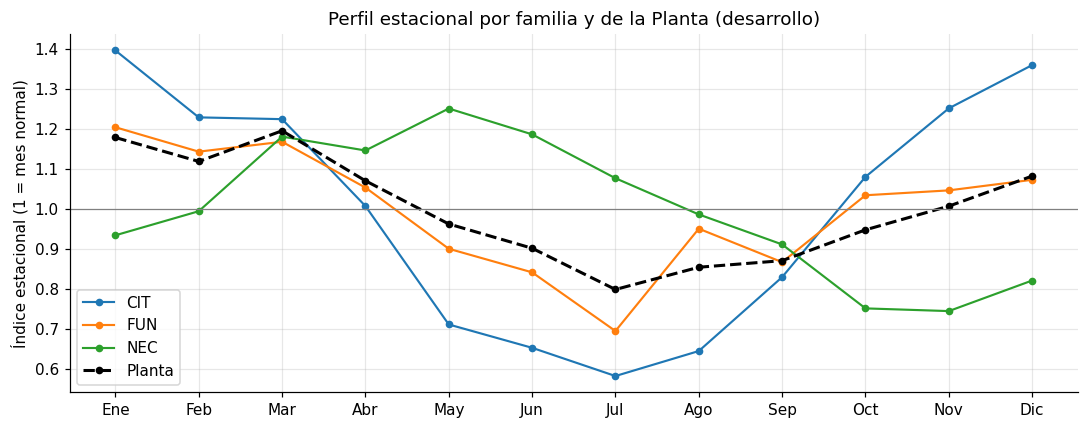

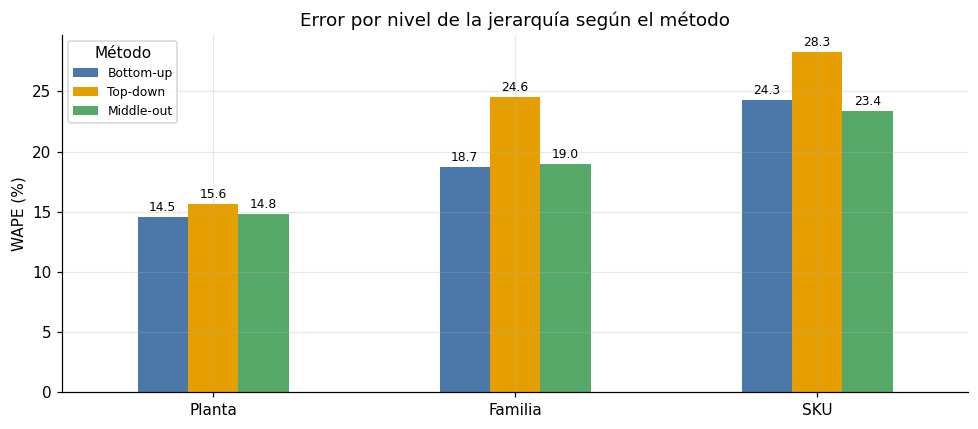

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [52]:
tc = niveles.loc[:FIN_DES].rolling(52, center=True, min_periods=40).mean()
indice_niv = (niveles.loc[:FIN_DES] / tc).groupby(mes_d).mean()
diagnostico_hasta["fase_estacional_familias"] = FIN_DES
amplitud = pd.DataFrame({"mes_pico": indice_niv.idxmax(), "mes_valle": indice_niv.idxmin(),
                         "amplitud (pico/valle)": indice_niv.max() / indice_niv.min()}).loc[["Planta"] + familias]
display(amplitud.round(2))
print("Correlación entre los perfiles estacionales de las familias (desarrollo):")
display(indice_niv[familias].corr().round(2))

fig, ax = plt.subplots(figsize=(10, 4))
meses_txt = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for uid, est in zip(familias + ["Planta"], ["-", "-", "-", "--"]):
    ax.plot(meses_txt, indice_niv[uid], est, marker="o", ms=4, lw=2 if uid == "Planta" else 1.4,
            color="black" if uid == "Planta" else None, label=uid)
ax.axhline(1, color="gray", lw=0.8)
ax.set(ylabel="Índice estacional (1 = mes normal)", title="Perfil estacional por familia y de la Planta (desarrollo)")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
piv = tab_jer.pivot(index="nivel", columns="metodo", values="WAPE_%").loc[ORDEN_NIV, METODOS[1:]]
piv.plot(kind="bar", ax=ax, rot=0, color=["#4a78a8", "#e69f00", "#55a868"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=8, padding=2)
ax.set(ylabel="WAPE (%)", xlabel="", title="Error por nivel de la jerarquía según el método")
ax.legend(title="Método", fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de resultados (la pista, con evidencia).** En el desarrollo, CIT y FUN tienen la misma fase (correlación
0,89), pero **NEC va en contrafase** (−0,50 con CIT y −0,26 con FUN). Al sumar las tres familias, la Planta queda con
una amplitud de solo 1,50 y su peak se va a **marzo**, un mes que no es el peak de ninguna familia. **La agregación al
total cancela parte de la señal en lugar de reforzarla.** Top-down pronostica esa serie «aplanada» y la reparte con
cuotas fijas: en diciembre le da a NEC una parte que es de CIT, y en junio al revés. Por eso top-down falla a nivel
familia y SKU, y el nivel intermedio (familia), donde la fase es común, es el mejor punto para pronosticar.

### 4.6 Incertidumbre del pronóstico: definición, sesgo y calibración (solo desarrollo)

**Corrección 1.** La v1 entregaba como «desviación estándar del error» un RMSE suavizado entre horizontes y
forzado a no decrecer. El RMSE **incluye el sesgo** ($\text{RMSE}^2 = \tfrac{n-1}{n}\,\text{DE}^2 + \text{sesgo}^2$)
y el suavizado no tiene la definición de una desviación estándar. Ahora:

$$e_{i,h,o} = \hat y_{i,h,o} - y_{i,h,o},\qquad
\hat b_{i,h} = \frac{1}{n}\sum_o e_{i,h,o},\qquad
\hat\sigma_{i,h} = \sqrt{\frac{1}{n-1}\sum_o \big(e_{i,h,o} - \hat b_{i,h}\big)^2}$$

con $n = 8$ orígenes, para cada serie $i$ (con el modelo y el método jerárquico elegidos) y cada horizonte $h$,
**sin suavizar ni forzar monotonía**. El sesgo $\hat b_{i,h}$ se entrega **aparte**.

**Contra qué se miden estos errores.** La *selección* del modelo (4.4) se hizo contra la observación original.
Para la *incertidumbre que fija el stock de seguridad* (`objetivo_incertidumbre = "limpio"`) el error se mide
contra la demanda limpia. Razón: el plan protege contra la variabilidad de la demanda, y la venta de 32.916
cajas de CIT-L05 en la semana 118 (15,5 veces su nivel, sin promoción) entra en 3 de los 8 orígenes y, por sí
sola, multiplicaría la σ̂ de CIT-L05 en h = 3, 6 y 9 por ≈ 20. Como su causa **no está confirmada**, la celda
siguiente muestra la σ̂ que resultaría con la observación original: si Comercial confirmara que esa venta fue
real, esa es la columna que debe usarse.

**¿Qué regla de intervalo usar? Se decide con el desarrollo, no con la prueba.** Se comparan cuatro reglas por
**cobertura dejando un origen fuera** (LOO): para cada origen $k$, los parámetros se estiman con los otros 7 y
se verifica si la demanda de $k$ cae en el intervalo.

| Regla | Intervalo |
|---|---|
| RMSE suavizado (v1) | $\hat y \pm z\,\text{RMSE}^{\text{suav}}_{i,h}$ |
| DE por h | $\hat y \pm z\,\hat\sigma_{i,h}$ |
| DE por h + sesgo | $(\hat y - \hat b_{i,h}) \pm z\,\hat\sigma_{i,h}$ |
| Cuantiles empíricos | $[\hat y - q_{1-\alpha/2},\ \hat y - q_{\alpha/2}]$ con los cuantiles de todos los errores de la serie |

Todos se truncan en 0. **Regla de decisión fijada antes de abrir la prueba:** se usa la regla con menor
desviación media absoluta entre la cobertura LOO y la nominal (80 % y 95 %); en empate, la más angosta. Para
series **intermitentes** se revisa aparte: si la regla elegida se desvía más de `desvio_cobertura_pts` = 10 puntos
de lo nominal y los cuantiles empíricos lo hacen mejor, esa serie usa cuantiles.

Verificación: RMSE² = (n−1)/n·DE² + sesgo² (máx. diferencia 1.9e-09)
σ̂ por SKU: DE por horizonte (nueva) frente al RMSE suavizado (v1), en cajas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,DE h=1,DE h=13,DE media,sesgo medio,RMSE suav. v1 medio,v1 / DE,parte del RMSE² que es sesgo %
serie,,,,,,,
CIT-L05,540.7,518.0,440.7,-38.1,459.9,1.0,4.8
CIT-L15,495.8,186.8,437.2,116.4,685.4,1.6,25.2
CIT-L30,88.0,84.3,101.5,-26.9,119.2,1.2,11.2
FUN-B05,488.9,575.2,475.1,-309.4,607.6,1.3,39.7
FUN-B15,688.8,721.3,557.1,-343.6,686.8,1.2,32.7
FUN-B30,289.9,290.5,359.5,-26.1,354.0,1.0,5.4
NEC-D05,297.8,347.4,422.7,-23.9,474.5,1.1,7.4
NEC-D15,673.0,977.0,724.9,-81.1,727.2,1.0,7.4
NEC-D30,112.8,121.3,162.5,21.9,179.8,1.1,18.4


Celdas (h, SKU) en que σ̂ cambia si se usa la observación original: 3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,,σ̂ base (objetivo limpio),σ̂ con la observación original
h,sku,,
3,CIT-L05,405.0,10822.0
6,CIT-L05,388.0,10810.0
9,CIT-L05,395.0,10818.0


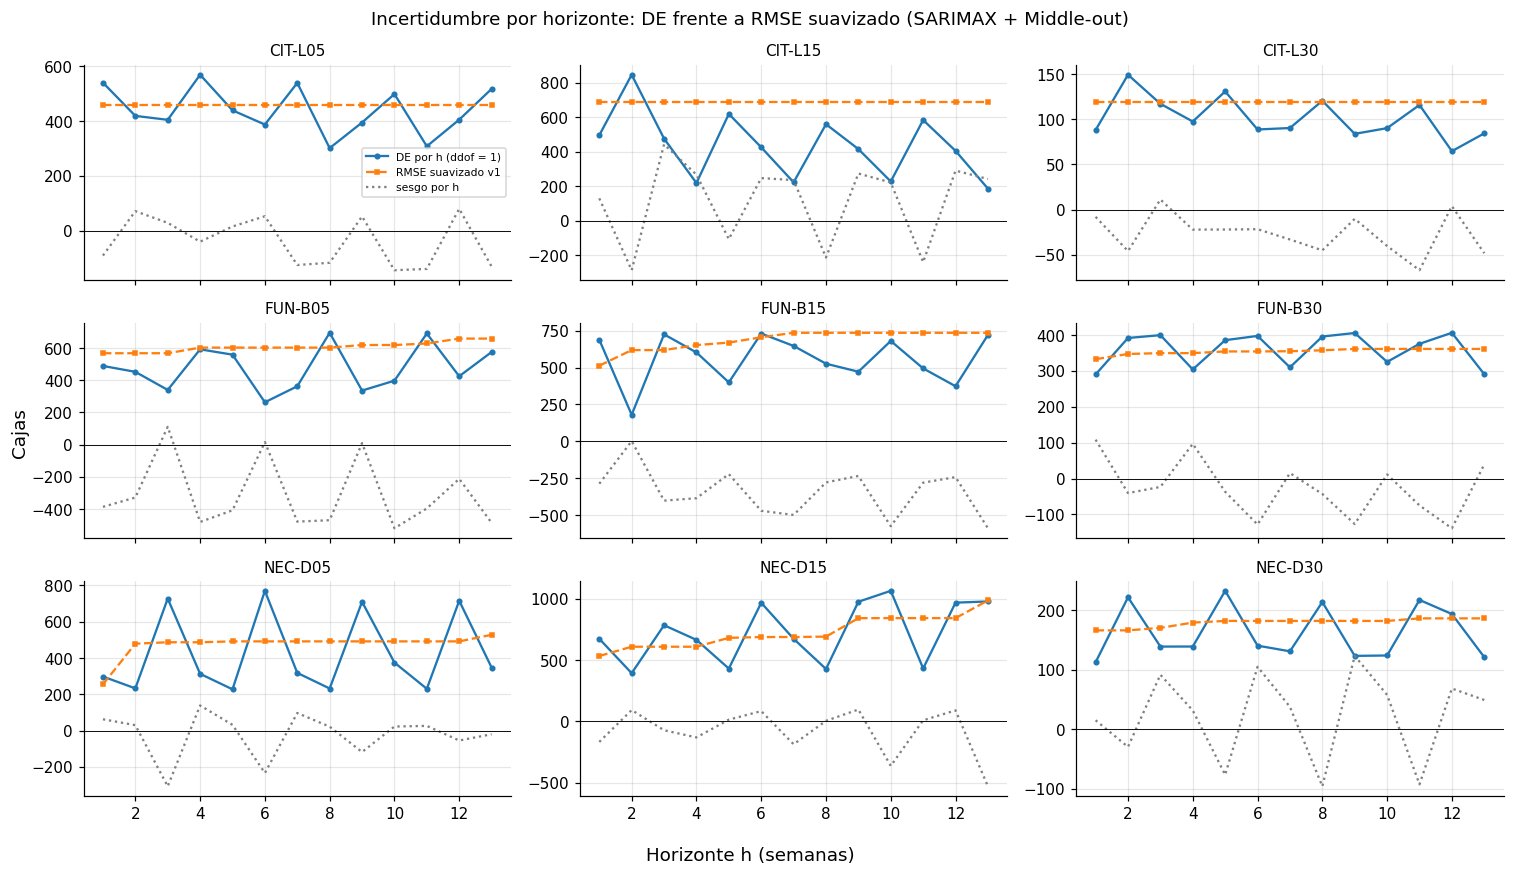

In [53]:
def sigma_rmse_suavizado(err):
    """Estimador de la v1 (solo referencia): RMSE con banda h-1..h+1 y forzado a no decrecer."""
    sig = {}
    for h in range(1, H + 1):
        banda = err[(err["h"] >= h - 1) & (err["h"] <= h + 1)]
        sig[h] = banda.groupby("serie")["e"].apply(lambda e: np.sqrt((e ** 2).mean()))
    return pd.DataFrame(sig).T.cummax()

def sigma_de(err):
    """σ̂_{i,h}: desviación estándar MUESTRAL (ddof = 1) de los errores e = ŷ − y de la serie i a horizonte h."""
    return err.groupby(["h", "serie"])["e"].std(ddof=1).unstack()

def sesgo_h(err):
    return err.groupby(["h", "serie"])["e"].mean().unstack()

def rmse_h(err):
    return err.groupby(["h", "serie"])["e"].apply(lambda e: np.sqrt((e ** 2).mean())).unstack()

err_el = errores[errores["metodo"] == METODO_ELEGIDO].copy()        # 13 series x 8 orígenes x 13 h
err_el["e_obs"], err_el["y_obs"] = err_el["e"], err_el["y"]         # error contra la observación original (sensibilidad)
if CONFIG["objetivo_incertidumbre"] == "limpio":                      # σ̂ para planificar: error contra la demanda limpia
    err_el["e"], err_el["y"] = err_el["e_limpio"], err_el["y_limpio"]
n_or = err_el.groupby(["h", "serie"]).size()
assert (n_or == len(ORIGENES)).all(), "Cada (serie, h) debe tener un error por origen"

sigma_dev, sesgo_dev, rmse_dev = sigma_de(err_el), sesgo_h(err_el), rmse_h(err_el)
sigma_v1 = sigma_rmse_suavizado(err_el)
n = len(ORIGENES)
descomp = (rmse_dev ** 2 - ((n - 1) / n * sigma_dev ** 2 + sesgo_dev ** 2)).abs().max().max()
assert descomp < 1e-6, "No se cumple RMSE² = (n−1)/n·DE² + sesgo²"
print(f"Verificación: RMSE² = (n−1)/n·DE² + sesgo² (máx. diferencia {descomp:.1e})")

comp_sigma = pd.DataFrame({
    "DE h=1": sigma_dev.loc[1, skus], "DE h=13": sigma_dev.loc[H, skus], "DE media": sigma_dev[skus].mean(),
    "sesgo medio": sesgo_dev[skus].mean(), "RMSE suav. v1 medio": sigma_v1[skus].mean()})
comp_sigma["v1 / DE"] = comp_sigma["RMSE suav. v1 medio"] / comp_sigma["DE media"]
comp_sigma["parte del RMSE² que es sesgo %"] = 100 * (sesgo_dev[skus] ** 2).mean() / (rmse_dev[skus] ** 2).mean()
print("σ̂ por SKU: DE por horizonte (nueva) frente al RMSE suavizado (v1), en cajas")
display(comp_sigma.round(1))

# Sensibilidad (corrección 3): σ̂ si el error se mide contra la observación ORIGINAL (atípico sin reemplazar)
sigma_obs = err_el.groupby(["h", "serie"])["e_obs"].std(ddof=1).unstack()
celdas = (sigma_obs[skus] - sigma_dev[skus]).abs().stack()
celdas = celdas[celdas > 1e-6].index
sens_sigma = pd.DataFrame({"σ̂ base (objetivo limpio)": sigma_dev[skus].stack()[celdas],
                           "σ̂ con la observación original": sigma_obs[skus].stack()[celdas]})
sens_sigma.index.names = ["h", "sku"]
print(f"Celdas (h, SKU) en que σ̂ cambia si se usa la observación original: {len(sens_sigma)}")
display(sens_sigma.round(0))

fig, ejes = plt.subplots(3, 3, figsize=(14, 8), sharex=True)
for ax, s in zip(ejes.flatten(), skus):
    ax.plot(sigma_dev.index, sigma_dev[s], "o-", ms=3, label="DE por h (ddof = 1)")
    ax.plot(sigma_v1.index, sigma_v1[s], "s--", ms=3, label="RMSE suavizado v1")
    ax.plot(sesgo_dev.index, sesgo_dev[s], ":", color="gray", label="sesgo por h")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(s, fontsize=10)
ejes[0, 0].legend(fontsize=7)
fig.supxlabel("Horizonte h (semanas)"); fig.supylabel("Cajas")
plt.suptitle(f"Incertidumbre por horizonte: DE frente a RMSE suavizado ({MODELO_BASE} + {METODO_ELEGIDO})")
plt.tight_layout()
plt.show()

In [54]:
METODOS_IP = ["RMSE suavizado (v1)", "DE por h", "DE por h + sesgo", "Cuantiles empíricos"]
NIVELES_IP = CONFIG["niveles_ip"]

def limites_ip(metodo, err_ref, pts, nivel):
    """Límites (inferior, superior) de la regla `metodo` estimada con err_ref, para los puntos pts (serie, h, yhat)."""
    z = stats.norm.ppf(0.5 + nivel / 2)
    clave = list(zip(pts["h"], pts["serie"]))
    yhat = pts["yhat"].values
    if metodo == "RMSE suavizado (v1)":
        s1 = sigma_rmse_suavizado(err_ref)
        centro, semi = yhat, z * np.array([s1.loc[h, s] for h, s in clave])
    elif metodo in ("DE por h", "DE por h + sesgo"):
        sd, b = sigma_de(err_ref), sesgo_h(err_ref)
        semi = z * np.array([sd.loc[h, s] for h, s in clave])
        centro = yhat - (np.array([b.loc[h, s] for h, s in clave]) if metodo.endswith("sesgo") else 0)
    else:
        q_lo = err_ref.groupby("serie")["e"].quantile(0.5 - nivel / 2)
        q_hi = err_ref.groupby("serie")["e"].quantile(0.5 + nivel / 2)
        lo = yhat - q_hi.loc[pts["serie"]].values
        hi = yhat - q_lo.loc[pts["serie"]].values
        return np.maximum(0, lo), np.maximum(0, hi)
    return np.maximum(0, centro - semi), centro + semi

err_sku = err_el[err_el["nivel"] == "SKU"]
partes = []
for k in ORIGENES:
    ref, pts = err_sku[err_sku["origen"] != k], err_sku[err_sku["origen"] == k]
    for metodo in METODOS_IP:
        for nivel in NIVELES_IP:
            lo, hi = limites_ip(metodo, ref, pts, nivel)
            partes.append(pd.DataFrame({"origen": k, "metodo": metodo, "nivel": nivel, "serie": pts["serie"].values,
                                        "h": pts["h"].values, "dentro": (pts["y"].values >= lo) & (pts["y"].values <= hi),
                                        "ancho": hi - lo, "y": pts["y"].values}))
loo = pd.concat(partes, ignore_index=True)

cob_loo = loo.groupby(["metodo", "nivel"])["dentro"].mean().mul(100).unstack()
cob_loo.columns = [f"cobertura LOO {int(100 * c)} %" for c in cob_loo.columns]
cob_loo["desvío medio vs nominal (pts)"] = np.mean([abs(cob_loo.iloc[:, i] - 100 * n) for i, n in enumerate(NIVELES_IP)], axis=0)
cob_loo["ancho medio IP 95 % / demanda"] = loo[loo["nivel"] == NIVELES_IP[-1]].groupby("metodo")[["ancho", "y"]].apply(
    lambda g: g["ancho"].sum() / g["y"].sum())
cob_loo = cob_loo.loc[METODOS_IP]
print("Calibración de los intervalos dejando un origen fuera (9 SKU x 8 orígenes x 13 h, solo desarrollo)")
display(cob_loo.round(2))

METODO_IP = cob_loo.sort_values(["desvío medio vs nominal (pts)", "ancho medio IP 95 % / demanda"]).index[0]
cob_loo_serie = loo.groupby(["serie", "metodo", "nivel"])["dentro"].mean().mul(100).unstack(["metodo", "nivel"])
desvio_serie = pd.DataFrame({m: np.mean([abs(cob_loo_serie[(m, n)] - 100 * n) for n in NIVELES_IP], axis=0)
                             for m in METODOS_IP}, index=cob_loo_serie.index)
print("Desvío medio de cobertura LOO por SKU y regla (puntos; 0 = calibrada)")
display(desvio_serie.round(1))

metodo_ip_serie = {s: METODO_IP for s in SERIES}
for s in intermit.loc[intermit["tipo"] != "suave", "sku"]:
    if (desvio_serie.loc[s, METODO_IP] > CONFIG["desvio_cobertura_pts"]
            and desvio_serie.loc[s, "Cuantiles empíricos"] < desvio_serie.loc[s, METODO_IP]):
        metodo_ip_serie[s] = "Cuantiles empíricos"
print("Regla de intervalo elegida en el desarrollo:", METODO_IP)
print("Excepciones por serie intermitente:", {s: m for s, m in metodo_ip_serie.items() if m != METODO_IP} or "ninguna")

Calibración de los intervalos dejando un origen fuera (9 SKU x 8 orígenes x 13 h, solo desarrollo)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cobertura LOO 80 %,cobertura LOO 95 %,desvío medio vs nominal (pts),ancho medio IP 95 % / demanda
metodo,,,,
RMSE suavizado (v1),86.43,93.48,3.97,1.07
DE por h,78.42,88.03,4.27,0.89
DE por h + sesgo,76.18,87.07,5.88,0.89
Cuantiles empíricos,78.53,91.99,2.24,1.00


Desvío medio de cobertura LOO por SKU y regla (puntos; 0 = calibrada)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,RMSE suavizado (v1),DE por h,DE por h + sesgo,Cuantiles empíricos
serie,,,,
CIT-L05,4.8,5.6,5.1,1.0
CIT-L15,4.8,7.7,7.2,1.9
CIT-L30,5.1,3.2,4.3,2.4
FUN-B05,3.2,7.7,9.6,4.8
FUN-B15,4.6,6.2,6.7,3.4
FUN-B30,5.6,5.6,4.1,1.9
NEC-D05,3.2,4.3,5.3,2.4
NEC-D15,4.1,3.4,7.7,1.0
NEC-D30,2.7,5.8,8.2,1.4


Regla de intervalo elegida en el desarrollo: Cuantiles empíricos
Excepciones por serie intermitente: ninguna


**Lectura de resultados (incertidumbre).**
- **σ̂ nueva frente a la v1.** Con la definición explícita, la σ̂ media de cada SKU es menor o igual que el RMSE
  suavizado de la v1 (razón v1/DE de 1,0 a 1,6). Hay dos razones: el RMSE **incluye el sesgo** (en FUN-B05 y
  FUN-B15 el sesgo explica 33 a 40 % del RMSE², porque el modelo subestima el crecimiento de FUN), y el suavizado
  con banda y máximo acumulado solo puede subir la cifra. Por eso la v1 no era una desviación estándar.
- **Ruido de la DE por horizonte.** Con 8 errores por celda, el error estándar relativo de una DE es
  ≈ $1/\sqrt{2\cdot 7}$ ≈ 27 %: los dientes del gráfico (por ejemplo NEC-D05 en h = 3, 6, 9 y 12) son en buena parte
  ruido de muestreo más el patrón del paso 3 entre orígenes. No se suavizan, para respetar la definición; si la
  Entrega 2 necesita una cifra estable puede promediar σ̂ en el horizonte, declarándolo.
- **Sensibilidad al atípico.** Con la observación original, la σ̂ de CIT-L05 en h = 3, 6 y 9 pasaría de ≈ 400 a
  ≈ 10.800 cajas. Es el único cambio (3 de 117 celdas) y queda en `referencia_C4_sigma_objetivo_original.csv`.
- **Calibración en el desarrollo (LOO).** La DE por h cubre 78 % y 88 % (nominal 80 y 95): bien al 80 %, corta al
  95 %, porque los errores tienen colas más pesadas que la normal (semanas de promoción). Corregir el sesgo no
  ayuda (76 % y 87 %). El RMSE suavizado de la v1 sobrecubre (86 % y 93 %) con intervalos más anchos. **Los
  cuantiles empíricos son los mejor calibrados** (79 % y 92 %; desvío medio 2,2 puntos) y quedan como regla de
  intervalo. En FUN-B30, la serie intermitente, también son los mejor calibrados (desvío 1,9 puntos), así que no
  necesita una excepción.

**¿De dónde viene la incertidumbre?** Se separan los errores de validación según si la semana pronosticada
tuvo promoción. Sin calendario, el modelo pronostica la promoción *esperada*, así que en una semana real de
promoción se queda corto.

In [55]:
err_p = err_sku.copy()
err_p["semana"] = err_p["origen"] + err_p["h"]
err_p["promo"] = [promo_niv.loc[w, s_] for w, s_ in zip(err_p["semana"], err_p["serie"])]
desc_err = err_p.groupby(["serie", "promo"])["e"].agg(lambda e: e.std(ddof=1)).unstack("promo")
desc_err.columns = ["DE semanas sin promo", "DE semanas con promo"]
desc_err["sesgo medio con promo (cajas)"] = err_p[err_p["promo"] == 1].groupby("serie")["e"].mean()
desc_err["sesgo medio sin promo (cajas)"] = err_p[err_p["promo"] == 0].groupby("serie")["e"].mean()
display(desc_err.round(0))

,DE semanas sin promo,DE semanas con promo,sesgo medio con promo (cajas),sesgo medio sin promo (cajas)
serie,,,,
CIT-L05,301.0,340.0,-969.0,61.0
CIT-L15,331.0,290.0,-1118.0,233.0
CIT-L30,77.0,94.0,-228.0,-8.0
FUN-B05,442.0,540.0,-960.0,-225.0
FUN-B15,288.0,304.0,-1530.0,-144.0
FUN-B30,305.0,527.0,-302.0,10.0
NEC-D05,318.0,322.0,-1044.0,85.0
NEC-D15,503.0,861.0,-1376.0,104.0
NEC-D30,112.0,98.0,-318.0,75.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** La dispersión del error es parecida con y sin promoción en la mayoría de los SKU, pero
el **sesgo** cambia por completo: en las semanas reales de promoción el pronóstico se queda corto entre ≈ 230 y
1.530 cajas, mientras que sin promoción el sesgo es cercano a cero, salvo en FUN-B05 y FUN-B15 (−225 y −144 cajas),
que reflejan el crecimiento de FUN. **La mayor fuente de error sistemático es no conocer el calendario de
promociones**: si Comercial lo compartiera, ese sesgo desaparecería y los cuantiles del error (y con ellos los
intervalos y el stock de seguridad) se estrecharían.

### 4.7 Congelamiento de la política de modelado

Todo lo que se decidió con el desarrollo queda en un diccionario `POLITICA`, se guarda en
`resultados/politica_congelada.json` y se sella con su **hash SHA-256**. Recién entonces se abre la prueba. La
sección 6 recalcula el hash al final: si algo de la política cambió después de mirar la prueba, la ejecución
se detiene.

In [56]:
POLITICA = {
    "semana_fin_desarrollo": int(FIN_DES),
    "modelo": MODELO_BASE,
    "metodo_jerarquico": METODO_ELEGIDO,
    "regresores": "promocion (frecuencia esperada de las 52 semanas previas al origen)",
    "objetivo_validacion": CONFIG["objetivo_validacion"],
    "ordenes_validacion": {k: [str(v) for v in val] for k, val in ordenes_cv.items()},
    "estimador_sigma": "DE muestral (ddof=1) de los errores fuera de muestra por serie y horizonte; sesgo aparte",
    "objetivo_incertidumbre": CONFIG["objetivo_incertidumbre"],
    "regla_intervalo": METODO_IP,
    "regla_intervalo_por_serie": metodo_ip_serie,
    "reentrenamiento": "órdenes re-elegidos por AIC con toda la historia disponible; cuotas con las 52 semanas previas",
}
_txt_politica = json.dumps(POLITICA, sort_keys=True, ensure_ascii=False)
_PRUEBA["hash_politica"] = hashlib.sha256(_txt_politica.encode("utf-8")).hexdigest()
with open(os.path.join(R, "politica_congelada.json"), "w", encoding="utf-8") as f:
    json.dump({"politica": POLITICA, "sha256": _PRUEBA["hash_politica"]}, f, indent=2, ensure_ascii=False)
_PRUEBA["abierta"] = True
print("Política congelada. SHA-256:", _PRUEBA["hash_politica"][:16], "…")
print(json.dumps({k: v for k, v in POLITICA.items() if k != "ordenes_validacion"}, indent=1, ensure_ascii=False))

Política congelada. SHA-256: 38f5fca920e6951e …
{
 "semana_fin_desarrollo": 143,
 "modelo": "SARIMAX",
 "metodo_jerarquico": "Middle-out",
 "regresores": "promocion (frecuencia esperada de las 52 semanas previas al origen)",
 "objetivo_validacion": "observado",
 "estimador_sigma": "DE muestral (ddof=1) de los errores fuera de muestra por serie y horizonte; sesgo aparte",
 "objetivo_incertidumbre": "limpio",
 "regla_intervalo": "Cuantiles empíricos",
 "regla_intervalo_por_serie": {
  "CIT-L05": "Cuantiles empíricos",
  "CIT-L15": "Cuantiles empíricos",
  "CIT-L30": "Cuantiles empíricos",
  "FUN-B05": "Cuantiles empíricos",
  "FUN-B15": "Cuantiles empíricos",
  "FUN-B30": "Cuantiles empíricos",
  "NEC-D05": "Cuantiles empíricos",
  "NEC-D15": "Cuantiles empíricos",
  "NEC-D30": "Cuantiles empíricos",
  "CIT": "Cuantiles empíricos",
  "FUN": "Cuantiles empíricos",
  "NEC": "Cuantiles empíricos",
  "Planta": "Cuantiles empíricos"
 },
 "reentrenamiento": "órdenes re-elegidos por AIC con tod

### 4.8 Confirmación en la prueba (semanas 144 a 156) y cobertura de los intervalos

Recién ahora se usa la prueba, y **una sola vez**: se reentrena con las semanas 1 a 143 (órdenes re-elegidos
con esas semanas y cuotas de las semanas 92 a 143) y se compara contra lo que pasó. El modelo, el método y la
regla de intervalo ya están congelados: la prueba **confirma**, no elige. La cobertura se informa para las
cuatro reglas, para comparar el estimador nuevo con el de la v1.

In [57]:
ordenes_test = {}
for uid in SERIES:
    y0, x0 = niveles.loc[:FIN_TRAIN, uid], promo_niv.loc[:FIN_TRAIN, [uid]].values
    y0.name = uid
    ordenes_test[uid] = (elegir_orden(y0) if MODELO_BASE == "SARIMA" else None,
                         orden_x_143[uid] if uid in orden_x_143 else elegir_orden(y0, x0))

base_t = pd.DataFrame({uid: pron_base(uid, FIN_TRAIN, ordenes_test) for uid in SERIES}, index=range(1, H + 1))
naive_t = pd.DataFrame({uid: pron_base(uid, FIN_TRAIN, ordenes_test, "Ingenuo estacional") for uid in SERIES}, index=range(1, H + 1))
cuotas_t = proporciones(FIN_TRAIN)
rec_t = reconciliar(base_t, *cuotas_t)
real_t = leer_prueba(niveles_obs, "confirmación 4.8").reset_index(drop=True)
real_t.index = range(1, H + 1)

filas = []
for metodo, pr in list(rec_t.items()) + [("Benchmark ingenuo (bottom-up)", reconciliar(naive_t, *cuotas_t)["Bottom-up"])]:
    for nivel in ORDEN_NIV:
        cols = [u for u in SERIES if nivel_de[u] == nivel]
        e = (pr[cols] - real_t[cols]).values
        filas.append([metodo, nivel, 100 * np.abs(e).sum() / real_t[cols].values.sum(), 100 * e.sum() / real_t[cols].values.sum()])
prueba = pd.DataFrame(filas, columns=["metodo", "nivel", "WAPE_%", "Sesgo_%"])
print(f"=== PRUEBA (semanas 144-156), modelo {MODELO_BASE} ===")
display(prueba.pivot(index="metodo", columns="nivel", values="WAPE_%")[ORDEN_NIV].round(1))

pr_el = rec_t[METODO_ELEGIDO]
pts_t = pd.DataFrame([{"serie": s, "h": h, "yhat": pr_el.loc[h, s], "y": real_t.loc[h, s]} for s in skus for h in range(1, H + 1)])
filas = []
for metodo in METODOS_IP:
    for nivel in NIVELES_IP:
        lo, hi = limites_ip(metodo, err_sku, pts_t, nivel)
        filas.append(pd.DataFrame({"metodo": metodo, "nivel": nivel, "serie": pts_t["serie"], "dentro": (pts_t["y"] >= lo) & (pts_t["y"] <= hi)}))
cob_t = pd.concat(filas)
cobertura_prueba = cob_t.groupby(["metodo", "nivel"])["dentro"].mean().mul(100).unstack().loc[METODOS_IP]
cobertura_prueba.columns = [f"cobertura prueba {int(100 * c)} %" for c in cobertura_prueba.columns]
print("=== COBERTURA EN LA PRUEBA (9 SKU x 13 semanas = 117 puntos) — la regla ya estaba elegida ===")
display(pd.concat([cob_loo.iloc[:, :2], cobertura_prueba], axis=1).round(1))
print(f"Cobertura por SKU en la prueba con la regla congelada ({METODO_IP}), %:")
display(cob_t[cob_t["metodo"] == METODO_IP].groupby(["serie", "nivel"])["dentro"].mean().mul(100).unstack().round(0).T)
cobertura = cobertura_prueba.loc[[METODO_IP]]

=== PRUEBA (semanas 144-156), modelo SARIMAX ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


nivel,Planta,Familia,SKU
metodo,,,
Base (sin reconciliar),9.0,17.4,25.8
Benchmark ingenuo (bottom-up),8.6,19.1,27.9
Bottom-up,9.7,17.1,25.8
Middle-out,9.1,17.4,22.8
Top-down,9.0,18.7,24.2


=== COBERTURA EN LA PRUEBA (9 SKU x 13 semanas = 117 puntos) — la regla ya estaba elegida ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cobertura LOO 80 %,cobertura LOO 95 %,cobertura prueba 80 %,cobertura prueba 95 %
metodo,,,,
RMSE suavizado (v1),86.4,93.5,93.2,99.1
DE por h,78.4,88.0,82.1,92.3
DE por h + sesgo,76.2,87.1,73.5,91.5
Cuantiles empíricos,78.5,92.0,73.5,89.7


Cobertura por SKU en la prueba con la regla congelada (Cuantiles empíricos), %:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


serie,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
nivel,,,,,,,,,
0.80,77.0,85.0,85.0,54.0,31.0,85.0,92.0,62.0,92.0
0.95,92.0,92.0,100.0,69.0,62.0,100.0,100.0,92.0,100.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.**
- **La prueba confirma la elección.** A nivel SKU, SARIMAX + middle-out tiene WAPE = 22,8 % contra 27,9 % del
  ingenuo, 25,8 % de bottom-up y 24,2 % de top-down. A nivel Planta el ingenuo es levemente mejor (8,6 % contra
  9,1 %): el valor del modelo está en la desagregación, que es lo que usa el plan.
- **Cobertura en la prueba (con la regla ya congelada).** Los cuantiles empíricos cubren 74 % y 90 % (nominal 80 y
  95): **quedan cortos**, a diferencia del desarrollo. La falla se concentra en **FUN-B05 (54 % al 80 %) y FUN-B15
  (31 %)**, las series que siguen creciendo y que el modelo subestima. En los demás SKU la cobertura al 80 % va de
  62 % (NEC-D15) a 92 %.
- **Comparación de estimadores en la prueba.** La DE por h habría cubierto 82 % y 92 %; el RMSE suavizado de la v1,
  93 % y 99 % (sobrecobertura con intervalos más anchos). **La regla no se cambia después de ver la prueba** (eso
  sería fuga): se informa como hallazgo. Los intervalos de FUN deben vigilarse y recalibrarse con los primeros
  datos del horizonte.
- **Para la Entrega 2:** el stock de seguridad usa σ̂ (C4), no los cuantiles. En FUN conviene sumar el sesgo (C4b),
  porque su error no está centrado.

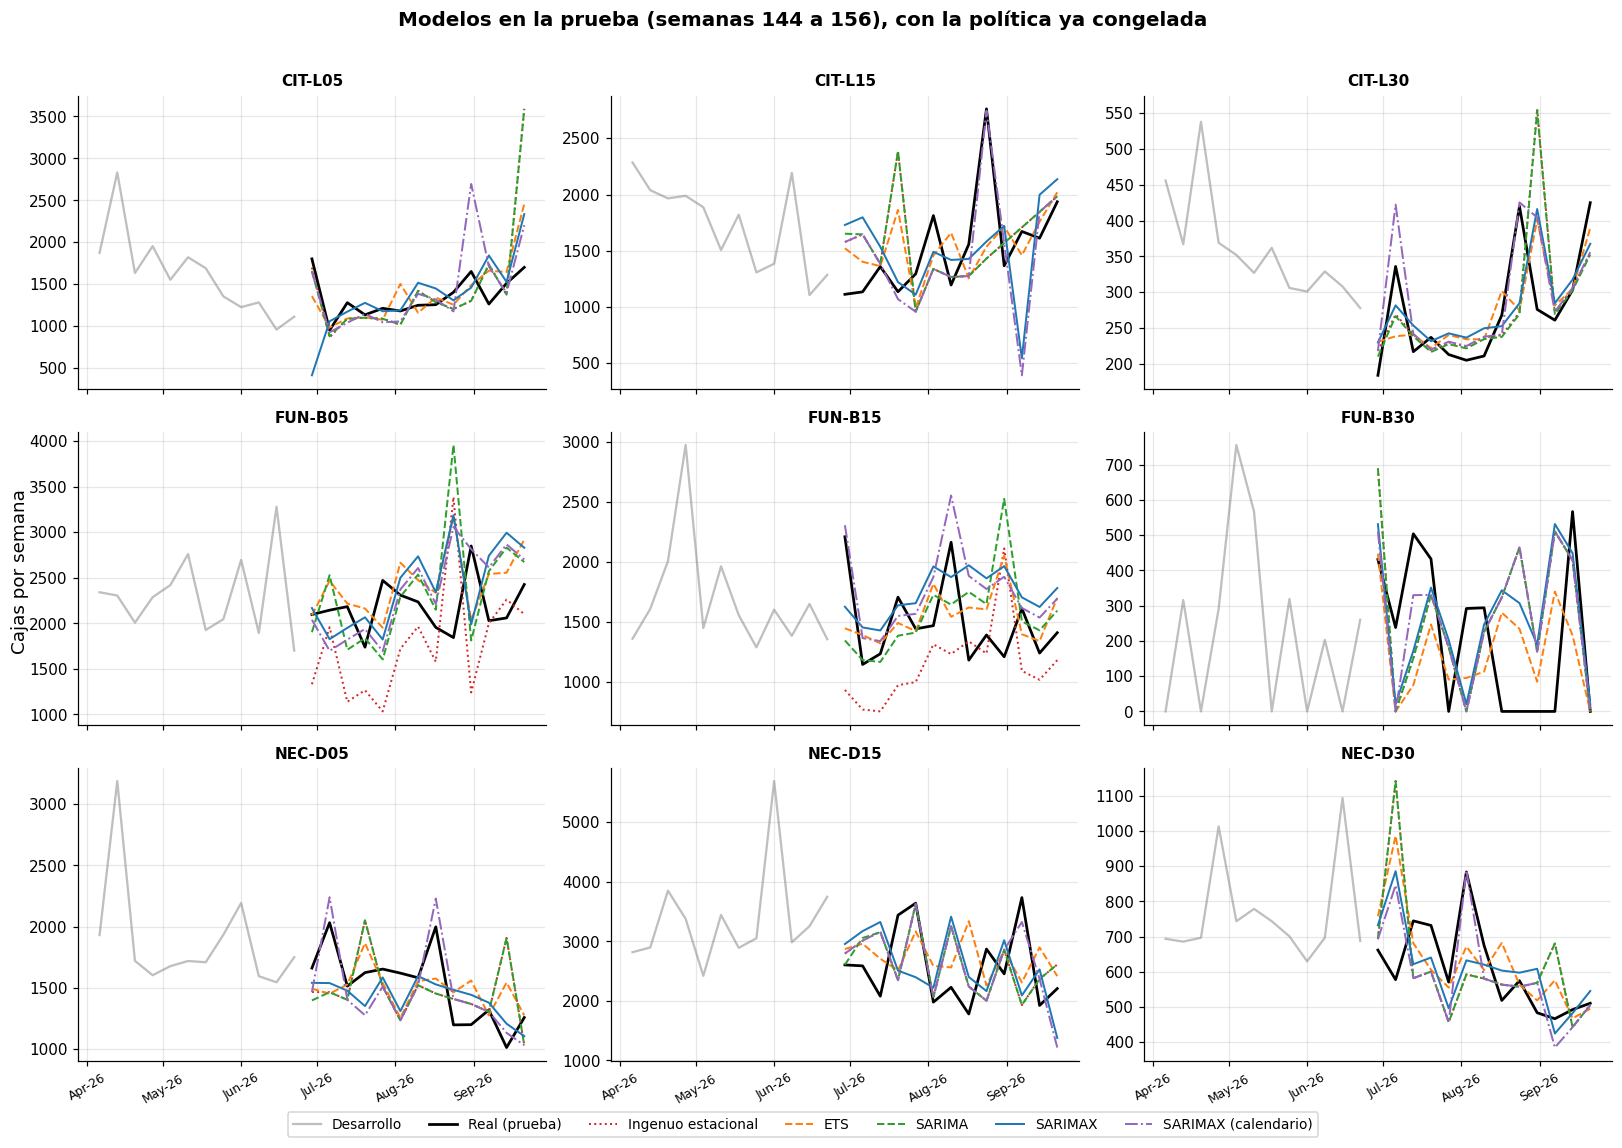

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [58]:
# Gráfico de los modelos en la prueba: SOLO después de congelar la política (corrección 2)
preds_modelos = {}
for sku in skus:
    y_tr = train[sku]
    x_tr, x_te = promo.loc[:FIN_TRAIN, [sku]].values, leer_prueba(promo, f"gráfico prueba {sku}")[[sku]].values
    preds_modelos[sku] = {"Ingenuo estacional": pron_naive_est(y_tr, H), "ETS": pron_ets(y_tr, H, etiqueta="ETS (gráfico prueba)")}
    preds_modelos[sku].update(pron_sarimas(y_tr, H, ordenes_cv[sku][0], ordenes_cv[sku][1], x_tr, x_te, sufijo=" (gráfico prueba)"))

colores_m = {"Ingenuo estacional": "tab:red", "ETS": "tab:orange", "SARIMA": "tab:green", "SARIMAX": "tab:blue", "SARIMAX (calendario)": "tab:purple"}
estilos_m = {"Ingenuo estacional": ":", "ETS": "--", "SARIMA": "--", "SARIMAX": "-", "SARIMAX (calendario)": "-."}
fechas_test = fechas.loc[FIN_TRAIN + 1:]
fig, ejes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    hist = train[sku].iloc[-12:]
    ax.plot(fechas.loc[hist.index], hist.values, color="gray", alpha=0.5, label="Desarrollo")
    ax.plot(fechas_test, real_t[sku].values, color="black", lw=1.8, label="Real (prueba)")
    for modelo, pred in preds_modelos[sku].items():
        ax.plot(fechas_test, pred, color=colores_m[modelo], ls=estilos_m[modelo], lw=1.3, label=modelo)
    ax.set_title(sku, fontsize=10, fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
h_, l_ = ejes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=7, fontsize=9, frameon=True, bbox_to_anchor=(0.5, -0.02))
fig.supylabel("Cajas por semana")
plt.suptitle("Modelos en la prueba (semanas 144 a 156), con la política ya congelada", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.9 Pronóstico final a 13 semanas por SKU (coherente, con intervalos al 80 % y 95 %)

Con la política congelada se reentrena con **toda** la historia (semanas 1 a 156): órdenes re-elegidos con esas
156 semanas y cuotas de las semanas 105 a 156. Los intervalos usan la **regla congelada**, estimada con los
errores fuera de muestra del desarrollo. Las 13 semanas son el horizonte táctico de la Entrega 2: del 28/09/2026
al 21/12/2026.

In [59]:
ULTIMA = int(niveles.index.max())
ordenes_fin = {}
for uid in SERIES:
    y_u = niveles[uid].copy(); y_u.name = uid
    ordenes_fin[uid] = (elegir_orden(y_u) if MODELO_BASE == "SARIMA" else None,
                        elegir_orden(y_u, promo_niv[[uid]].values) if MODELO_BASE.startswith("SARIMAX") else None)

n_reg_antes = len(registro_ajustes)
base_fin = pd.DataFrame({uid: pron_base(uid, ULTIMA, ordenes_fin) for uid in SERIES}, index=range(1, H + 1))
ajustes_finales = pd.DataFrame(registro_ajustes[n_reg_antes:])
pron_rec = reconciliar(base_fin, *proporciones(ULTIMA))[METODO_ELEGIDO]

dif = max((pron_rec[skus_de[f]].sum(axis=1) - pron_rec[f]).abs().max() for f in familias)
dif = max(dif, (pron_rec[skus].sum(axis=1) - pron_rec["Planta"]).abs().max())
assert dif < 1e-6, "El pronóstico final no es coherente"
print(f"Modelo: {MODELO_BASE} | método: {METODO_ELEGIDO} | regla de intervalo: {METODO_IP} | coherencia: {dif:.1e}")
print("Ajustes del pronóstico final convergidos:", int(ajustes_finales["convergio"].sum()) if len(ajustes_finales) else 0, "de", len(ajustes_finales))

fechas_fut = [fechas.iloc[-1] + pd.Timedelta(weeks=h) for h in range(1, H + 1)]
pts_f = pd.DataFrame([{"serie": u, "h": h, "yhat": pron_rec.loc[h, u]} for u in SERIES for h in range(1, H + 1)])
for nivel in NIVELES_IP:
    lo, hi = np.zeros(len(pts_f)), np.zeros(len(pts_f))
    for metodo in set(metodo_ip_serie.values()):
        m_ = pts_f["serie"].map(metodo_ip_serie) == metodo
        lo[m_.values], hi[m_.values] = limites_ip(metodo, err_el, pts_f[m_], nivel)
    pts_f[f"inf_{int(100 * nivel)}"], pts_f[f"sup_{int(100 * nivel)}"] = lo, hi
pts_f["sigma_h"] = [sigma_dev.loc[h, u] for u, h in zip(pts_f["serie"], pts_f["h"])]
pts_f["sesgo_h"] = [sesgo_dev.loc[h, u] for u, h in zip(pts_f["serie"], pts_f["h"])]
pts_f["regla_intervalo"] = pts_f["serie"].map(metodo_ip_serie)
pts_f["nivel"] = pts_f["serie"].map(nivel_de)
pts_f["semana"] = ULTIMA + pts_f["h"]
pts_f["fecha_lunes"] = [fechas_fut[h - 1].date() for h in pts_f["h"]]
pronostico_final = pts_f.rename(columns={"h": "t", "yhat": "pronostico"})[
    ["nivel", "serie", "t", "semana", "fecha_lunes", "pronostico", "inf_80", "sup_80", "inf_95", "sup_95",
     "sigma_h", "sesgo_h", "regla_intervalo"]]
pronostico_final.to_csv(os.path.join(R, "pronostico_final.csv"), index=False)

tabla_sku = pron_rec[skus].copy(); tabla_sku.index = [d.date() for d in fechas_fut]
print("=== PRONÓSTICO FINAL POR SKU (cajas por semana) ===")
display(tabla_sku.round(0))
tabla_fam = pron_rec[familias + ["Planta"]].copy(); tabla_fam.index = tabla_sku.index
print("=== FAMILIAS Y PLANTA (suma de los SKU) ===")
display(tabla_fam.round(0))
comp = pd.DataFrame({"pronostico_13s": pron_rec[skus].sum(), "año_anterior_13s": niveles.loc[ULTIMA - 51:ULTIMA - 39, skus].sum(),
                     "13 x media_ultimas_52s": 13 * niveles.loc[ULTIMA - 51:, skus].mean()})
comp["variacion_vs_año_anterior_%"] = 100 * (comp["pronostico_13s"] / comp["año_anterior_13s"] - 1)
display(comp.round(1))

Modelo: SARIMAX | método: Middle-out | regla de intervalo: Cuantiles empíricos | coherencia: 0.0e+00
Ajustes del pronóstico final convergidos: 13 de 13
=== PRONÓSTICO FINAL POR SKU (cajas por semana) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
2026-09-28,1647.0,1851.0,362.0,2023.0,1438.0,188.0,1260.0,2227.0,515.0
2026-10-05,2249.0,2527.0,495.0,2567.0,1826.0,239.0,1180.0,2086.0,482.0
2026-10-12,2062.0,2316.0,454.0,2248.0,1599.0,209.0,1144.0,2022.0,467.0
2026-10-19,1955.0,2197.0,430.0,2808.0,1996.0,261.0,1136.0,2008.0,464.0
2026-10-26,2386.0,2681.0,525.0,2284.0,1624.0,212.0,1165.0,2059.0,476.0
2026-11-02,2532.0,2845.0,557.0,2417.0,1719.0,225.0,1315.0,2324.0,537.0
2026-11-09,2317.0,2604.0,510.0,2639.0,1877.0,245.0,1177.0,2079.0,480.0
2026-11-16,2216.0,2490.0,488.0,2041.0,1451.0,190.0,1127.0,1991.0,460.0
2026-11-23,2419.0,2717.0,532.0,2831.0,2013.0,263.0,957.0,1691.0,391.0
2026-11-30,2800.0,3145.0,616.0,2085.0,1482.0,194.0,1181.0,2087.0,482.0


=== FAMILIAS Y PLANTA (suma de los SKU) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CIT,FUN,NEC,Planta
2026-09-28,3861.0,3649.0,4001.0,11511.0
2026-10-05,5272.0,4631.0,3748.0,13651.0
2026-10-12,4832.0,4056.0,3634.0,12521.0
2026-10-19,4583.0,5065.0,3608.0,13256.0
2026-10-26,5592.0,4121.0,3701.0,13413.0
2026-11-02,5935.0,4361.0,4177.0,14473.0
2026-11-09,5431.0,4761.0,3736.0,13927.0
2026-11-16,5194.0,3682.0,3578.0,12453.0
2026-11-23,5669.0,5108.0,3038.0,13815.0
2026-11-30,6561.0,3761.0,3751.0,14072.0


,pronostico_13s,año_anterior_13s,13 x media_ultimas_52s,variacion_vs_año_anterior_%
CIT-L05,30489.6,29055.0,25581.0,4.9
CIT-L15,34253.2,36298.0,28738.8,-5.6
CIT-L30,6708.2,6323.0,5628.2,6.1
FUN-B05,32583.0,32154.0,32249.0,1.3
FUN-B15,23168.7,22168.0,22931.2,4.5
FUN-B30,3027.2,1625.4,2996.2,86.2
NEC-D05,15426.6,15331.0,19808.2,0.6
NEC-D15,27257.1,26473.0,34999.0,3.0
NEC-D30,6300.3,6252.0,8089.8,0.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** El pronóstico es **coherente**: la suma de los SKU es exactamente cada familia y la Planta.
Para las 13 semanas (28/09 a 21/12/2026) la Planta suma **≈ 179.200 cajas**, igual que en la v1: las correcciones
cambian cómo se valida y cómo se mide la incertidumbre, no el pronóstico puntual. CIT sube hacia diciembre, FUN
crece y NEC se mantiene. Contra las mismas semanas del año anterior, ocho SKU quedan dentro de ±7 %; la excepción
es **FUN-B30 (+86 %)**: middle-out le asigna su cuota media dentro de FUN y la forma de la familia, y esas semanas
del año anterior fueron especialmente bajas para este SKU intermitente. La columna «13 × media de las últimas 52
semanas» muestra que su pronóstico es coherente con su nivel anual reciente. Conviene revisarlo con Comercial.

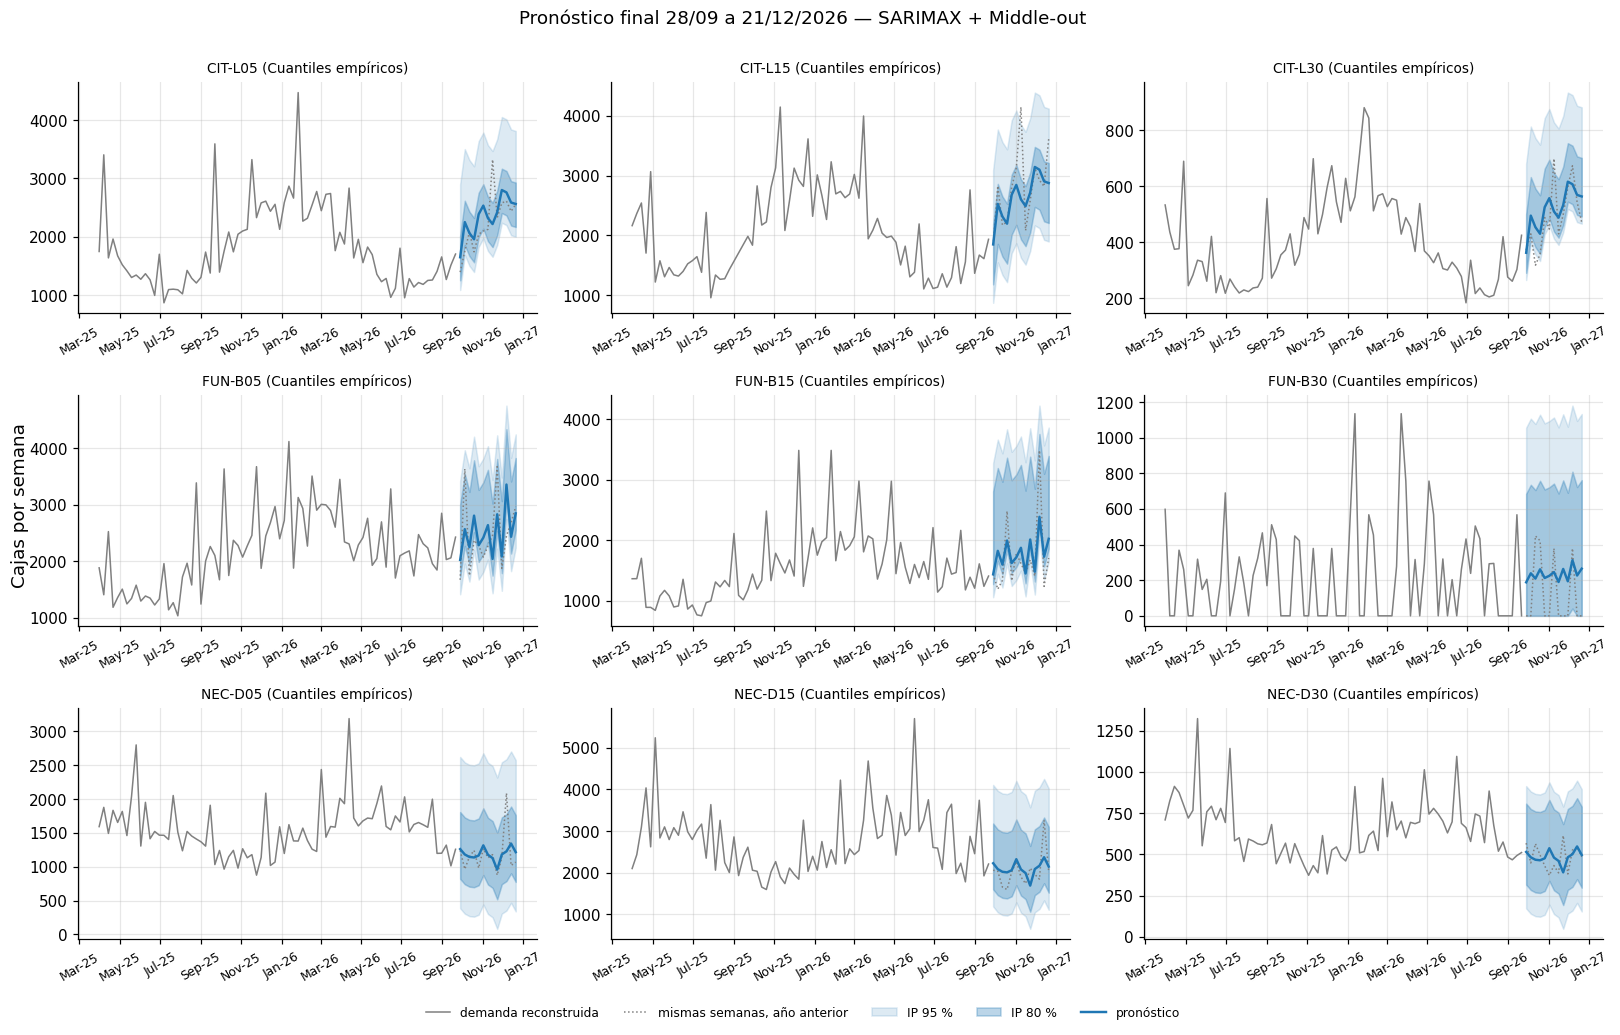

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [60]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 9))
for ax, sku in zip(ejes.flatten(), skus):
    d = pronostico_final[pronostico_final["serie"] == sku]
    fx = pd.to_datetime(d["fecha_lunes"])
    hist_sku = niveles[sku].loc[ULTIMA - 77:]
    ax.plot(fechas.loc[hist_sku.index], hist_sku.values, color="gray", lw=1, label="demanda reconstruida")
    ax.plot(fechas.loc[ULTIMA - 51:ULTIMA - 39] + pd.Timedelta(weeks=52), niveles.loc[ULTIMA - 51:ULTIMA - 39, sku].values,
            color="gray", ls=":", lw=1, label="mismas semanas, año anterior")
    ax.fill_between(fx, d["inf_95"], d["sup_95"], color="tab:blue", alpha=0.15, label="IP 95 %")
    ax.fill_between(fx, d["inf_80"], d["sup_80"], color="tab:blue", alpha=0.30, label="IP 80 %")
    ax.plot(fx, d["pronostico"], color="tab:blue", lw=1.6, label="pronóstico")
    ax.set_title(f"{sku} ({metodo_ip_serie[sku]})", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
h_, l_ = ejes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.supylabel("Cajas por semana")
plt.suptitle(f"Pronóstico final 28/09 a 21/12/2026 — {MODELO_BASE} + {METODO_ELEGIDO}", y=1.0)
plt.tight_layout()
plt.show()

### 4.10 De la incertidumbre al stock de seguridad y a la capacidad (con merma por línea)

La Entrega 2 usará $\hat\sigma_{i,h}$ para el stock de seguridad. La cadena completa es:

1. $SS_{i,t} = z_{NS_i}\,\hat\sigma_{i,t}$ en **cajas vendibles**, con $z_{NS_i} = \Phi^{-1}(NS_i)$ y el nivel de
   servicio objetivo de `inventario_inicial.csv` (95 % en CIT y NEC, 92 % en FUN). El *lead time* del jarabe es
   1 semana, así que la protección de la semana $t$ usa el horizonte $h = t$.
2. Si el pronóstico tiene sesgo, la cobertura del cuantil exige $SS_{i,t} = z\,\hat\sigma_{i,t} - \hat b_{i,t}$
   (con $e = \hat y - y$, un sesgo negativo, es decir subestimar, **suma** stock).
3. Para tener esas cajas **vendibles** hay que producir $SS/(1-\rho_\ell)$ según la línea de envasado.
4. Constituir ese stock consume, una vez, **horas de envasado** (cajas / tasa de la línea) y **litros de jarabe**
   en la mezcladora (litros por caja + jarabe extra por sobrellenado vigente, 3.5); después solo se repone lo
   que se consume.

La tabla compara el stock de seguridad con el estimador nuevo y con el de la v1.

In [61]:
rho_linea = {l: d["n_defectuosas"].sum() / d["n_inspeccionadas"].sum() for l, d in cartas_p.items()}
L_extra_fmt = (d_vig.groupby("formato_L")["volumen_mL"].mean() - esp["nominal_mL"]) * bxc_fmt / 1000
assert (inv["lead_time_jarabe_semanas"] == 1).all(), "El cálculo supone lead time de 1 semana"

filas = []
for s in skus:
    ns = inv.loc[s, "nivel_servicio_objetivo"]
    z = stats.norm.ppf(ns)
    linea, fmt = mst.loc[s, "linea_envasado"], mst.loc[s, "formato_L"]
    rho = rho_linea[linea]
    ss_de = z * sigma_dev[s]                                   # por t = h = 1..13
    ss_de_sesgo = (z * sigma_dev[s] - sesgo_dev[s]).clip(lower=0)
    ss_v1 = z * sigma_v1[s]
    prod = ss_de.mean() / (1 - rho)
    filas.append({"sku": s, "linea": linea, "NS": ns, "z": z, "rho_linea": rho,
                  "SS medio DE (cajas vendibles)": ss_de.mean(), "SS medio DE + sesgo": ss_de_sesgo.mean(),
                  "SS medio v1 (RMSE suav.)": ss_v1.mean(), "v1 / DE": ss_v1.mean() / ss_de.mean(),
                  "SS DE a producir (cajas)": prod, "horas para constituir el SS": prod / mst.loc[s, "tasa_envasado_cajas_h"],
                  "litros de jarabe del SS": prod * (mst.loc[s, "litros_por_caja"] + L_extra_fmt[fmt]),
                  "SS medio con σ̂ obs. original": (z * sigma_obs[s]).mean(),
                  "SS DE / pronóstico medio %": 100 * ss_de.mean() / pron_rec[s].mean()})
stock_seguridad = pd.DataFrame(filas).set_index("sku")
display(stock_seguridad.round(2))
tot_ss = stock_seguridad[["SS medio DE (cajas vendibles)", "SS medio DE + sesgo", "SS medio v1 (RMSE suav.)",
                          "SS medio con σ̂ obs. original", "SS DE a producir (cajas)", "horas para constituir el SS",
                          "litros de jarabe del SS"]].sum()
print("Totales de los 9 SKU (nivel medio del stock de seguridad en las 13 semanas):")
display(tot_ss.round(1).to_frame("total").T)
print("Capacidad que consume constituir el stock de seguridad, por línea:")
display(stock_seguridad.groupby("linea")[["SS DE a producir (cajas)", "horas para constituir el SS", "litros de jarabe del SS"]].sum().round(1))

,linea,NS,z,rho_linea,SS medio DE (cajas vendibles),SS medio DE + sesgo,SS medio v1 (RMSE suav.),v1 / DE,SS DE a producir (cajas),horas para constituir el SS,litros de jarabe del SS,SS medio con σ̂ obs. original,SS DE / pronóstico medio %
sku,,,,,,,,,,,,,
CIT-L05,L1,0.95,1.64,0.02,724.82,762.92,756.46,1.04,739.02,4.11,4484.85,4680.36,30.90
CIT-L15,L2,0.95,1.64,0.03,719.17,602.79,1127.42,1.57,742.29,3.53,6701.30,719.17,27.29
CIT-L30,L2,0.95,1.64,0.03,166.97,193.86,196.06,1.17,172.33,1.33,2073.57,166.97,32.36
FUN-B05,L1,0.92,1.41,0.02,667.50,976.91,853.75,1.28,680.57,3.78,4130.16,667.50,26.63
FUN-B15,L2,0.92,1.41,0.03,782.74,1126.30,965.00,1.23,807.90,3.85,7293.60,782.74,43.92
FUN-B30,L2,0.92,1.41,0.03,505.17,531.32,497.43,0.98,521.41,4.01,6273.78,505.17,216.94
NEC-D05,L1,0.95,1.64,0.02,695.35,719.28,780.42,1.12,708.97,3.94,4302.49,695.35,58.60
NEC-D15,L2,0.95,1.64,0.03,1192.32,1273.40,1196.12,1.00,1230.65,5.86,11110.18,1192.32,56.87
NEC-D30,L2,0.95,1.64,0.03,267.36,245.47,295.72,1.11,275.96,2.12,3320.37,267.36,55.17


Totales de los 9 SKU (nivel medio del stock de seguridad en las 13 semanas):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,SS medio DE (cajas vendibles),SS medio DE + sesgo,SS medio v1 (RMSE suav.),SS medio con σ̂ obs. original,SS DE a producir (cajas),horas para constituir el SS,litros de jarabe del SS
total,5721.4,6432.2,6668.4,9676.9,5879.1,32.5,49690.3


Capacidad que consume constituir el stock de seguridad, por línea:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,SS DE a producir (cajas),horas para constituir el SS,litros de jarabe del SS
linea,,,
L1,2128.6,11.8,12917.5
L2,3750.5,20.7,36772.8


**Lectura de resultados (stock de seguridad).** Con la σ̂ nueva, el stock de seguridad medio de los 9 SKU es
**≈ 5.720 cajas vendibles**, 14 % menos que con el RMSE suavizado de la v1 (≈ 6.670): la v1 cargaba el sesgo y el
suavizado como si fueran variabilidad. Si además se cubre el sesgo ($z\hat\sigma - \hat b$) sube a ≈ 6.430, sobre
todo en FUN-B05 y FUN-B15 (+46 % y +44 %), que el modelo subestima. Con la σ̂ medida contra la observación original
de CIT-L05 sería ≈ 9.680: el atípico no confirmado sumaría por sí solo ≈ 4.000 cajas de stock de un SKU.

Llevado a producción con $1/(1-\rho_\ell)$ son **≈ 5.880 cajas**, que consumen **≈ 33 horas de envasado** (12 en L1
y 21 en L2) y **≈ 50.000 L de jarabe** para constituirlo una vez. FUN-B30 necesita un stock de 2,2 veces su
pronóstico medio: su incertidumbre supera a su demanda, y es el SKU donde un método para demanda intermitente
tendría más valor.

## 5. Parte C — Tabla de traspaso a la Entrega 2

La Entrega 2 usará estos parámetros **literalmente**. Cada uno sale de una celda anterior y se guarda en
`resultados/`. Al final se consolidan en una sola tabla larga (`traspaso_consolidado.csv`) con parámetro,
clave, período de origen de los datos, unidad, método y archivo, y se verifica su integridad.

**C1. Tasa de merma efectiva $\rho_\ell$ por línea** (carta p). Proporción defectuosa de **todas** las
inspecciones de las 10 semanas, incluido el episodio de la semana 8 en L2. El plan produce $x/(1-\rho_\ell)$
para obtener $x$ cajas vendibles. **Supuesto explícito:** toda botella defectuosa se trata como no vendible en
el plan (cota conservadora). Como no se conoce el destino de cada defecto, se entregan dos sensibilidades: la
tasa estable de Fase I (sin el episodio) y la tasa si las fallas cuya causa principal es «Etiqueta» se
reprocesan.

In [62]:
filas = []
for linea_nom, d in cartas_p.items():
    insp = d["n_inspeccionadas"].sum()
    rho = d["n_defectuosas"].sum() / insp
    rho_sin_etq = d.loc[d["causa_principal"] != "Etiqueta", "n_defectuosas"].sum() / insp
    filas.append([linea_nom, rho, d["p_bar"].iloc[0], rho_sin_etq, 1 / (1 - rho), 100 / (1 - rho)])
c1 = pd.DataFrame(filas, columns=["linea", "rho_efectiva", "rho_estable_FaseI", "rho_si_etiqueta_se_reprocesa",
                                  "factor_produccion_1/(1-rho)", "producir_por_100_vendibles"])
display(c1.round(4))

,linea,rho_efectiva,rho_estable_FaseI,rho_si_etiqueta_se_reprocesa,factor_produccion_1/(1-rho),producir_por_100_vendibles
0,L1,0.0192,0.0186,0.0146,1.0196,101.9594
1,L2,0.0311,0.0261,0.0196,1.0321,103.2147


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** $\rho_{L1}$ = **1,92 %** y $\rho_{L2}$ = **3,11 %**: para entregar 100 cajas vendibles hay
que producir **102,0 cajas en L1 y 103,2 en L2**. Sensibilidades: sin el episodio de la semana 8, $\rho_{L2}$ = 2,61 %;
si las fallas con causa principal «Etiqueta» se reprocesan, 1,46 % en L1 y 1,96 % en L2. El plan base usa la tasa
efectiva porque no se conoce el destino de cada defecto.

**C2. Sobrellenado medio por formato y litros de jarabe adicionales por caja.** Caso base: escenario
**vigente** (Fase II), porque el corrimiento de L1 sigue activo. Se agregan los escenarios A (recentrado) y B
(σ reducida + recentrado) de 3.5, para que la Entrega 2 pueda recalcular la restricción de la mezcladora si se
ejecuta alguna de esas acciones. Litros extra por caja = mL extra por botella × botellas por caja / 1000.

In [63]:
nominales = esp["nominal_mL"]
c2 = pd.DataFrame({
    "sobrellenado_vigente_mL": d_vig.groupby("formato_L")["volumen_mL"].mean() - nominales,
    "sobrellenado_10sem_mL": llen.groupby("formato_L")["volumen_mL"].mean() - nominales,
    "botellas_por_caja": bxc_fmt})
c2["L_jarabe_extra_por_caja"] = c2["sobrellenado_vigente_mL"] * c2["botellas_por_caja"] / 1000
c2["L_jarabe_extra_por_caja_10sem"] = c2["sobrellenado_10sem_mL"] * c2["botellas_por_caja"] / 1000
esc_piv = escenarios_sobrellenado.pivot(index="formato_L", columns="escenario", values="L_jarabe_extra_por_caja")
c2["L_extra_por_caja_esc_A_recentrado"] = esc_piv["A: recentrado"]
c2["L_extra_por_caja_esc_B_sigma_reducida"] = esc_piv["B: σ reducida + recentrado"]
c2.index.name = "formato_L"
assert np.allclose(c2["L_jarabe_extra_por_caja"], esc_piv["Hoy (vigente)"], atol=CONFIG["tol"]), "C2 no coincide con 3.5"
display(c2.round(4))

,sobrellenado_vigente_mL,sobrellenado_10sem_mL,botellas_por_caja,L_jarabe_extra_por_caja,L_jarabe_extra_por_caja_10sem,L_extra_por_caja_esc_A_recentrado,L_extra_por_caja_esc_B_sigma_reducida
formato_L,,,,,,,
0.5,5.7198,4.0936,12,0.0686,0.0491,0.0041,0.0
1.5,4.6455,4.6011,6,0.0279,0.0276,0.0279,0.0
3.0,8.0724,8.5012,4,0.0323,0.0340,0.0315,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Lectura de resultados.** Sobrellenado vigente: **0,5 L: +5,72 mL por botella → 0,069 L de jarabe extra por caja;
1,5 L: +4,65 mL → 0,028 L/caja; 3,0 L: +8,07 mL → 0,032 L/caja**. En la Entrega 2 se suma al consumo de jarabe en la
restricción de la mezcladora. Si se ejecuta el escenario A (recentrar L1), el valor de 0,5 L baja a 0,004 L/caja; el
escenario B lleva los tres formatos a 0.

**C3. Pronóstico puntual $\hat d_{it}$** ($t = 1$ es la semana del 28/09/2026), en cajas por semana.
**C4. Desviación estándar del error $\hat\sigma_{i,h}$** por SKU y horizonte, en cajas, con la definición de
4.6 (DE muestral, ddof = 1, sin suavizar). **C4b. Sesgo $\hat b_{i,h}$** por SKU y horizonte (cajas; positivo =
el modelo sobrestima). El stock de seguridad de la Entrega 2 es $SS_{it} = z_{NS_i}\hat\sigma_{i,t}$ (o
$z\hat\sigma - \hat b$ si se decide cubrir el sesgo), llevado a producción con $1/(1-\rho_\ell)$ (4.10). El RMSE
suavizado de la v1 se guarda solo como referencia comparativa.

In [64]:
c3 = pron_rec[skus].copy(); c3.index.name = "t"
c4 = sigma_dev[skus].copy(); c4.index.name = "h"
c4b = sesgo_dev[skus].copy(); c4b.index.name = "h"
c4_ref_v1 = sigma_v1[skus].copy(); c4_ref_v1.index.name = "h"
print("C3. Pronóstico puntual (cajas por semana)"); display(c3.round(0))
print("C4. Desviación estándar del error de pronóstico, DE ddof = 1 (cajas)"); display(c4.round(0))
print("C4b. Sesgo del error por horizonte (cajas; + = sobrestima)"); display(c4b.round(0))
print("σ̂ medio como % del pronóstico medio:")
display((100 * c4.mean() / c3.mean()).round(1).to_frame("sigma_medio_%").T)

c1.to_csv(os.path.join(R, "traspaso_C1_merma.csv"), index=False)
c2.to_csv(os.path.join(R, "traspaso_C2_sobrellenado.csv"))
c3.to_csv(os.path.join(R, "traspaso_C3_pronostico.csv"))
c4.to_csv(os.path.join(R, "traspaso_C4_sigma.csv"))
c4b.to_csv(os.path.join(R, "traspaso_C4b_sesgo.csv"))
c4_ref_v1.to_csv(os.path.join(R, "referencia_v1_rmse_suavizado.csv"))
sigma_obs[skus].rename_axis("h").to_csv(os.path.join(R, "referencia_C4_sigma_objetivo_original.csv"))

C3. Pronóstico puntual (cajas por semana)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
t,,,,,,,,,
1,1647.0,1851.0,362.0,2023.0,1438.0,188.0,1260.0,2227.0,515.0
2,2249.0,2527.0,495.0,2567.0,1826.0,239.0,1180.0,2086.0,482.0
3,2062.0,2316.0,454.0,2248.0,1599.0,209.0,1144.0,2022.0,467.0
4,1955.0,2197.0,430.0,2808.0,1996.0,261.0,1136.0,2008.0,464.0
5,2386.0,2681.0,525.0,2284.0,1624.0,212.0,1165.0,2059.0,476.0
6,2532.0,2845.0,557.0,2417.0,1719.0,225.0,1315.0,2324.0,537.0
7,2317.0,2604.0,510.0,2639.0,1877.0,245.0,1177.0,2079.0,480.0
8,2216.0,2490.0,488.0,2041.0,1451.0,190.0,1127.0,1991.0,460.0
9,2419.0,2717.0,532.0,2831.0,2013.0,263.0,957.0,1691.0,391.0


C4. Desviación estándar del error de pronóstico, DE ddof = 1 (cajas)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


serie,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
h,,,,,,,,,
1,541.0,496.0,88.0,489.0,689.0,290.0,298.0,673.0,113.0
2,419.0,846.0,149.0,452.0,180.0,391.0,232.0,393.0,222.0
3,405.0,476.0,117.0,340.0,725.0,399.0,728.0,783.0,139.0
4,570.0,219.0,97.0,592.0,602.0,304.0,313.0,664.0,139.0
5,440.0,619.0,131.0,559.0,400.0,385.0,227.0,431.0,233.0
6,388.0,426.0,89.0,263.0,731.0,397.0,770.0,966.0,141.0
7,540.0,223.0,90.0,363.0,647.0,310.0,318.0,673.0,131.0
8,301.0,560.0,120.0,695.0,526.0,395.0,232.0,427.0,214.0
9,395.0,416.0,84.0,336.0,472.0,405.0,710.0,975.0,123.0


... (3 outputs left out)

σ̂ medio como % del pronóstico medio:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


serie,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
sigma_medio_%,18.8,16.6,19.7,19.0,31.3,154.4,35.6,34.6,33.5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Tabla de traspaso (resumen).**

| Parámetro | Valor | Origen | Uso en la Entrega 2 |
|---|---|---|---|
| $\rho_{L1}$, $\rho_{L2}$ | 1,92 % y 3,11 % (sensibilidades en C1) | Carta p, 10 semanas | Producir $x/(1-\rho_\ell)$ |
| Sobrellenado por formato | 0,069 / 0,028 / 0,032 L de jarabe por caja (0,5 / 1,5 / 3,0 L); escenarios A y B en C2 | Fase II vigente | Capacidad de mezcla |
| $\hat d_{it}$ | Tabla C3, 9 SKU × 13 semanas | SARIMAX + middle-out | Demanda del lot-sizing |
| $\hat\sigma_{i,h}$ | Tabla C4, 9 SKU × 13 horizontes (DE muestral, ddof = 1) | Errores fuera de muestra del origen deslizante | Stock de seguridad $z_{NS}\hat\sigma_{i,h}$ |
| $\hat b_{i,h}$ | Tabla C4b, 9 SKU × 13 horizontes | Ídem | Corrección opcional del sesgo: $z\hat\sigma - \hat b$ |

Todo queda además en `traspaso_consolidado.csv`, verificado en la celda siguiente.

**Tabla de traspaso consolidada y su verificación.** Una fila por parámetro y clave, con el período de origen
de los datos, la unidad, el método y el archivo. Se verifica: 9 SKU × 13 semanas = **117** registros en C3, C4 y
C4b, sin claves duplicadas ni vacíos; que la suma de C3 por familia y por Planta sea igual al pronóstico
reconciliado; y que $\rho_\ell \in (0, 1)$.

In [65]:
f_ini, f_fin = pd.to_datetime(llen["fecha"]).min().date(), pd.to_datetime(llen["fecha"]).max().date()
periodo_atr = f"Inspecciones {pd.to_datetime(atr['fecha']).min().date()} a {pd.to_datetime(atr['fecha']).max().date()} (semanas 1 a 10)"
periodo_f2 = f"Llenado Fase II, semanas {FASE1 + 1} a {int(llen['semana_registro'].max())} (hasta {f_fin})"
periodo_dem = f"Demanda reconstruida semanas 1 a {ULTIMA} ({fechas.iloc[0].date()} a {fechas.iloc[-1].date()})"
periodo_err = f"Errores fuera de muestra, orígenes {ORIGENES[0]} a {ORIGENES[-1]} (semanas evaluadas {ORIGENES[0] + 1} a {ORIGENES[-1] + H})"

filas = []
for _, r_ in c1.iterrows():
    filas.append({"parametro": "C1 rho (merma efectiva)", "linea": r_["linea"], "formato_L": np.nan, "sku": None, "t_o_h": np.nan,
                  "fecha_lunes": None, "valor": r_["rho_efectiva"], "unidad": "fracción de cajas producidas",
                  "periodo_origen": periodo_atr, "metodo": "Carta p, todas las inspecciones", "archivo": "traspaso_C1_merma.csv"})
for fmt, r_ in c2.iterrows():
    filas.append({"parametro": "C2 jarabe extra por caja", "linea": "L1" if fmt == 0.5 else "L2", "formato_L": fmt, "sku": None,
                  "t_o_h": np.nan, "fecha_lunes": None, "valor": r_["L_jarabe_extra_por_caja"], "unidad": "L de jarabe por caja producida",
                  "periodo_origen": periodo_f2, "metodo": "(media Fase II − nominal) × botellas por caja / 1000",
                  "archivo": "traspaso_C2_sobrellenado.csv"})
for nombre, tabla, unidad, periodo, metodo, archivo in [
        ("C3 pronóstico", c3, "cajas por semana", periodo_dem, f"{MODELO_BASE} + {METODO_ELEGIDO}", "traspaso_C3_pronostico.csv"),
        ("C4 sigma del error", c4, "cajas", periodo_err, "DE muestral (ddof = 1) por SKU y horizonte, error contra demanda limpia", "traspaso_C4_sigma.csv"),
        ("C4b sesgo del error", c4b, "cajas (+ = sobrestima)", periodo_err, "Media de los errores por SKU y horizonte", "traspaso_C4b_sesgo.csv")]:
    for t in tabla.index:
        for s in skus:
            filas.append({"parametro": nombre, "linea": mst.loc[s, "linea_envasado"], "formato_L": mst.loc[s, "formato_L"], "sku": s,
                          "t_o_h": int(t), "fecha_lunes": fechas_fut[int(t) - 1].date() if nombre.startswith("C3") else None,
                          "valor": tabla.loc[t, s], "unidad": unidad, "periodo_origen": periodo, "metodo": metodo, "archivo": archivo})
traspaso = pd.DataFrame(filas)
traspaso.to_csv(os.path.join(R, "traspaso_consolidado.csv"), index=False)

verif_traspaso = []
for p in ["C3 pronóstico", "C4 sigma del error", "C4b sesgo del error"]:
    d = traspaso[traspaso["parametro"] == p]
    verif_traspaso.append({"parametro": p, "registros": len(d), "esperados": len(skus) * H,
                           "claves duplicadas": int(d.duplicated(["sku", "t_o_h"]).sum()), "vacíos": int(d["valor"].isna().sum())})
verif_traspaso = pd.DataFrame(verif_traspaso)
c3_largo = traspaso[traspaso["parametro"] == "C3 pronóstico"]
suma_fam = c3_largo.assign(familia=c3_largo["sku"].map(familia_de)).pivot_table(index="t_o_h", columns="familia", values="valor", aggfunc="sum")
dif_fam = (suma_fam[familias].values - pron_rec.loc[suma_fam.index, familias].values)
dif_planta = c3_largo.groupby("t_o_h")["valor"].sum().values - pron_rec["Planta"].values
display(verif_traspaso)
print(f"Máx. diferencia C3 vs familia: {np.abs(dif_fam).max():.1e} | vs Planta: {np.abs(dif_planta).max():.1e}")
print(f"Planta 13 semanas: {c3_largo['valor'].sum():,.0f} cajas")
display(traspaso.groupby("parametro").agg(registros=("valor", "size"), unidad=("unidad", "first"), periodo_origen=("periodo_origen", "first")))

,parametro,registros,esperados,claves duplicadas,vacíos
0,C3 pronóstico,117,117,0,0
1,C4 sigma del error,117,117,0,0
2,C4b sesgo del error,117,117,0,0


Máx. diferencia C3 vs familia: 9.1e-13 | vs Planta: 3.6e-12
Planta 13 semanas: 179,214 cajas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,registros,unidad,periodo_origen
parametro,,,
C1 rho (merma efectiva),2,fracción de cajas producidas,Inspecciones 2026-07-20 a 2026-09-25 (semanas ...
C2 jarabe extra por caja,3,L de jarabe por caja producida,"Llenado Fase II, semanas 6 a 10 (hasta 2026-09..."
C3 pronóstico,117,cajas por semana,Demanda reconstruida semanas 1 a 156 (2023-10-...
C4 sigma del error,117,cajas,"Errores fuera de muestra, orígenes 109 a 130 (..."
C4b sesgo del error,117,cajas (+ = sobrestima),"Errores fuera de muestra, orígenes 109 a 130 (..."


## 6. Verificaciones programadas (fuga, partición, convergencia, trazabilidad) y cifras clave

Cada línea es una comprobación con **tolerancia explícita** (corrección 5). Si alguna falla, la ejecución se
detiene con el motivo. Las comprobaciones nuevas de esta versión cubren cada corrección del informe.

In [66]:
chequeos = []
TOL = CONFIG["tol"]
def chequear(descripcion, condicion, detalle=""):
    assert bool(condicion), "FALLÓ: " + descripcion + (f" — {detalle}" if detalle else "")
    chequeos.append({"chequeo": descripcion, "resultado": "OK", "detalle": detalle})

# ---------- datos crudos
chequear("calidad_llenado.csv no fue modificado", leer("calidad_llenado.csv").equals(llen_raw))
chequear("calidad_atributos.csv no fue modificado", leer("calidad_atributos.csv").equals(atr_raw))
chequear("demanda_semanal.csv no fue modificado", leer("demanda_semanal.csv").equals(dem_raw))

# ---------- Parte A
for (l, f), lim in lims.items():
    chequear(f"Límites X̄–R {l} {f} L calculados solo con Fase I", sg[sg["subgrupo"].isin(lim["subgrupos_estables"])]["semana"].max() <= FASE1)
chequear("Orden temporal: turno C de madrugada corregido (orden = número de subgrupo)", orden_coincide,
         f"{int(madrugada.sum())} subgrupos ajustados")
chequear("Cada exclusión de Fase I está registrada con ronda, criterio y estado de causa",
         len(traza) == res["excluidos"].sum() and traza["criterio"].ne("").all() and traza["estado_causa"].notna().all(),
         f"{len(traza)} exclusiones")
chequear("Sensibilidad con/sin exclusión calculada para las 3 cartas", sensibilidad_fase1["carta"].nunique() == len(cartas))
chequear("Capacidad calculada solo con subgrupos de Fase I",
         all(set(llen[llen["subgrupo"].isin(lims[k]["subgrupos_estables"])]["semana_registro"]) <= set(range(1, FASE1 + 1)) for k in lims))
for l, d in cartas_p.items():
    f1u = d[d["en_fase1_usada"]]
    chequear(f"p̄ de la carta p {l} = defectuosas/inspeccionadas de las inspecciones de Fase I usadas (exacto)",
             abs(d["p_bar"].iloc[0] - f1u["n_defectuosas"].sum() / f1u["n_inspeccionadas"].sum()) < TOL)
chequear("Recentrar no logra Cpk 1,33 cuando Cp < 1,33 (escenario A coherente)",
         all((r_["A: Cpk resultante"] < CONFIG["cpk_objetivo"]) and (r_["A: Cpk resultante"] <= r_["Cp_hoy"] + TOL)
             for _, r_ in recuperable.iterrows() if r_["Cp_hoy"] < CONFIG["cpk_objetivo"]))
chequear("Escenario B alcanza Cpk = 1,33", np.allclose(recuperable["B: Cpk resultante"], CONFIG["cpk_objetivo"], atol=1e-6))

# ---------- Parte B: aislamiento de la prueba y fuga
for o in ORIGENES:
    chequear(f"Limpieza causal: truncar los datos en el origen {o} no cambia la serie limpia hasta {o}",
             limpiar_ventas(ventas.loc[:o])[1].equals(limpia.loc[:o]))
chequear("Todo diagnóstico de modelado usa solo el desarrollo", max(diagnostico_hasta.values()) <= FIN_DES,
         str(diagnostico_hasta))
chequear("Objetivo de validación = observación original (atípicos sin reemplazar)",
         np.allclose(cv["y"].values, [demanda_obs.loc[o + h, s] for s, o, h in zip(cv["sku"], cv["origen"], cv["h"])], atol=TOL))
chequear("Ningún pliegue del origen deslizante toca la prueba", cv["origen"].max() + H <= FIN_TRAIN)
chequear("Al menos 8 ventanas y h = 13", cv["origen"].nunique() >= 8 and cv["h"].max() == H)
chequear("Órdenes de validación elegidos con datos hasta el primer origen", SEMANA_SELECCION <= min(ORIGENES) and set(ordenes_cv) == set(SERIES))
chequear("Toda cuota jerárquica usa solo las 52 semanas previas a su origen",
         all(r_["hasta"] <= r_["origen"] and r_["semanas"] == CONFIG["semanas_proporcion"] for r_ in registro_cuotas),
         f"{len(registro_cuotas)} cálculos de cuotas")
chequear("Evaluación de la jerarquía solo dentro del desarrollo", errores["origen"].max() + H <= FIN_TRAIN)
chequear("Modelo elegido = mínimo WAPE recalculado con los pliegues del desarrollo",
         MODELO_BASE == cv[cv["modelo"].isin(ELEGIBLES)].groupby("modelo")[["e", "y"]].apply(wape, "e", "y").idxmin())
chequear("Método jerárquico elegido = mínimo WAPE SKU con los pliegues del desarrollo",
         METODO_ELEGIDO == errores[(errores["nivel"] == "SKU") & (errores["metodo"] != METODOS[0])].groupby("metodo")[["e", "y"]].apply(wape, "e", "y").idxmin())
chequear("La prueba se abrió solo después de congelar la política", _PRUEBA["hash_politica"] is not None and len(_PRUEBA["accesos"]) > 0,
         f"{len(_PRUEBA['accesos'])} lecturas de la prueba")
chequear("La política no cambió después de abrir la prueba (hash SHA-256 idéntico)",
         hashlib.sha256(json.dumps(POLITICA, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest() == _PRUEBA["hash_politica"])

# ---------- Parte B: convergencia (sin advertencias ocultas)
reg = pd.DataFrame(registro_ajustes)
reg_cv = reg[reg["origen"].isin(ORIGENES)]
frac_nc = 1 - reg_cv["convergio"].mean()
chequear("Ajustes de la validación no convergidos bajo la tolerancia", frac_nc <= CONFIG["max_frac_no_convergencia"],
         f"{100 * frac_nc:.2f} % de {len(reg_cv)} ajustes")
chequear("Todos los ajustes de la prueba y del pronóstico final convergieron",
         reg[reg["origen"].isin([FIN_TRAIN, ULTIMA])]["convergio"].all(), f"{reg['origen'].isin([FIN_TRAIN, ULTIMA]).sum()} ajustes")
chequear("Sin ajustes con excepción", len(fallos) == 0, str(fallos[:3]))

# ---------- Parte B: incertidumbre
chequear("σ̂ = DE muestral (ddof = 1) por serie y horizonte, sin suavizar",
         np.allclose(sigma_dev.values, err_el.groupby(["h", "serie"])["e"].std(ddof=1).unstack().values, atol=TOL))
chequear("RMSE² = (n−1)/n·DE² + sesgo² (el sesgo se reporta aparte)", descomp < 1e-6)
chequear("σ̂ finita y positiva en las 117 celdas SKU × h", np.isfinite(c4.values).all() and (c4.values > 0).all())
chequear("σ̂ con la observación original solo difiere en las celdas que contienen el atípico",
         set(sens_sigma.index.get_level_values("sku")) <= set(skus_atip), f"{len(sens_sigma)} celdas")
chequear("Pronóstico final coherente (familias y Planta = suma de SKU)", dif < 1e-6, f"{dif:.1e}")
chequear("Pronóstico e intervalos no negativos y ordenados",
         (pron_rec >= 0).all().all() and (pronostico_final["inf_95"] >= 0).all()
         and (pronostico_final["inf_95"] <= pronostico_final["inf_80"] + TOL).all()
         and (pronostico_final["sup_80"] <= pronostico_final["sup_95"] + TOL).all())

# ---------- Parte C
for _, r_ in verif_traspaso.iterrows():
    chequear(f"{r_['parametro']}: 117 registros, sin duplicados ni vacíos",
             r_["registros"] == r_["esperados"] == 117 and r_["claves duplicadas"] == 0 and r_["vacíos"] == 0)
chequear("C3 suma por familia y por Planta = pronóstico reconciliado", np.abs(dif_fam).max() < 1e-6 and np.abs(dif_planta).max() < 1e-6)
chequear("ρ por línea en (0, 1)", c1["rho_efectiva"].between(0, 1, inclusive="neither").all())
chequear("Requisitos de la ejecución registrados", os.path.exists(os.path.join(R, "requirements_ejecucion.txt")))

tabla_chequeos = pd.DataFrame(chequeos)
display(tabla_chequeos)
print(f"{len(chequeos)} comprobaciones superadas.")

,chequeo,resultado,detalle
0,calidad_llenado.csv no fue modificado,OK,
1,calidad_atributos.csv no fue modificado,OK,
2,demanda_semanal.csv no fue modificado,OK,
3,Límites X̄–R L1 0.5 L calculados solo con Fase I,OK,
4,Límites X̄–R L2 1.5 L calculados solo con Fase I,OK,
5,Límites X̄–R L2 3.0 L calculados solo con Fase I,OK,
6,Orden temporal: turno C de madrugada corregido...,OK,150 subgrupos ajustados
7,Cada exclusión de Fase I está registrada con r...,OK,12 exclusiones
8,Sensibilidad con/sin exclusión calculada para ...,OK,
9,Capacidad calculada solo con subgrupos de Fase I,OK,


48 comprobaciones superadas.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [67]:
l1 = tabla_cap[(tabla_cap["linea"] == "L1") & (tabla_cap["grupo"] == "Global")].iloc[0]
rec_l1 = recuperable.set_index("carta").loc["L1 0.5 L"]
cifras_clave = {
    "L1 0,5 L: corrimiento de la media Fase I -> Fase II (mL)": tabla_f2.iloc[0]["media"] - l1["media"],
    "L1 0,5 L: % subgrupos de Fase II con señal": tabla_we[(tabla_we["carta"] == "L1 0.5 L") & (tabla_we["fase"] == "II")]["% con señal"].iloc[0],
    "Fase I: subgrupos excluidos (causa no confirmada)": len(traza),
    "Fase I depurada: subgrupos con señal WE que persisten": int(persisten.sum()),
    "L1 0,5 L: Cp / Cpk Fase I": f"{l1['Cp']:.2f} / {l1['Cpk']:.2f}",
    "L1 0,5 L: Ppk Fase II": tabla_f2.iloc[0]["Ppk"],
    "L2 1,5 L: Cp / Cpk Fase I": "{:.2f} / {:.2f}".format(*tabla_cap[(tabla_cap["linea"] == "L2") & (tabla_cap["formato"] == 1.5) & (tabla_cap["grupo"] == "Global")][["Cp", "Cpk"]].iloc[0]),
    "L2 3,0 L: Cp / Cpk Fase I": "{:.2f} / {:.2f}".format(*tabla_cap[(tabla_cap["linea"] == "L2") & (tabla_cap["formato"] == 3.0) & (tabla_cap["grupo"] == "Global")][["Cp", "Cpk"]].iloc[0]),
    "Cumple OIML R87 en todas las combinaciones": bool(tabla_legal["cumple_R87"].all()),
    "Merma rho L1 / L2 (%)": "{:.2f} / {:.2f}".format(*(100 * c1["rho_efectiva"].values)),
    "Sobrellenado vigente (régimen actual): litros/año": tot_planta.loc[ESC_F2, "litros_anio"],
    "Sobrellenado vigente (régimen actual): MM CLP/año": tot_planta.loc[ESC_F2, "valor_MM_CLP"],
    "Sobrellenado vigente, rango según base de volumen (MM CLP/año)": "{:.1f} a {:.1f}".format(
        matriz_eco.xs(ESC_F2, level="escenario")["valor_MM_CLP"].min(), matriz_eco.xs(ESC_F2, level="escenario")["valor_MM_CLP"].max()),
    "Escenario A L1 (recentrar): ahorro MM CLP/año / Cpk resultante": f"{rec_l1['A: ahorro MM CLP/año']:.1f} / {rec_l1['A: Cpk resultante']:.2f}",
    "Escenario B L1 (σ a Cp 1,33): reducción de σ % / ahorro total MM CLP/año": f"{rec_l1['B: reducción sigma %']:.1f} / {rec_l1['B: ahorro total MM CLP/año']:.1f}",
    "FUN-B30: demanda perdida por quiebres en el desarrollo (% de la venta)": tabla_censura.loc["FUN-B30", "incremento_%"],
    "Modelo elegido / WAPE validación vs observación original (%)": f"{MODELO_BASE} / {global_cv.loc[MODELO_BASE, 'WAPE_%']:.1f}",
    "WAPE benchmark ingenuo estacional (%)": global_cv.loc["Ingenuo estacional", "WAPE_%"],
    "Selección robusta al tratamiento del atípico": modelo_si_objetivo_limpio == MODELO_BASE and metodo_si_limpio == METODO_ELEGIDO,
    "Método jerárquico elegido / WAPE SKU (%)": f"{METODO_ELEGIDO} / {tab_jer[(tab_jer['nivel'] == 'SKU') & (tab_jer['metodo'] == METODO_ELEGIDO)]['WAPE_%'].iloc[0]:.1f}",
    "Prueba 144-156: WAPE SKU elegido vs benchmark (%)": "{:.1f} vs {:.1f}".format(
        prueba[(prueba["metodo"] == METODO_ELEGIDO) & (prueba["nivel"] == "SKU")]["WAPE_%"].iloc[0],
        prueba[(prueba["metodo"].str.startswith("Benchmark")) & (prueba["nivel"] == "SKU")]["WAPE_%"].iloc[0]),
    "Regla de intervalo (elegida en desarrollo)": METODO_IP,
    "Cobertura LOO desarrollo IP 80 / 95 % (%)": "{:.0f} / {:.0f}".format(*cob_loo.loc[METODO_IP].iloc[:2].values),
    "Cobertura prueba IP 80 / 95 % (%)": "{:.0f} / {:.0f}".format(*cobertura_prueba.loc[METODO_IP].values),
    "Cobertura prueba IP 80 / 95 % con el estimador v1 (%)": "{:.0f} / {:.0f}".format(*cobertura_prueba.loc["RMSE suavizado (v1)"].values),
    "Stock de seguridad medio semanal, 9 SKU: DE vs v1 (cajas)": "{:,.0f} vs {:,.0f}".format(
        tot_ss["SS medio DE (cajas vendibles)"], tot_ss["SS medio v1 (RMSE suav.)"]),
    "Pronóstico Planta 13 semanas (cajas)": pron_rec["Planta"].sum(),
    "Ajustes de validación no convergidos (%)": 100 * frac_nc,
}
cifras_df = pd.DataFrame({"valor": {k: (f"{v:,.2f}" if isinstance(v, (float, np.floating)) else str(v)) for k, v in cifras_clave.items()}})
display(cifras_df)
cifras_df.to_csv(os.path.join(R, "cifras_clave.csv"))

,valor
"L1 0,5 L: corrimiento de la media Fase I -> Fase II (mL)",3.25
"L1 0,5 L: % subgrupos de Fase II con señal",100.00
Fase I: subgrupos excluidos (causa no confirmada),12
Fase I depurada: subgrupos con señal WE que persisten,11
"L1 0,5 L: Cp / Cpk Fase I",1.28 / 0.88
"L1 0,5 L: Ppk Fase II",0.38
"L2 1,5 L: Cp / Cpk Fase I",1.01 / 0.72
"L2 3,0 L: Cp / Cpk Fase I",1.01 / 0.66
Cumple OIML R87 en todas las combinaciones,True
Merma rho L1 / L2 (%),1.92 / 3.11


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Conclusiones para la gerencia

**Queja 1: «Calidad dice que el proceso está bajo control, pero Finanzas ve merma».** Las dos cosas son ciertas a la
vez. *Bajo control* significa *predecible*, no *dentro de especificación*. L2 es predecible (con reservas: persisten
rachas ligadas al turno C) pero incapaz (Cp ≈ 1,0). L1 era casi capaz pero descentrado, y desde el 24/08 además está
corrido +3,25 mL. Ninguna línea incumple la ley (OIML R87 se cumple con holgura). La merma tiene dos componentes:
- **Sobrellenado:** ≈ 32.800 L de jarabe al año, **≈ 21,1 MM CLP** a costo variable en el caso base (18,7 a 21,3 MM
  según la base de volumen). **Recentrar L1 recupera ≈ 13,0 MM CLP** con una acción barata, pero **no cumple la meta
  de capacidad**: deja Cpk = 1,22, y llegar a 1,33 exige además bajar σ un 4 %. Los ≈ 7,3 MM CLP de L2 exigen reducir
  σ ≈ 24 %, empezando por el turno C, que regala ≈ 3,7 MM CLP al año. **Ahorro y capacidad son metas distintas.**
- **Defectuosas:** 1,92 % en L1 y 3,11 % en L2. El problema crónico se reparte entre sello, etiqueta y nivel de
  llenado, más un episodio de etiquetas en la semana 8. No se valorizan como producto perdido sin conocer su destino.
- Las causas propuestas (reajuste de L1 el 24/08; práctica del turno C) son **hipótesis respaldadas por asociación
  estadística**. Deben confirmarse con la bitácora de mantención y los registros de ajuste por turno.

**Queja 2: «Comercial pronostica y Planificación no le cree».** Se entrega **un solo pronóstico** por SKU: SARIMAX con
promoción + reconciliación middle-out, coherente en Planta → Familia → SKU, validado sin fuga contra las
observaciones originales (WAPE 23,4 % a nivel SKU) y confirmado en la prueba (22,8 % contra 27,9 % del ingenuo) con
la política congelada antes de abrirla. La selección no depende del tratamiento del atípico. El error que queda
viene sobre todo de no conocer el calendario de promociones (≈ 2,8 puntos de WAPE y un sesgo de −230 a −1.530 cajas
en esas semanas): compartirlo es la razón económica para trabajar con un mismo número.

**Incertidumbre para la Entrega 2.** $\hat\sigma_{i,h}$ es la desviación estándar muestral del error por SKU y
horizonte (C4), con el sesgo aparte (C4b). El stock de seguridad resultante es ≈ 5.700 cajas vendibles (14 % menos
que con el estimador de la v1) y ≈ 5.900 a producir con la merma de cada línea. En la prueba, los intervalos de
FUN-B05 y FUN-B15 quedaron cortos: hay que vigilarlos.

### Decisiones metodológicas

| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Carta X̄–R | X̄–S | n = 5 constante; el rango es eficiente para n ≤ 10 |
| Fase I por rondas, con registro y sensibilidad | Exclusión silenciosa | La causa no está confirmada: se documenta y se muestra que las conclusiones no cambian |
| ANOVA turno + SKU con errores agrupados por turno | ANOVA de un factor | Separa turno de SKU y admite dependencia dentro de un turno |
| Carta p con p̄ de Fase I | np, o p̄ con las 10 semanas | n variable; el episodio de la semana 8 inflaría los límites |
| Sobrellenado vigente, régimen actual, con matriz de bases | Un solo número | Los supuestos de volumen quedan explícitos |
| Ahorro (recentrar) separado de capacidad (reducir σ) | «Recentrar logra Cpk 1,33» | Cpk nunca supera a Cp |
| Atípicos con nivel del pasado; reemplazo solo en entrenamiento | Reemplazar también en validación | La validación se mide contra el dato original |
| Demanda = venta × 7/(7−d) | Ventas como demanda | Las ventas están censuradas (FUN-B30 +50 %) |
| Diagnóstico y regresores solo con el desarrollo | Usar las 156 semanas | Aísla la prueba |
| Solo promoción como regresor | Promoción + precio | Correlación 0,98 en el desarrollo |
| Promoción futura = frecuencia esperada | Calendario real | No existe calendario futuro |
| Órdenes con semanas 1 a 109; solo ajustes convergidos | Todo el desarrollo; ignorar convergencia | Sin fuga; AIC confiable |
| Middle-out | Bottom-up, top-down | Menor WAPE SKU; las familias no comparten fase |
| σ̂ = DE (ddof = 1) por h, sesgo aparte, sin suavizar | RMSE suavizado y monótono | Definición explícita (corrección 1) |
| Regla de intervalo elegida por LOO en el desarrollo y congelada | Elegirla mirando la prueba | Evita fuga |

### Limitaciones declaradas
- El sobrellenado anual usa ventas como volumen; con la merma ρ la cifra real es ≈ 2 a 3 % mayor.
- Las causas asignables (Parte A) y los atípicos de demanda no tienen confirmación operacional o comercial; ambos se
  acompañan de sensibilidad.
- σ̂ por horizonte se estima con 8 errores (error de muestreo ≈ 27 %).
- En la prueba los intervalos de FUN quedan cortos, y SARIMAX está sesgado a la baja (−9,7 %). ETS, con menos sesgo
  y casi el mismo WAPE, es la alternativa natural si la Entrega 2 penaliza más el quiebre que el inventario.
- FUN-B30 combina censura e intermitencia; Croston o TSB quedan como mejora propuesta.

## 8. Exportación de resultados

Esta celda deja **todo lo que produjo el cuaderno** en `resultados/`:

| Archivo o carpeta | Contenido |
|---|---|
| `traspaso_C1` a `C4b`, `traspaso_consolidado.csv` | Parámetros para la Entrega 2 |
| `pronostico_final.csv` | Pronóstico de las 13 series con intervalos, σ̂, sesgo y regla de intervalo |
| `politica_congelada.json` | Política de modelado y su hash SHA-256 |
| `registro_exclusiones_fase1.csv`, `registro_ajustes_convergencia.csv`, `registro_cuotas_jerarquicas.csv` | Trazabilidad |
| `comprobaciones.csv`, `cifras_clave.csv`, `config_ejecucion.json`, `requirements_ejecucion.txt` | Verificación y reproducibilidad |
| `figuras/`, `tablas/`, `resultados.zip` | Figuras PNG, tablas CSV y todo comprimido |

In [68]:
R = CONFIG["carpeta_resultados"]
registro_ajustes_df = pd.DataFrame(registro_ajustes)
bitacora_df = pd.DataFrame(bitacora)
registro_cuotas_df = pd.DataFrame(registro_cuotas)
registro_ajustes_df.to_csv(os.path.join(R, "registro_ajustes_convergencia.csv"), index=False)
bitacora_df.to_csv(os.path.join(R, "bitacora_datos.csv"), index=False)
tabla_anom.to_csv(os.path.join(R, "bitacora_anomalias_demanda.csv"), index=False)
registro_cuotas_df.to_csv(os.path.join(R, "registro_cuotas_jerarquicas.csv"), index=False)
tabla_chequeos.to_csv(os.path.join(R, "comprobaciones.csv"), index=False)

guardadas = []
for nombre, obj in list(globals().items()):
    if (isinstance(obj, pd.DataFrame) and not nombre.startswith("_") and not nombre.endswith("_raw")
            and 0 < len(obj) <= 3000 and nombre not in ("llen", "atr", "dem", "d", "dd", "f1u")):
        obj.to_csv(os.path.join(R, "tablas", f"{nombre}.csv"), index=obj.index.name is not None or not isinstance(obj.index, pd.RangeIndex))
        guardadas.append(nombre)
print(f"{len(guardadas)} tablas guardadas en {R}/tablas/")

requeridos = ["traspaso_C1_merma.csv", "traspaso_C2_sobrellenado.csv", "traspaso_C3_pronostico.csv", "traspaso_C4_sigma.csv",
              "traspaso_C4b_sesgo.csv", "traspaso_consolidado.csv", "pronostico_final.csv", "cifras_clave.csv",
              "config_ejecucion.json", "politica_congelada.json", "registro_ajustes_convergencia.csv",
              "registro_exclusiones_fase1.csv", "requirements_ejecucion.txt", "comprobaciones.csv"]
faltan_arch = [a for a in requeridos if not os.path.exists(os.path.join(R, a))]
assert not faltan_arch, f"Faltan archivos de resultados: {faltan_arch}"
print(f"{len([f for f in os.listdir(os.path.join(R, 'figuras')) if f.endswith('.png')])} figuras en {R}/figuras/")

zip_ruta = shutil.make_archive("resultados", "zip", R)
print("Archivo comprimido:", os.path.abspath(zip_ruta))
if CONFIG["copiar_a_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    destino = os.path.join("/content/drive/MyDrive", CONFIG["carpeta_drive"])
    shutil.copytree(R, destino, dirs_exist_ok=True)
    print("Copiado a Google Drive:", destino)

172 tablas guardadas en resultados/tablas/
20 figuras en resultados/figuras/
Archivo comprimido: /content/resultados.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Para llevarte los archivos: en Colab, panel de archivos → clic derecho sobre `resultados.zip` →
*Descargar*. O ejecuta, solo en Colab, `from google.colab import files; files.download("resultados.zip")`.